<a href="https://colab.research.google.com/github/U4CSE24060/Historical_places/blob/main/ChronoGraph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. ChronoGraph: Temporal Graph Neural Networks for Knowledge Evolution
**A reproducible six-model research prototype · PyTorch + PyTorch Geometric**

**Abstract.** This notebook compares static, recurrent, graph-recurrent, memory, and attention-based representations for temporal knowledge graphs. ChronoGraph combines relation-aware graph attention, functional time encoding, entity-wise temporal attention and a persistence head. Evaluation separates frozen-origin future-link forecasting from held-out past-fact completion and studies relation/time prediction, emerging entities, expiry proxies, ablations, robustness and efficiency. It generates complete logs, checkpoints, paper-ready tables and 300-DPI figures.

**Read before running.** The included outputs come from the actual CPU quick experiment. They are a smoke test, not a state-of-the-art claim. RE-NET-style and TGN-style are adaptations. ICEWS recurrence does not establish real-world fact validity; explicit validity labels are supplied in the synthetic dataset. Raw IDs are not linked to invented news events.

**How to run:** install dependencies below, edit `CONFIG`, then choose **Run All**. Definitions appear in the requested ten sections; the single `run_all(CONFIG)` entry point executes every stage after all definitions have loaded. No local project imports are required. The companion project contains the same definitions as normal Python modules.

In [ ]:
%pip install "torch-geometric>=2.6,<3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 18.3 MB/s eta 0:00:00


In [ ]:
# requirements.txt cell — no silent installation. Set INSTALL_DEPENDENCIES=True if needed.
import sys, subprocess, importlib.util
from pathlib import Path
INSTALL_DEPENDENCIES = False
REQUIREMENTS = 'torch>=2.4,<3\ntorch-geometric>=2.6,<3\nnumpy>=1.26,<3\npandas>=2.2,<4\nscipy>=1.12,<2\nscikit-learn>=1.4,<2\nmatplotlib>=3.8,<4\nnbformat>=5.10,<6\nnbclient>=0.10,<1\nipykernel>=6.29,<8\njupyterlab>=4.2,<5\ntensorboard>=2.17,<3\ntabulate>=0.9,<1\npython-docx>=1.1,<2\nreportlab>=4.2,<5\npytest>=8,<10\nipywidgets>=8.1,<9\n'
Path("requirements.txt").write_text(REQUIREMENTS)
if INSTALL_DEPENDENCIES:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"])
missing = [x for x in ["torch","torch_geometric","numpy","pandas","sklearn","scipy","matplotlib","tabulate"] if importlib.util.find_spec(x) is None]
if missing:
    raise ImportError(f"Missing {missing}. Run: {sys.executable} -m pip install -r requirements.txt")
print("Dependencies ready. CUDA is optional.")

Dependencies ready. CUDA is optional.


In [ ]:
from __future__ import annotations
import copy
import hashlib
import importlib.metadata
import json
import os
import random
import subprocess
import sys
import urllib.request
from dataclasses import asdict, dataclass, replace
from pathlib import Path
from typing import Any, Iterator
import numpy as np
import pandas as pd
import torch
from torch import Tensor, nn
from torch_geometric.data import Data
import math
from typing import Any
from torch.nn import functional as F
from torch_geometric.nn import GATConv, RGCNConv
import gc
import time
import traceback
from dataclasses import asdict, replace
from scipy.stats import ttest_rel
from sklearn.metrics import f1_score, roc_auc_score
from dataclasses import replace
import textwrap
from dataclasses import asdict,replace
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score,roc_auc_score
from IPython.display import display, Markdown, Image
matplotlib.use("Agg")

# 2. Config, registry contract and reproducibility
The six registry keys are `distmult`, `ttranse`, `gru_seq`, `renet`, `tgn`, `chronograph`; their classes are registered in section 5. All models share splits, seeds, negative-generation rules and optimization-budget policies. Model-specific selected settings are listed in `best_configs.csv`. Trial candidates are identical across architectures; selection uses validation only.

Quick mode keeps **3 seeds, 3 trials/model and all 6 models**. It caps the graph/query workload, uses four main epochs and two stress epochs, and evaluates stress arms with one seed. GPU scatter/reduction operations may still be nondeterministic; warn-only deterministic mode and a same-seed assertion are included.

In [ ]:
@dataclass
class Config:
    """Shared budgets; quick mode is an engineering smoke test, not a benchmark claim."""
    root: str = "."
    dataset: str = "icews14"
    custom_path: str = ""
    quick_mode: bool = True
    device: str = "auto"
    seeds: tuple[int, ...] = (11, 29, 47)
    data_seed: int = 2026
    dim: int = 64
    lr: float = 0.003
    dropout: float = 0.1
    gnn_layers: int = 1
    history: int = 3
    negatives: int = 8
    weight_decay: float = 0.0001
    epochs: int = 4
    tune_epochs: int = 2
    trials: int = 3
    patience: int = 3
    batch_size: int = 32
    accumulation: int = 1
    clip: float = 1.0
    smoothness: float = 0.0001
    validity_weight: float = 0.25
    horizons: tuple[int, ...] = (1, 3, 7, 14)
    max_train_times: int = 10
    max_eval_queries: int = 60
    max_timestamps: int = 80
    max_entities: int = 64
    max_relations: int = 6
    facts_per_time: int = 24
    amp: bool = False
    deterministic: bool = True
    num_threads: int = 1
    loader_mode: str = "snapshot"
    run_extended: bool = True
    tensorboard: bool = True
    no_time: bool = False
    no_temporal: bool = False
    no_structure: bool = False

    def resolved(self) -> "Config":
        c = replace(self)
        if not c.quick_mode:
            c.epochs, c.tune_epochs, c.trials = 60, 10, 10
            c.patience, c.batch_size = 8, 256
            c.max_train_times = c.max_eval_queries = 0
            c.max_timestamps = c.max_entities = c.max_relations = c.facts_per_time = 0
        if c.device == "auto":
            c.device = "cuda" if torch.cuda.is_available() else "cpu"
        c.root = str(Path(c.root).resolve())
        return c

def seed_all(seed: int, deterministic: bool = True, threads: int = 1) -> None:
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(deterministic, warn_only=True)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = False

def write_json(path: Path, value: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    def clean(v: Any) -> Any:
        if isinstance(v, dict): return {str(k): clean(x) for k, x in v.items()}
        if isinstance(v, (list, tuple)): return [clean(x) for x in v]
        if isinstance(v, (np.integer, np.floating)): v = v.item()
        if isinstance(v, float) and not np.isfinite(v): return None
        if isinstance(v, Path): return str(v)
        return v
    path.write_text(json.dumps(clean(value), indent=2), encoding="utf-8")

def environment() -> dict[str, Any]:
    versions = {}
    for p in ["torch", "torch-geometric", "numpy", "pandas", "scipy", "scikit-learn"]:
        try: versions[p] = importlib.metadata.version(p)
        except importlib.metadata.PackageNotFoundError: versions[p] = "unavailable"
    try:
        git_hash = subprocess.check_output(["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL, text=True).strip()
    except Exception: git_hash = None
    return {"python": sys.version, "versions": versions, "git_hash": git_hash,
            "cuda": torch.cuda.is_available(), "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}

In [ ]:
CONFIG = Config(
    root="/content",
    dataset="chronography",
    custom_path="/content/chronography.csv",
    quick_mode=True,
    device="auto",
)


# 3. Data loading, preprocessing and leakage audit
The loader uses the public RE-Net/Know-Evolve ICEWS14 variant, which has train and test files but no validation file. It pools and deduplicates the source, fixes chronological 60/20/20 boundaries, and selects the quick subset using training-era frequency only. A separate 10% within-training holdout is reserved for interpolation. `.pt` snapshot caches use split fingerprints.

Histories are strictly earlier than the query and include training observations only. Test labels are used only for metric filters and evaluation targets. Filters are restricted to **exactly the query time**. Negatives use entities already observed by that time and reject observed same-time positives. UNK rows are trained through ID dropout; unseen IDs share these rows. A known evaluation catalog is assumed.

Fact persistence horizons count retained snapshots. Actual elapsed source time is also passed to the head. Labels beyond a partition boundary are censored. ICEWS/custom event labels mean recurrence; synthetic state labels mean validity. Fractional numeric timestamps are supported through the event API.

In [ ]:
def generate_synthetic(directory: Path, seed: int = 2026, n: int = 64, steps: int = 80) -> pd.DataFrame:
    """Fully observed valid states, with expiry, object switches, drift, and late arrivals."""
    rng = np.random.default_rng(seed)
    rows, changes = [], []
    for t in range(steps):
        active = n - 12 if t < steps * 0.65 else n
        for s in range(active):
            # Persistent association changes after a regime boundary.
            for r in range(4):
                if r == 2 and (t + s) % 12 >= 5: continue  # explicit expiration
                if r == 3 and rng.random() > (0.12 if t < steps // 2 else 0.7): continue
                offset = [1, 7, 3, 11][r]
                regime = (t // 16) if r in (0, 3) else 0
                o = (s + offset + regime * 3) % active
                rows.append((f"person_{s:03d}", ["affiliated_with", "collaborates_with", "holds_role", "discusses"][r], f"person_{o:03d}", float(t)))
        if t % 16 == 0:
            changes.append({"time": t, "event": "Programmed affiliation/discussion regime switch", "synthetic": True})
    directory.mkdir(parents=True, exist_ok=True)
    frame = pd.DataFrame(rows, columns=["subject", "relation", "object", "time"])
    frame.to_csv(directory / "facts.csv", index=False)
    write_json(directory / "events.json", changes)
    write_json(directory / "metadata.json", {"seed": seed, "semantics": "fully_observed_valid_state",
        "entity_birth": "last 12 entities enter at 65% of the timeline", "expiry": "holds_role active for 5 out of 12 steps",
        "license": "CC0-1.0 for these generated data", "time_unit": "synthetic step"})
    return frame

In [ ]:
def load_facts(cfg: Config) -> tuple[pd.DataFrame, dict[str, Any]]:
    base = Path(cfg.root) / "data"
    if cfg.dataset == "synthetic":
        return generate_synthetic(base / "synthetic", cfg.data_seed), {"dataset": "synthetic", "semantics": "valid_state", "unit": "step"}
    if cfg.custom_path:
        frame = pd.read_csv(cfg.custom_path)
        required = ["subject", "relation", "object", "time"]
        assert set(required).issubset(frame), f"CSV requires {required}"
        if not pd.api.types.is_numeric_dtype(frame.time):
            ts = pd.to_datetime(frame.time, utc=True)
            frame["time"] = (ts - ts.min()).dt.total_seconds() / 86400
        return frame[required], {"dataset": cfg.dataset, "semantics": "event_recurrence_proxy", "unit": "custom timestamp unit"}
    folder = {"icews14": "ICEWS14", "icews18": "ICEWS18", "gdelt": "GDELT", "wiki": "WIKI"}.get(cfg.dataset)
    if folder is None: raise ValueError("Use icews14, icews18, gdelt, wiki, synthetic, or supply custom_path")
    raw = base / cfg.dataset / "raw"
    raw.mkdir(parents=True, exist_ok=True)
    source, parts = [], []
    try:
        names = ["train.txt", "test.txt"] if folder == "ICEWS14" else ["train.txt", "valid.txt", "test.txt"]
        for name in names:
            path = raw / name
            url = f"https://raw.githubusercontent.com/INK-USC/RE-Net/master/data/{folder}/{name}"
            if not path.exists():
                try: path.write_bytes(urllib.request.urlopen(url, timeout=45).read())
                except urllib.error.HTTPError as exc:
                    if name == "valid.txt" and exc.code == 404: continue
                    raise
            b = path.read_bytes()
            source.append({"filename": name, "url": url, "sha256": hashlib.sha256(b).hexdigest(), "bytes": len(b)})
            a = pd.read_csv(path, sep=r"\s+", header=None).iloc[:, :4]
            a.columns = ["subject", "relation", "object", "time"]
            parts.append(a)
        frame = pd.concat(parts, ignore_index=True).drop_duplicates()
        # Preserve source numeric units; no undocumented conversion to calendar dates.
        frame["time"] = frame.time.astype(float)
        meta = {"dataset": cfg.dataset, "semantics": "event_recurrence_proxy", "unit": "source timestamp unit", "sources": source,
                "original_split_counts": [len(p) for p in parts], "protocol": "pooled, deduplicated, re-split 60/20/20 by timestamp"}
        write_json(raw.parent / "source_manifest.json", meta)
        return frame, meta
    except Exception as exc:
        print(f"Public data unavailable ({type(exc).__name__}: {exc}); using labeled synthetic data.", flush=True)
        frame = generate_synthetic(base / "synthetic", cfg.data_seed)
        return frame, {"dataset": "synthetic_fallback", "semantics": "valid_state", "unit": "step", "download_error": str(exc)}

In [ ]:
@dataclass
class History:
    snapshots: list[dict[str, Tensor]]
    times: list[float]
    query_time: float
    mask: Tensor  # [entities, history]: whether this entity participated

In [ ]:
class DataModule:
    """One chronological protocol with timestamp-grouped snapshot/event APIs.

    Vocabulary IDs may describe the evaluation catalog, but lookup parameters for
    IDs unseen in the training split all resolve to a learned UNK. Histories
    contain only training observations strictly earlier than the query. Test
    answers enter metric filters and labels only, never the encoder.
    """
    def __init__(self, cfg: Config, frame: pd.DataFrame | None = None, metadata: dict | None = None):
        self.cfg = cfg
        frame, self.metadata = load_facts(cfg) if frame is None else (frame.copy(), metadata or {})
        frame = frame.drop_duplicates().sort_values("time", kind="stable").reset_index(drop=True)
        assert frame.time.nunique() >= 10, "At least ten timestamps are required"
        times = np.sort(frame.time.unique())
        cutoff = times[max(1, int(len(times) * 0.6)) - 1]
        val_cutoff = times[max(2, int(len(times) * 0.8)) - 1]
        early = frame[frame.time <= cutoff]
        if cfg.max_entities:
            entities = pd.concat([early.subject, early.object]).value_counts().head(cfg.max_entities).index
            # Keep small late-arrival sample, selected by stable ID, not test frequency.
            unseen = sorted(set(frame.subject) | set(frame.object), key=str)
            known_early = set(early.subject) | set(early.object)
            unseen = [x for x in unseen if x not in known_early][:4]
            entities = set(entities) | set(unseen)
            frame = frame[frame.subject.isin(entities) & frame.object.isin(entities)]
        if cfg.max_relations:
            rels = set(early.relation.value_counts().head(cfg.max_relations).index)
            frame = frame[frame.relation.isin(rels)]
        times = np.sort(frame.time.unique())
        if cfg.max_timestamps and len(times) > cfg.max_timestamps:
            partitions = [times[times<=cutoff], times[(times>cutoff)&(times<=val_cutoff)], times[times>val_cutoff]]
            limits = [int(cfg.max_timestamps*.6), int(cfg.max_timestamps*.2), cfg.max_timestamps-int(cfg.max_timestamps*.6)-int(cfg.max_timestamps*.2)]
            times = np.concatenate([part[np.linspace(0,len(part)-1,min(len(part),limit)).astype(int)] for part,limit in zip(partitions,limits)])
        frame = frame[frame.time.isin(times)].copy()
        self.entity_names = ["<UNK>"] + sorted(set(map(str, frame.subject)) | set(map(str, frame.object)))
        self.relation_names = ["<UNK>"] + sorted(set(map(str, frame.relation)))
        emap = {n: i for i, n in enumerate(self.entity_names)}
        rmap = {n: i for i, n in enumerate(self.relation_names)}
        frame["s"] = frame.subject.astype(str).map(emap)
        frame["r"] = frame.relation.astype(str).map(rmap)
        frame["o"] = frame.object.astype(str).map(emap)
        frame["t"] = frame.time.astype(float)
        self.truth = frame[["s", "r", "o", "t"]].copy().reset_index(drop=True)
        if cfg.facts_per_time:
            frame = pd.concat([g.sample(min(len(g), cfg.facts_per_time), random_state=cfg.data_seed) for _, g in frame.groupby("t")])
        frame = frame[["s", "r", "o", "t"]].sort_values(["t", "s", "r", "o"]).reset_index(drop=True)
        times = np.sort(frame.t.unique())
        self.train_times = times[times<=cutoff]
        self.val_times = times[(times>cutoff)&(times<=val_cutoff)]
        self.test_times = times[times>val_cutoff]
        train = frame[frame.t.isin(self.train_times)].copy()
        # Reserve completion queries inside the training era; never expose them in history.
        held = train.groupby("t", group_keys=False).sample(frac=0.1, random_state=cfg.data_seed)
        self.splits = {"train": train.drop(held.index).reset_index(drop=True),
                       "interpolation": held.reset_index(drop=True),
                       "val": frame[frame.t.isin(self.val_times)].reset_index(drop=True),
                       "test": frame[frame.t.isin(self.test_times)].reset_index(drop=True)}
        self.n_entities, self.n_relations = len(emap), len(rmap)
        self.time_scale = max(float(self.train_times[-1] - self.train_times[0]), 1.)
        self.origin = float(times[0])
        self.all_times = times
        self._finish()

    def _finish(self) -> None:
        train = self.splits["train"]
        self.entity_lookup = torch.zeros(self.n_entities, dtype=torch.long)
        ids = np.unique(train[["s", "o"]].values)
        self.entity_lookup[ids] = torch.as_tensor(ids)
        self.relation_lookup = torch.zeros(self.n_relations, dtype=torch.long)
        ids = np.unique(train.r.values)
        self.relation_lookup[ids] = torch.as_tensor(ids)
        self.fingerprint = hashlib.sha256(b"".join(pd.util.hash_pandas_object(self.splits[k], index=False).values.tobytes() for k in sorted(self.splits))).hexdigest()
        self.cache_dir = Path(self.cfg.root) / "data" / "cache" / self.fingerprint[:16]
        self.cache_dir.mkdir(parents=True, exist_ok=True)
        self._snapshots: dict[float, dict[str, Tensor]] = {}
        self.truth_at = {float(t): set(map(tuple, g[["s", "r", "o"]].to_numpy(dtype=int))) for t, g in self.truth.groupby("t")}
        self.observed_at = {float(t): set(map(tuple, g[["s", "r", "o"]].to_numpy(dtype=int))) for t, g in train.groupby("t")}
        self.seen_times = np.sort(train.t.unique())
        self.first_seen = np.full(self.n_entities, np.inf)
        for t, g in train.groupby("t"):
            ids = np.unique(g[["s", "o"]].values)
            self.first_seen[ids] = np.minimum(self.first_seen[ids], float(t))
        for t in self.seen_times: self.snapshot(float(t))

    def snapshot(self, t: float) -> dict[str, Tensor]:
        if t in self._snapshots: return self._snapshots[t]
        path = self.cache_dir / (hashlib.sha256(str(t).encode()).hexdigest()[:12] + ".pt")
        if path.exists():
            snap = torch.load(path, map_location="cpu", weights_only=True)
        else:
            a = self.splits["train"].loc[lambda x: x.t == t, ["s", "r", "o"]].to_numpy(dtype=np.int64)
            tri = torch.as_tensor(a, dtype=torch.long).reshape(-1, 3)
            s, r, o = tri.T
            edge_index = torch.stack([torch.cat([s, o]), torch.cat([o, s])])
            typ = torch.cat([r, r + self.n_relations])
            hist = torch.zeros(self.n_entities, 2 * self.n_relations)
            hist.index_put_((s, r), torch.ones(len(s)), accumulate=True)
            hist.index_put_((o, r + self.n_relations), torch.ones(len(o)), accumulate=True)
            graph = Data(edge_index=edge_index, edge_type=typ, num_nodes=self.n_entities)
            snap = {"edge_index": graph.edge_index, "edge_type": graph.edge_type,
                    "counts": torch.log1p(hist), "active": hist.sum(1) > 0, "triples": tri}
            torch.save(snap, path)
        self._snapshots[t] = snap
        return snap

    def history(self, query_time: float, length: int, device: str = "cpu", drop_recent: int = 0) -> History:
        assert self.cfg.loader_mode in {"snapshot", "event"}
        ts = (np.asarray([t for t,_ in self.event_batches(query_time)]) if self.cfg.loader_mode == "event"
              else self.seen_times[self.seen_times < query_time])
        if drop_recent: ts = ts[:-drop_recent] if len(ts) > drop_recent else ts[:0]
        ts = ts[-length:]
        snaps = [{k: v.to(device) for k, v in self.snapshot(float(t)).items()} for t in ts]
        mask = torch.stack([s["active"] for s in snaps], 1) if snaps else torch.zeros(self.n_entities, 0, dtype=torch.bool, device=device)
        assert all(float(t) < query_time for t in ts)
        return History(snaps, list(map(float, ts)), float(query_time), mask)

    def event_batches(self, before: float) -> Iterator[tuple[float, Tensor]]:
        """Continuous numeric timestamps, grouped ties: never process an event before scoring its time."""
        for t in self.seen_times[self.seen_times < before]:
            yield float(t), self.snapshot(float(t))["triples"]

    def batches(self, split: str, epoch: int = 0) -> Iterator[tuple[float, np.ndarray]]:
        d = self.splits[split]
        times = np.sort(d.t.unique())
        if split == "train" and self.cfg.max_train_times and len(times) > self.cfg.max_train_times:
            # Rotate a seeded subset each epoch; same schedule for every model.
            rng = np.random.default_rng(self.cfg.data_seed + epoch)
            times = np.sort(rng.choice(times, self.cfg.max_train_times, replace=False))
        if split != "train" and self.cfg.max_eval_queries and len(d) > self.cfg.max_eval_queries:
            idx = np.linspace(0, len(d)-1, self.cfg.max_eval_queries).astype(int)
            d = d.iloc[idx]
            times = np.sort(d.t.unique())
        for t in times:
            a = d[d.t == t][["s", "r", "o", "t"]].to_numpy()
            for i in range(0, len(a), self.cfg.batch_size): yield float(t), a[i:i+self.cfg.batch_size]

    def negatives(self, q: Tensor, seed: int, count: int) -> Tensor:
        """Corrupt heads/tails among entities observed by t; reject observed same-time positives."""
        out = []
        for row in q.detach().cpu().numpy():
            s, r, o, t = int(row[0]), int(row[1]), int(row[2]), float(row[3])
            row_seed = (seed + s*100003 + r*1009 + o*97 + int(t*1000)) % (2**32)
            rng = np.random.default_rng(row_seed)
            pool = np.flatnonzero(self.first_seen <= t)
            pool = pool[pool > 0]
            candidates = []
            for e in pool:
                if e != o and (s, r, int(e)) not in self.observed_at.get(t, set()): candidates.append((s, r, e, t))
                if e != s and (int(e), r, o) not in self.observed_at.get(t, set()): candidates.append((e, r, o, t))
            if not candidates: raise ValueError("No time-consistent negatives at this timestamp")
            out.append(np.asarray(candidates)[rng.integers(len(candidates), size=count)])
        return torch.as_tensor(np.asarray(out), device=q.device, dtype=q.dtype)

    def validity_examples(self, split: str, cap: int = 256) -> tuple[np.ndarray, np.ndarray]:
        """Labels from the same partition only; no right-censored negatives.

        k is an index horizon in the retained timestamp grid. Elapsed time is
        supplied separately to the head. Event data labels mean recurrence at
        that timestamp, never ontological invalidity.
        """
        d = self.splits[split]
        ts = self.train_times if split == "train" else self.val_times if split == "val" else self.test_times
        index = {float(t): i for i, t in enumerate(ts)}
        held_completion = set(map(tuple, self.splits["interpolation"].to_numpy()))
        rows, ys = [], []
        for s, r, o, t in d.to_numpy():
            i = index.get(float(t))
            if i is None: continue
            for k in self.cfg.horizons:
                if i + k >= len(ts): continue
                target = float(ts[i+k])
                # Withheld interpolation answers must not re-enter supervision
                # through the auxiliary persistence task.
                if split == "train" and (s, r, o, target) in held_completion:
                    continue
                rows.append((s, r, o, t, k, target-t))
                ys.append(float((int(s), int(r), int(o)) in self.truth_at.get(target, set())))
        a, y = np.asarray(rows, dtype=float).reshape(-1, 6), np.asarray(ys, dtype=float)
        if cap and len(a) > cap:
            pick = np.random.default_rng(self.cfg.data_seed).choice(len(a), cap, replace=False)
            a, y = a[pick], y[pick]
        return a, y

    def perturb(self, *, noise: float = 0, fraction: float = 1, sparse: bool = False, random_time: bool = False) -> "DataModule":
        other = copy.copy(self)
        other.splits = {k: v.copy() for k, v in self.splits.items()}
        rng = np.random.default_rng(self.cfg.data_seed)
        if random_time:
            times = rng.permutation(self.all_times)
            a, b = int(len(times)*.6), int(len(times)*.8)
            all_q = pd.concat([v for k, v in self.splits.items() if k != "interpolation"])
            other.train_times, other.val_times, other.test_times = np.sort(times[:a]), np.sort(times[a:b]), np.sort(times[b:])
            other.splits = {k: all_q[all_q.t.isin(tt)].reset_index(drop=True) for k, tt in [("train", other.train_times), ("val", other.val_times), ("test", other.test_times)]}
            other.splits["interpolation"] = self.splits["interpolation"].iloc[:0].copy()
        d = other.splits["train"]
        if fraction < 1:
            d = pd.concat([g.sample(max(1, int(len(g)*fraction)), random_state=self.cfg.data_seed) for _, g in d.groupby("t")])
        if sparse:
            tt = np.sort(d.t.unique()); keep = np.sort(rng.choice(tt, max(2,len(tt)//2), replace=False))
            d = d[d.t.isin(keep)]
        d = d.copy()
        if noise:
            ids = rng.choice(len(d), int(len(d)*noise), replace=False)
            for i in ids:
                t = d.iloc[i].t
                pool = np.flatnonzero(self.first_seen <= t)
                pool = pool[pool > 0]
                d.iloc[i, d.columns.get_loc("o")] = int(rng.choice(pool))
        other.splits["train"] = d.reset_index(drop=True)
        other._finish()
        return other

    def audit(self) -> dict[str, Any]:
        train, val, test = (self.splits[k] for k in ["train", "val", "test"])
        assert train.t.max() < val.t.min() <= val.t.max() < test.t.min()
        a = set(map(tuple, train.to_numpy())); b = set(map(tuple, test.to_numpy()))
        assert a.isdisjoint(b), "A test quadruple is in training"
        assert set(train.t).isdisjoint(set(test.t)), "A test timestamp is in training"
        assert a.isdisjoint(set(map(tuple, self.splits["interpolation"].to_numpy())))
        for t in test.t.unique():
            h = self.history(float(t), self.cfg.history)
            assert all(x in set(train.t) and x < t for x in h.times)
            # Metric filters use equality, a strict subset of <= query time.
            filter_times = [x for x in self.truth_at if x == t]
            assert all(x <= t for x in filter_times)
        report = {"passed": True, "split_fingerprint": self.fingerprint,
                  "counts": {k: len(v) for k, v in self.splits.items()},
                  "entities": self.n_entities-1, "relations": self.n_relations-1,
                  "timestamp_ranges": {k: [float(v.t.min()), float(v.t.max())] for k, v in self.splits.items()},
                  "test_unseen_entities": int(sum(self.entity_lookup[1:] == 0)),
                  "filter": "exact query timestamp only", "forecast_history": "training observations only; strictly < query time",
                  "metadata": self.metadata}
        write_json(Path(self.cfg.root)/"reports"/"data_audit.json", report)
        out = Path(self.cfg.root)/"data"/"processed"; out.mkdir(parents=True, exist_ok=True)
        for k,v in self.splits.items(): v.to_csv(out/f"{k}.csv", index=False)
        write_json(out/"vocabulary.json", {"entities": self.entity_names, "relations": self.relation_names})
        return report

# 4. Exploratory data analysis
The run exports facts per timestamp, entity interaction frequencies, degree quartiles over time, and relation-frequency drift. The complete split audit records counts and timestamp ranges. The first view uses the selected entity/relation universe before per-snapshot query capping.

In [ ]:
LABELS={"distmult":"Static DistMult","ttranse":"TTransE","gru_seq":"GRU-Seq","renet":"RE-NET-style","tgn":"TGN-style","chronograph":"ChronoGraph"}

COLORS=dict(zip(LABELS,["#6b7280","#e6a23c","#5e7dbf","#3c9d9b","#a56cc1","#e05d5d"]))

In [ ]:
def save_figure(cfg:Config,name:str,fig:plt.Figure) -> None:
    path=Path(cfg.root)/"figures";path.mkdir(parents=True,exist_ok=True)
    fig.tight_layout()
    temporary=path/f"{name}.tmp.png"
    with temporary.open("wb") as handle:
        fig.savefig(handle,format="png",dpi=300,bbox_inches="tight")
    from PIL import Image
    with Image.open(temporary) as rendered: rendered.verify()
    temporary.replace(path/f"{name}.png")
    plt.close(fig)

def eda(cfg:Config,dm:DataModule) -> None:
    d=dm.truth;fig,axes=plt.subplots(2,2,figsize=(12,8))
    d.groupby("t").size().plot(ax=axes[0,0],color="#2b7779",title="Facts per timestamp (selected entity/relation universe)")
    counts=pd.concat([d.s,d.o]).value_counts()
    axes[0,1].hist(counts,bins=20,color="#e6a23c");axes[0,1].set(title="Total entity interaction counts",xlabel="Interactions",ylabel="Entities")
    degree=[]
    for t,g in d.groupby("t"):
        c=pd.concat([g.s,g.o]).value_counts().reindex(range(1,dm.n_entities),fill_value=0)
        degree.append((t,c.quantile(.25),c.median(),c.quantile(.75)))
    a=np.array(degree);axes[1,0].plot(a[:,0],a[:,2],label="Median");axes[1,0].fill_between(a[:,0],a[:,1],a[:,3],alpha=.3,label="IQR")
    axes[1,0].set(title="Degree distribution over time",xlabel="Source time",ylabel="Incident facts");axes[1,0].legend()
    freq=pd.crosstab(d.t,d.r,normalize="index")
    axes[1,1].imshow(freq.T,aspect="auto",origin="lower",cmap="viridis")
    axes[1,1].set(title="Relation frequency drift",xlabel="Timestamp index",ylabel="Relation")
    save_figure(cfg,"eda",fig)
    freq.to_csv(Path(cfg.root)/"reports"/"relation_frequencies.csv")

# 5. Six modular model definitions
All models implement `forward(history) -> [N,D]`, `score(quadruples,state) -> [B]`, and `loss(...) -> scalar`.

| Model | Structural information | Temporal mechanism | Decoder / extra head |
|---|---|---|---|
| Static DistMult | Entity/relation lookups | None | Bilinear score |
| TTransE | Lookups | Learned time lookup, last-trained-time fallback | Translation distance |
| GRU-Seq | Relation-count vectors only | Masked entity GRU | DistMult |
| RE-NET-style | R-GCN | Entity GRU | DistMult |
| TGN-style | Endpoint/relation messages | Replayed per-entity GRU memory, elapsed-time encoding | DistMult |
| ChronoGraph | Relation-aware GAT | Time2Vec and masked temporal attention | Time-aware DistMult + persistence classifier |

ChronoGraph uses edge-relation features in PyG `GATConv`. Its temporal attention is entity-specific; attention weights describe computation and are not causal explanations.

The total loss is sampled cross entropy plus a small embedding smoothness term, and (for ChronoGraph) weighted binary cross entropy for future persistence. The no-time ablation removes both query/historical time features and the horizon input.

In [ ]:
def masked_attention(logits: Tensor, mask: Tensor) -> Tensor:
    """Masked softmax returning zero, not NaN, for an entirely missing history."""
    weights = logits.masked_fill(~mask, -1e9).softmax(dim=-1) * mask
    return weights / weights.sum(-1, keepdim=True).clamp_min(1e-12)

class Time2Vec(nn.Module):
    """One linear coordinate and learnable sinusoidal coordinates (Kazemi et al.)."""
    def __init__(self, dim: int):
        super().__init__()
        self.linear = nn.Linear(1, dim)
    def forward(self, t: Tensor) -> Tensor:
        z = self.linear(t.reshape(-1, 1))
        return torch.cat([z[:, :1], torch.sin(z[:, 1:])], dim=-1)

In [ ]:
class BaseTKGModel(nn.Module):
    """forward(history)->[N,D], score(quadruples,state)->[B], loss->scalar.

    DistMult decoding is shared except for the translational baseline. IDs
    unseen in training resolve to a trained UNK embedding. UNK replacement
    during training provides a learning signal for this fallback.
    """
    supports_validity = False
    def __init__(self, cfg: Config, dm: DataModule):
        super().__init__()
        self.cfg, self.n, self.nr = cfg, dm.n_entities, dm.n_relations
        self.origin, self.scale = dm.origin, dm.time_scale
        self.entity = nn.Embedding(self.n, cfg.dim)
        self.relation = nn.Embedding(self.nr, cfg.dim)
        nn.init.normal_(self.entity.weight, std=.2)
        nn.init.normal_(self.relation.weight, std=.2)
        self.register_buffer("entity_lookup", dm.entity_lookup.clone())
        self.register_buffer("relation_lookup", dm.relation_lookup.clone())
        self.dropout = nn.Dropout(cfg.dropout)
        self.last_attention: Tensor | None = None
        self.last_neighbors: Any = None
        self.last_memory: Tensor | None = None
        self._smooth: Tensor | None = None

    def entities(self) -> Tensor:
        lookup = self.entity_lookup.clone()
        if self.training:
            lookup = lookup.masked_fill(torch.rand(self.n, device=lookup.device) < .05, 0)
        return self.entity(lookup)

    def relations(self, r: Tensor) -> Tensor:
        lookup = self.relation_lookup[r.long()]
        if self.training:
            lookup = lookup.masked_fill(torch.rand(lookup.shape, device=lookup.device) < .03, 0)
        return self.relation(lookup)

    def time(self, t: Tensor) -> Tensor:
        return (t.float() - self.origin) / self.scale

    def forward(self, history: History) -> Tensor:
        self._smooth = self.entity.weight.new_zeros(())
        return self.entities()

    def effective_relation(self, q: Tensor) -> Tensor:
        return self.relations(q[:, 1])

    def score(self, q: Tensor, state: Tensor) -> Tensor:
        s, o = q[:, 0].long(), q[:, 2].long()
        return (state[s] * self.effective_relation(q) * state[o]).sum(-1)

    def loss(self, q: Tensor, negatives: Tensor, state: Tensor,
             validity: tuple[Tensor, Tensor, Tensor] | None = None) -> Tensor:
        positive = self.score(q, state).unsqueeze(1)
        negative = self.score(negatives.reshape(-1, 4), state).reshape(len(q), -1)
        loss = F.cross_entropy(torch.cat([positive, negative], dim=1), torch.zeros(len(q), device=q.device, dtype=torch.long))
        if self._smooth is not None: loss = loss + self.cfg.smoothness * self._smooth
        if self.supports_validity and validity is not None:
            vq, elapsed, target = validity
            loss = loss + self.cfg.validity_weight * F.binary_cross_entropy_with_logits(self.validity_logits(vq, state, elapsed), target)
        return loss

In [ ]:
class StaticDistMult(BaseTKGModel):
    """Static bilinear lower bound: timestamps and history are deliberately ignored."""

class TTransE(BaseTKGModel):
    """TransE with a learned discrete time embedding; unseen dates use last trained date.

    A lookup-only temporal baseline cannot learn future lookup rows. Clamping is
    the explicit extrapolation fallback; ChronoGraph uses a functional encoder.
    """
    def __init__(self, cfg: Config, dm: DataModule):
        super().__init__(cfg, dm)
        self.register_buffer("known_times", torch.tensor(dm.train_times, dtype=torch.float32))
        self.time_embedding = nn.Embedding(len(dm.train_times), cfg.dim)
        nn.init.normal_(self.time_embedding.weight, std=.1)
    def score(self, q: Tensor, state: Tensor) -> Tensor:
        ids = torch.searchsorted(self.known_times, q[:,3].float(), right=True) - 1
        t = self.time_embedding(ids.clamp(0, len(self.known_times)-1))
        return -(state[q[:,0].long()] + self.relations(q[:,1]) + t - state[q[:,2].long()]).abs().mean(-1)

In [ ]:
class GRUSeq(BaseTKGModel):
    """GRU over each entity's relation-count history; no adjacency or neighbor IDs."""
    def __init__(self, cfg: Config, dm: DataModule):
        super().__init__(cfg, dm)
        self.input_projection = nn.Linear(2*self.nr, cfg.dim)
        self.gru = nn.GRUCell(cfg.dim, cfg.dim)
    def forward(self, history: History) -> Tensor:
        base = self.entities(); state = base
        last = state
        for snap in history.snapshots:
            x = self.dropout(torch.tanh(self.input_projection(snap["counts"])))
            update = self.gru(x, state)
            last, state = state, torch.where(snap["active"][:,None], update, state)
        self._smooth = (state-last).square().mean()
        return base + state

In [ ]:
class RENetStyle(BaseTKGModel):
    """R-GCN snapshot encoder + masked entity GRU, inspired by RE-NET.

    Omits the paper's global pretraining and autoregressive graph sampling.
    """
    def __init__(self, cfg: Config, dm: DataModule):
        super().__init__(cfg, dm)
        self.convs = nn.ModuleList([RGCNConv(cfg.dim, cfg.dim, 2*self.nr, num_bases=min(4,2*self.nr)) for _ in range(cfg.gnn_layers)])
        self.gru = nn.GRUCell(cfg.dim, cfg.dim)
    def forward(self, history: History) -> Tensor:
        base = self.entities(); state = base; previous = base
        for snap in history.snapshots:
            x = base
            for conv in self.convs:
                x = self.dropout(torch.tanh(conv(x, snap["edge_index"], snap["edge_type"])))
            update = self.gru(x, state)
            previous, state = state, torch.where(snap["active"][:,None], update, state)
        self._smooth = (state-previous).square().mean()
        return base + state

In [ ]:
class TGNStyle(BaseTKGModel):
    """Per-entity memory with relation messages, Time2Vec deltas, and GRU updates.

    Memory is causally replayed from the bounded history for each query. Events
    sharing a timestamp update simultaneously. Replay avoids cross-epoch/test
    contamination; it is slower than a production persistent-memory engine.
    """
    def __init__(self, cfg: Config, dm: DataModule):
        super().__init__(cfg, dm)
        self.delta_encoder = Time2Vec(cfg.dim)
        self.message = nn.Sequential(nn.Linear(4*cfg.dim, cfg.dim), nn.Tanh(), nn.Dropout(cfg.dropout))
        self.memory_update = nn.GRUCell(cfg.dim, cfg.dim)
    def forward(self, history: History) -> Tensor:
        base = self.entities(); memory = base
        last_seen = base.new_full((self.n,), self.origin)
        previous = memory
        for t, snap in zip(history.times, history.snapshots):
            s, r, o = snap["triples"].T
            src, dst = torch.cat([s,o]), torch.cat([o,s])
            rel = self.relations(torch.cat([r,r]))
            delta = self.delta_encoder((t-last_seen[dst])/self.scale)
            msg = self.message(torch.cat([memory[src], memory[dst], rel, delta], -1))
            aggregate = torch.zeros_like(memory).index_add(0, dst, msg)
            counts = torch.bincount(dst, minlength=self.n).clamp_min(1).to(memory.dtype)[:,None]
            update = self.memory_update(aggregate/counts, memory)
            active = snap["active"][:,None]
            previous, memory = memory, torch.where(active, update, memory)
            last_seen = torch.where(snap["active"], last_seen.new_tensor(t), last_seen)
        self.last_memory = memory.detach()
        self._smooth = (memory-previous).square().mean()
        return base + memory

In [ ]:
class ChronoGraph(BaseTKGModel):
    """Relation-aware GAT + Time2Vec + masked temporal attention + persistence head.

    Relational attention is implemented with PyG GATConv edge features. The
    evolution head conditions on query endpoints, relation, and future elapsed
    time. Attention weights are descriptive, not causal explanations.
    """
    supports_validity = True
    def __init__(self, cfg: Config, dm: DataModule):
        super().__init__(cfg, dm)
        d = cfg.dim
        if not cfg.no_time: self.time_encoder = Time2Vec(d)
        if not cfg.no_structure:
            self.edge_relation = nn.Embedding(2*self.nr, d)
            self.convs = nn.ModuleList([GATConv(d,d,heads=1,edge_dim=d,dropout=cfg.dropout,add_self_loops=True) for _ in range(cfg.gnn_layers)])
        else:
            self.count_projection = nn.Linear(2*self.nr, d)
        if not cfg.no_temporal:
            self.query = nn.Linear(d,d,bias=False)
            self.key = nn.Linear(d,d,bias=False)
        self.evolution = nn.Sequential(nn.Linear(4*d+1,d), nn.ReLU(), nn.Dropout(cfg.dropout), nn.Linear(d,1))

    def tvec(self, values: Tensor) -> Tensor:
        if self.cfg.no_time: return values.new_zeros((values.numel(), self.cfg.dim), dtype=torch.float32)
        return self.time_encoder(self.time(values))

    def forward(self, history: History) -> Tensor:
        base = self.entities()
        if not history.snapshots:
            self.last_attention = base.new_zeros((self.n,0)); self._smooth = base.new_zeros(())
            return base
        encoded = []
        for t, snap in zip(history.times, history.snapshots):
            if self.cfg.no_structure:
                x = base + torch.tanh(self.count_projection(snap["counts"]))
            else:
                x = base
                # Unseen edge labels share UNK but keep inverse direction.
                et = snap["edge_type"]
                mapped = self.relation_lookup[et % self.nr] + (et // self.nr)*self.nr
                edge_features = self.edge_relation(mapped)
                for conv in self.convs:
                    x, attention = conv(x, snap["edge_index"], edge_attr=edge_features, return_attention_weights=True)
                    x = self.dropout(torch.tanh(x))
                self.last_neighbors = (attention[0].detach(), attention[1].detach())
            x = x + .1*self.tvec(base.new_tensor([t]))
            encoded.append(x)
        seq = torch.stack(encoded,1)  # [N,H,D]
        mask = history.mask
        if self.cfg.no_temporal:
            weights = torch.zeros_like(mask,dtype=base.dtype)
            # Most recent observed state per entity; no averaging or attention.
            index = (torch.arange(mask.shape[1],device=base.device)[None,:]+1)*mask
            last = index.max(1).values-1
            live = last >= 0
            weights[live,last[live]] = 1
        else:
            qtime = self.tvec(base.new_tensor([history.query_time]))
            query = self.query(base + qtime)
            logits = (self.key(seq)*query[:,None,:]).sum(-1)/math.sqrt(self.cfg.dim)
            weights = masked_attention(logits,mask)
        self.last_attention = weights.detach()
        context = (weights[:,:,None]*seq).sum(1)
        pair_mask = mask[:,1:] & mask[:,:-1]
        self._smooth = ((seq[:,1:]-seq[:,:-1]).square().mean(-1)*pair_mask).sum()/pair_mask.sum().clamp_min(1) if seq.shape[1]>1 else base.new_zeros(())
        return base + context

    def effective_relation(self, q: Tensor) -> Tensor:
        return self.relations(q[:,1]) + .1*self.tvec(q[:,3])

    def validity_logits(self, q: Tensor, state: Tensor, elapsed: Tensor) -> Tensor:
        s, o = state[q[:,0].long()], state[q[:,2].long()]
        # no_time ablation removes absolute and horizon time inputs throughout.
        delta = torch.zeros_like(elapsed) if self.cfg.no_time else elapsed/self.scale
        z = torch.cat([s, self.relations(q[:,1]), o, self.tvec(q[:,3]), delta[:,None]],-1)
        return self.evolution(z).squeeze(-1)

In [ ]:
MODELS: dict[str, type[BaseTKGModel]] = {
    "distmult": StaticDistMult, "ttranse": TTransE, "gru_seq": GRUSeq,
    "renet": RENetStyle, "tgn": TGNStyle, "chronograph": ChronoGraph,
}

assert len(MODELS) == 6

def make_model(name: str, cfg: Config, dm: DataModule) -> BaseTKGModel:
    return MODELS[name](cfg,dm).to(cfg.device)

# 6. Shared training loop, fair tuning and correctness tests
Training uses AdamW, ReduceLROnPlateau, clipping, optional autocast/accumulation, seeded corruption and validation-based early stopping. Every run writes config, environment, best checkpoint, CSV/JSON logs and predictions. Optional TensorBoard has an unconditional local CSV fallback. A failed/OOM run is recorded and the next run continues.

The search uses equal paired candidates with dimension {64,128,256}, log-uniform learning rate, dropout, layers {1,2,3}, history {3,5,10}, negatives {8,16,32}, and log-uniform weight decay. A shared reference setting is trial zero. Inactive architecture parameters remain documented. Test scores never choose hyperparameters.

The test suite verifies all six forward/score shapes, a decreasing tiny-batch loss, repeated seeded optimization, safe negative samples, variable-history masks and hand-computed ranking metrics. Every model consumes the same immutable split fingerprint.

In [ ]:
def synchronize(device: str) -> None:
    if device.startswith("cuda"): torch.cuda.synchronize()

def train_run(name: str, cfg: Config, dm: DataModule, seed: int, directory: Path,
              evaluate_test: bool = True) -> dict[str, Any]:
    """Identical optimizer, negative algorithm, scheduler, early-stop rule and budgets."""
    directory.mkdir(parents=True,exist_ok=True)
    write_json(directory/"config.json",asdict(cfg))
    write_json(directory/"environment.json",{**environment(),"seed":seed,"split_fingerprint":dm.fingerprint})
    writer = None
    try:
        seed_all(seed,cfg.deterministic,cfg.num_threads)
        if cfg.tensorboard:
            try:
                from torch.utils.tensorboard import SummaryWriter
                writer = SummaryWriter(str(directory/"tensorboard"))
            except ImportError: pass  # CSV/JSON logging is unconditional.
        model = make_model(name,cfg,dm)
        optimizer = torch.optim.AdamW(model.parameters(),lr=cfg.lr,weight_decay=cfg.weight_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="max",patience=1,factor=.5)
        amp = cfg.amp and cfg.device.startswith("cuda")
        scaler = torch.amp.GradScaler("cuda",enabled=amp)
        if cfg.device.startswith("cuda"): torch.cuda.reset_peak_memory_stats()
        best, stale, logs, updates = -np.inf,0,[],0
        valid_a, valid_y = dm.validity_examples("train",512 if cfg.quick_mode else 0)
        for epoch in range(cfg.epochs):
            model.train(); epoch_losses=[]; optimizer.zero_grad(set_to_none=True)
            batches=list(dm.batches("train",epoch)); synchronize(cfg.device); started=time.perf_counter()
            for batch_index,(t,a) in enumerate(batches):
                q=torch.tensor(a,dtype=torch.float32,device=cfg.device)
                negative=dm.negatives(q,seed+epoch*100000,cfg.negatives)
                history=dm.history(t,cfg.history,cfg.device)
                label=None
                if model.supports_validity and len(valid_a):
                    m=valid_a[:,3]==t
                    if m.any():
                        label=(torch.tensor(valid_a[m,:4],device=cfg.device,dtype=torch.float32),
                               torch.tensor(valid_a[m,5],device=cfg.device,dtype=torch.float32),
                               torch.tensor(valid_y[m],device=cfg.device,dtype=torch.float32))
                group_start=(batch_index//cfg.accumulation)*cfg.accumulation
                group_size=min(cfg.accumulation,len(batches)-group_start)
                with torch.autocast(device_type="cuda" if cfg.device.startswith("cuda") else "cpu",dtype=torch.float16 if cfg.device.startswith("cuda") else torch.bfloat16,enabled=amp):
                    state=model(history); loss=model.loss(q,negative,state,label)
                if not torch.isfinite(loss): raise FloatingPointError("Non-finite training loss")
                scaler.scale(loss/group_size).backward()
                if (batch_index+1)%cfg.accumulation==0 or batch_index+1==len(batches):
                    scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(),cfg.clip)
                    scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); updates+=1
                epoch_losses.append(float(loss.detach()))
            synchronize(cfg.device); train_seconds=time.perf_counter()-started
            val,_,_=evaluate(model,dm,"val",extra=False)
            scheduler.step(val["MRR"])
            log={"epoch":epoch+1,"train_loss":float(np.mean(epoch_losses)),"val_MRR":val["MRR"],
                 "train_seconds":train_seconds,"lr":optimizer.param_groups[0]["lr"],"updates":updates}
            logs.append(log)
            pd.DataFrame(logs).to_csv(directory/"training.csv",index=False)
            write_json(directory/"training.json",logs)
            if writer:
                for k in ["train_loss","val_MRR","train_seconds"]: writer.add_scalar(k,log[k],epoch+1)
            if val["MRR"]>best+1e-6:
                best=val["MRR"]; stale=0
                torch.save({"model":model.state_dict(),"epoch":epoch+1,"validation_MRR":best},directory/"checkpoint.pt")
            else: stale+=1
            if stale>=cfg.patience: break
        checkpoint=torch.load(directory/"checkpoint.pt",map_location=cfg.device,weights_only=True)
        model.load_state_dict(checkpoint["model"])
        metrics={"model":name,"seed":seed,"status":"ok","best_val_MRR":best,"best_epoch":checkpoint["epoch"],
                 "parameters":sum(p.numel() for p in model.parameters()),"train_seconds_epoch":float(np.mean([x["train_seconds"] for x in logs])),
                 "epochs_run":len(logs),"updates":updates,"approx_forward_FLOPs":approximate_flops(model,dm),
                 "peak_gpu_MB":torch.cuda.max_memory_allocated()/2**20 if cfg.device.startswith("cuda") else 0.,
                 "split_fingerprint":dm.fingerprint}
        if evaluate_test:
            for split in ["test","interpolation"]:
                if not len(dm.splits[split]): continue
                values,details,validity=evaluate(model,dm,split)
                details.to_csv(directory/f"{split}_predictions.csv",index=False)
                validity.to_csv(directory/f"{split}_validity.csv",index=False)
                if split=="test": metrics.update(values)
                else: metrics.update({f"interpolation_{k}":v for k,v in values.items()})
            # Separate measured end-to-end link latency, excluding extra tasks.
            latency,_,_=evaluate(model,dm,"test",extra=False)
            metrics["latency_ms_per_1000"]=latency["latency_ms_per_1000"]
        write_json(directory/"metrics.json",metrics)
        print(f"{directory.relative_to(Path(cfg.root))}: val={best:.4f}"+(f" test={metrics['MRR']:.4f}" if "MRR" in metrics else ""),flush=True)
        return metrics
    except Exception as exc:
        failure={"model":name,"seed":seed,"status":"failed","error":repr(exc),"traceback":traceback.format_exc()}
        write_json(directory/"failure.json",failure)
        print(f"FAILED {name} seed {seed}: {exc}",flush=True)
        return failure
    finally:
        if writer: writer.close()
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

def load_run(name: str, cfg: Config, dm: DataModule, directory: Path) -> BaseTKGModel:
    raw=json.loads((directory/"config.json").read_text()); raw["device"]=cfg.device
    model=make_model(name,Config(**raw),dm)
    model.load_state_dict(torch.load(directory/"checkpoint.pt",map_location=cfg.device,weights_only=True)["model"])
    model.eval(); return model

def tune_all(cfg: Config, dm: DataModule) -> tuple[dict[str,Config],pd.DataFrame]:
    """Paired random search: identical candidate settings, seeds and trial budgets.

    Only validation MRR selects settings. Test evaluation is disabled throughout
    search. Irrelevant parameters are recorded as inactive for each architecture.
    """
    rng=np.random.default_rng(cfg.data_seed)
    trials=[]
    for i in range(cfg.trials):
        # Trial zero is the shared reference; the other trials are random.
        p={"dim":cfg.dim,"lr":cfg.lr,"dropout":cfg.dropout,"gnn_layers":cfg.gnn_layers,"history":cfg.history,"negatives":cfg.negatives,"weight_decay":cfg.weight_decay} if i==0 else {
            "dim":int(rng.choice([64,128,256])),"lr":float(10**rng.uniform(-4,-2)),"dropout":float(rng.uniform(0,.4)),
            "gnn_layers":int(rng.choice([1,2,3])),"history":int(rng.choice([3,5,10])),
            "negatives":int(rng.choice([8,16,32])),"weight_decay":float(10**rng.uniform(-6,-2))}
        trials.append(p)
    selected,rows={},[]
    for name in MODELS:
        candidates=[]
        for i,p in enumerate(trials):
            trial_cfg=replace(cfg,**p,epochs=cfg.tune_epochs,tensorboard=False)
            result=train_run(name,trial_cfg,dm,cfg.data_seed,Path(cfg.root)/"tuning"/name/f"trial_{i}",evaluate_test=False)
            row={"model":name,"trial":i,**p,"validation_MRR":result.get("best_val_MRR",float("nan")),"status":result["status"]}
            rows.append(row)
            if result["status"]=="ok": candidates.append((result["best_val_MRR"],p))
        best=max(candidates,key=lambda x:x[0])[1] if candidates else {}
        selected[name]=replace(cfg,**best)
    table=pd.DataFrame(rows); table.to_csv(Path(cfg.root)/"reports"/"tuning_trials.csv",index=False)
    best_table=pd.DataFrame([{"model":name,**{k:getattr(c,k) for k in trials[0]},
        "active_gnn_layers":name in ("renet","chronograph"),"active_history":name not in ("distmult","ttranse")} for name,c in selected.items()])
    best_table.to_csv(Path(cfg.root)/"reports"/"best_configs.csv",index=False)
    write_json(Path(cfg.root)/"reports"/"search_space.json",{"embedding_dim":[64,128,256],"learning_rate":"log-uniform [1e-4,1e-2]","dropout":[0,.4],"gnn_layers":[1,2,3],"history":[3,5,10],"negatives":[8,16,32],"weight_decay":"log-uniform [1e-6,1e-2]","trials_per_model":cfg.trials,"selection":"validation MRR only","equal_trial_candidates":True})
    return selected,table

def train_main(cfg: Config, dm: DataModule, selected: dict[str,Config]) -> pd.DataFrame:
    original=dm.fingerprint; results=[]
    for name in MODELS:
        for seed in cfg.seeds:
            assert dm.fingerprint==original,"Split mutated between models"
            results.append(train_run(name,selected[name],dm,seed,Path(cfg.root)/"runs"/name/f"seed_{seed}"))
    frame=pd.DataFrame(results); frame.to_csv(Path(cfg.root)/"reports"/"runs.csv",index=False)
    return frame

In [ ]:
def run_tests(cfg: Config,dm: DataModule) -> dict:
    audit=dm.audit()
    c=replace(cfg,dim=16,history=3,gnn_layers=1,dropout=0.,smoothness=0.,negatives=4)
    t=float(dm.train_times[min(8,len(dm.train_times)-1)])
    a=dm.splits["train"].loc[lambda x:x.t==t].to_numpy()[:4]
    q=torch.tensor(a,device=c.device,dtype=torch.float32)
    h=dm.history(t,c.history,c.device)
    negative=dm.negatives(q,123,c.negatives)
    for row,negs in zip(q.cpu().numpy(),negative.cpu().numpy()):
        for s,r,o,tt in negs:
            assert (int(s),int(r),int(o)) not in dm.observed_at[float(tt)]
            assert dm.first_seen[int(s)]<=tt and dm.first_seen[int(o)]<=tt
    results={}
    for name in MODELS:
        seed_all(123,threads=cfg.num_threads)
        model=make_model(name,c,dm); model.eval()
        state=model(h)
        assert state.shape==(dm.n_entities,c.dim)
        assert model.score(q,state).shape==(len(q),)
        optimizer=torch.optim.AdamW(model.parameters(),lr=.025,weight_decay=0)
        first=float(model.loss(q,negative,state).detach())
        for _ in range(35):
            optimizer.zero_grad(); loss=model.loss(q,negative,model(h));loss.backward();optimizer.step()
        last=float(model.loss(q,negative,model(h)).detach())
        assert last<first*.95,(name,first,last)
        def repeat():
            seed_all(77,threads=cfg.num_threads)
            m=make_model(name,c,dm);m.train()
            opt=torch.optim.AdamW(m.parameters(),lr=.01)
            for _ in range(3):
                opt.zero_grad();value=m.loss(q,negative,m(h));value.backward();opt.step()
            m.eval();return m.score(q,m(h)).detach()
        x,y=repeat(),repeat()
        assert torch.allclose(x,y,atol=1e-7,rtol=1e-6),(name,"seed reproducibility")
        results[name]={"forward_shape":list(state.shape),"score_shape":[len(q)],"overfit_initial":first,"overfit_final":last,"same_seed":True}
    logits=torch.tensor([[2.,9.,8.],[5.,6.,7.]])
    mask=torch.tensor([[True,False,False],[False,False,False]])
    weights=masked_attention(logits,mask)
    assert torch.equal(weights,torch.tensor([[1.,0.,0.],[0.,0.,0.]]))
    # Arbitrary padded logits cannot affect a valid weight.
    assert torch.equal(masked_attention(logits+~mask*1000,mask),weights)
    rank=filtered_rank(np.array([0.,.9,.9,.1]),2,[0,1])
    assert rank==1.
    assert filtered_rank(np.array([0.,.9,.9,.1]),2,[0])==1.5
    metrics=rank_metrics(np.array([1.,2.,4.]))
    assert abs(metrics["MRR"]-7/12)<1e-12 and metrics["Hits@3"]==2/3
    assert all(tt<t for tt,_ in dm.event_batches(t))
    va,_=dm.validity_examples("train",cap=0)
    held=set(map(tuple,dm.splits["interpolation"].to_numpy()))
    assert all((s,r,o,t+elapsed) not in held for s,r,o,t,k,elapsed in va), "Interpolation answer leaked through auxiliary labels"
    assert all(t+elapsed<=dm.train_times[-1] for s,r,o,t,k,elapsed in va)
    assert len(dm.history(dm.origin,3).times)==0
    assert all(p.suffix==".pt" for p in dm.cache_dir.iterdir())
    write_json(Path(cfg.root)/"reports"/"tests.json",{"passed":True,"models":results,"leakage":audit["passed"],"masking":True,"metrics":True,"event_order":True})
    print("PASS: six-model shapes/overfit/reproducibility; causal histories; negatives; masks; metric toy example.",flush=True)
    return results

# 7. Evaluation and comparison of all six models
Entity metrics rank both subject and object against the complete selected catalog, with same-time filters and average ties. Forecast history stays frozen at training observations. Interpolation queries are held out from the training era and reported separately; parameters may have learned other training-era facts at later timestamps, as appropriate for completion.

Secondary metrics include relation MRR, discretized score-based time MAE, cold-start MRR (<5 prior interactions), and persistence AUC/F1 where a validity head exists. The best baseline for paired statistical testing is chosen by validation MRR. Three seeds provide limited power. Hyperparameter importance is a **confounded in-sample search diagnostic**, especially with three trials.

Efficiency tracks parameters, approximate dominant-operation FLOPs, peak CUDA memory, actual training time and end-to-end link-query latency. A value of zero CUDA memory on CPU means CUDA is unused, not that the model uses no memory.

In [ ]:
def filtered_rank(scores: np.ndarray, target: int, filtered: list[int]) -> float:
    """Average rank under ties; restore target after masking other same-time truths."""
    z = np.array(scores, dtype=float, copy=True)
    true = z[target]
    z[filtered] = -np.inf
    z[target] = true
    return float(1 + np.sum(z > true) + .5*(np.sum(z == true)-1))

def rank_metrics(ranks: np.ndarray) -> dict[str, float]:
    return {"MRR": float(np.mean(1/ranks)), **{f"Hits@{k}": float(np.mean(ranks <= k)) for k in (1,3,10)}} if len(ranks) else {k: float("nan") for k in ["MRR","Hits@1","Hits@3","Hits@10"]}

@torch.no_grad()
def evaluate(model: BaseTKGModel, dm: DataModule, split: str = "test", drop_recent: int = 0,
             extra: bool = True) -> tuple[dict[str, float], pd.DataFrame, pd.DataFrame]:
    """Frozen-origin forecasting; no validation/test observations update graph or memory.

    All-catalog head AND tail ranking, exact timestamp filters. Relation ranking
    and score-based discretized time prediction are secondary tasks. Test truth
    is accessed solely for scoring/filtering/labels, never to create history.
    """
    model.eval(); cfg = model.cfg
    records, relation_ranks, time_errors = [], [], []
    start = time.perf_counter(); count = 0
    train = dm.splits["train"]
    entity_counts = pd.concat([train.s, train.o]).value_counts().to_dict()
    state_cache: dict[float, torch.Tensor] = {}
    def state_at(t: float) -> torch.Tensor:
        if t not in state_cache:
            state_cache[t] = model(dm.history(t,cfg.history,cfg.device,drop_recent))
        return state_cache[t]
    for t, a in dm.batches(split):
        state = state_at(t)
        q = torch.as_tensor(a,dtype=torch.float32,device=cfg.device)
        for row in q:
            s,r,o = map(int,row[:3].tolist())
            truths = dm.truth_at.get(t,set())
            for side, target in [("tail",o),("head",s)]:
                candidates = row.repeat(dm.n_entities,1)
                candidates[:,2 if side == "tail" else 0] = torch.arange(dm.n_entities,device=cfg.device)
                scores = model.score(candidates,state).float().cpu().numpy()
                filtered = [0] + ([oo for ss,rr,oo in truths if ss==s and rr==r and oo!=o] if side=="tail" else [ss for ss,rr,oo in truths if oo==o and rr==r and ss!=s])
                rank = filtered_rank(scores,target,filtered)
                raw_scores = scores.copy(); raw_scores[0] = -np.inf
                top = np.argsort(-raw_scores)[:min(10,dm.n_entities-1)].tolist()
                past = train[(train.s==s)&(train.r==r)&(train.t<t)]
                last_object = int(past.sort_values("t").iloc[-1].o) if len(past) else -1
                hist_counts = train[train.t<t] if split=="interpolation" else train
                interactions = int(((hist_counts.s==target)|(hist_counts.o==target)).sum())
                records.append({"s":s,"r":r,"o":o,"t":t,"side":side,"rank":rank,"rr":1/rank,
                    "gap":max(0.,t-float(train.t.max())),"cold":interactions<5,
                    "unseen":bool(dm.entity_lookup[target]==0),"prediction":int(top[0]),"top10":json.dumps(top),
                    "last_object":last_object,"n_true":len(filtered), "historical_interactions":interactions})
            count += 1
            if extra:
                candidates = row.repeat(dm.n_relations,1)
                candidates[:,1] = torch.arange(dm.n_relations,device=cfg.device)
                scores = model.score(candidates,state).float().cpu().numpy()
                filt = [0]+[rr for ss,rr,oo in truths if ss==s and oo==o and rr!=r]
                relation_ranks.append(filtered_rank(scores,r,filt))
        # Budget time prediction equally; 1 quadruple per evaluated timestamp in quick mode.
        if extra:
            time_grid = dm.train_times if split=="interpolation" else dm.val_times if split=="val" else dm.test_times
            for row in q[:1 if cfg.quick_mode else len(q)]:
                vals = []
                for tt in time_grid:
                    z = row.clone(); z[3] = float(tt)
                    vals.append(float(model.score(z[None],state_at(float(tt)))))
                best = np.flatnonzero(np.isclose(vals,np.max(vals),atol=1e-8,rtol=0))
                # Midpoint of tied maxima: no lucky earliest-date tie-breaking.
                pred = float(np.mean(time_grid[best]))
                time_errors.append(abs(pred-float(row[3])))
    synchronize(cfg.device)
    elapsed = time.perf_counter()-start
    details = pd.DataFrame(records)
    metrics = rank_metrics(details["rank"].to_numpy() if len(details) else np.array([]))
    metrics.update({"queries":count,"relation_MRR":float(np.mean(1/np.asarray(relation_ranks))) if relation_ranks else float("nan"),
                    "time_MAE":float(np.mean(time_errors)) if time_errors else float("nan"),
                    "time_query_count":len(time_errors), "eval_seconds":elapsed,
                    "latency_ms_per_1000":elapsed/max(count,1)*1e6,
                    "cold_MRR":float(details.loc[details.cold,"rr"].mean()) if len(details) else float("nan"),
                    "cold_queries":int(details.cold.sum()) if len(details) else 0,
                    "unseen_MRR":float(details.loc[details.unseen,"rr"].mean()) if len(details) else float("nan")})
    validity_records = []
    if model.supports_validity and extra:
        a,y = dm.validity_examples(split,128 if cfg.quick_mode else 0)
        for t in np.unique(a[:,3]) if len(a) else []:
            idx = a[:,3]==t; sub = a[idx]
            q = torch.tensor(sub[:,:4],device=cfg.device,dtype=torch.float32)
            delta = torch.tensor(sub[:,5],device=cfg.device,dtype=torch.float32)
            p = model.validity_logits(q,state_at(float(t)),delta).sigmoid().cpu().numpy()
            for row, target, prob in zip(sub,y[idx],p):
                validity_records.append({"s":int(row[0]),"r":int(row[1]),"o":int(row[2]),"t":row[3],"k":int(row[4]),"elapsed":row[5],"label":target,"probability":float(prob)})
    validity = pd.DataFrame(validity_records)
    if len(validity):
        metrics["validity_AUC"] = roc_auc_score(validity.label,validity.probability) if validity.label.nunique()>1 else float("nan")
        metrics["validity_F1"] = f1_score(validity.label,validity.probability>=.5,zero_division=0)
    else: metrics["validity_AUC"] = metrics["validity_F1"] = float("nan")
    return metrics, details, validity

def approximate_flops(model: BaseTKGModel, dm: DataModule) -> int:
    """Analytic forward estimate per timestamp + one all-entity head/tail query.

    Dominant dense multiplies/message products only; excludes scatter,
    activations, normalization, filtering, and the backward pass.
    """
    d,n,h,l = model.cfg.dim,dm.n_entities,model.cfg.history,model.cfg.gnn_layers
    name = model.__class__.__name__
    e = float(np.mean([s["edge_index"].shape[1] for s in dm._snapshots.values()]))
    decoder = 6*n*d
    if name in {"StaticDistMult","TTransE"}: return int(decoder)
    gru = 12*n*d*d
    if name=="GRUSeq": return int(h*(4*n*dm.n_relations*d+gru)+decoder)
    if name=="RENetStyle": return int(h*(l*(2*n*d*d+2*e*d*d)+gru)+decoder)
    if name=="TGNStyle": return int(h*(8*e*d*d+gru)+decoder)
    return int(h*l*(2*n*d*d+4*e*d)+4*n*h*d*d+decoder)

def significance(cfg: Config,runs: pd.DataFrame) -> dict[str,Any]:
    good=runs[runs.status=="ok"]
    baselines=good[good.model!="chronograph"].groupby("model").best_val_MRR.mean()
    baseline=baselines.idxmax() if len(baselines) else "distmult"
    pivot=good[good.model.isin(["chronograph",baseline])].pivot(index="seed",columns="model",values="MRR")
    pivot=pivot.reindex(columns=["chronograph",baseline]).dropna()
    differences=(pivot.chronograph-pivot[baseline]).to_numpy()
    rng=np.random.default_rng(cfg.data_seed)
    boot=rng.choice(differences,(5000,len(differences)),replace=True).mean(1) if len(differences) else np.array([np.nan])
    test=ttest_rel(pivot.chronograph,pivot[baseline]) if len(pivot)>=2 else None
    result={"baseline":baseline,"selected_by":"mean validation MRR","paired_seeds":len(pivot),
            "mean_MRR_difference":float(differences.mean()) if len(differences) else float("nan"),"seed_bootstrap_95_CI":np.quantile(boot,[.025,.975]).tolist(),
            "paired_t_pvalue":float(test.pvalue) if test is not None else None,
            "caution":"Three seeds give weak power; seed bootstrap is coarse and ignores dataset variability. Exploratory, no SOTA claim."}
    write_json(Path(cfg.root)/"reports"/"significance.json",result); return result

In [ ]:
def result_tables(cfg:Config,runs:pd.DataFrame) -> tuple[pd.DataFrame,pd.DataFrame]:
    good=runs[runs.status=="ok"]
    keys=["MRR","Hits@1","Hits@3","Hits@10","validity_AUC","validity_F1","parameters","train_seconds_epoch"]
    rows=[];numeric=[]
    for name in MODELS:
        g=good[good.model==name];row={"Model":LABELS[name],"Runs":f"{len(g)}/{len(cfg.seeds)}"};num={"model":name}
        for k in keys:
            v=pd.to_numeric(g.get(k,pd.Series(dtype=float)),errors="coerce").dropna()
            mean,std=(float(v.mean()),float(v.std(ddof=1))) if len(v) else (np.nan,np.nan)
            num[f"{k}_mean"],num[f"{k}_std"]=mean,std
            row[k]="N/A" if not len(v) else (f"{mean:,.0f} ± {std:,.0f}" if k=="parameters" else f"{mean:.4f} ± {std:.4f}")
        rows.append(row);numeric.append(num)
    table=pd.DataFrame(rows);numbers=pd.DataFrame(numeric)
    report=Path(cfg.root)/"reports";report.mkdir(parents=True,exist_ok=True)
    table.to_csv(report/"results.csv",index=False);numbers.to_csv(report/"results_numeric.csv",index=False)
    (report/"results.tex").write_text(table.to_latex(index=False,escape=True),encoding="utf-8")
    extra=["interpolation_MRR","relation_MRR","time_MAE","cold_MRR","unseen_MRR","cold_queries","approx_forward_FLOPs","peak_gpu_MB","latency_ms_per_1000"]
    good.groupby("model")[extra].agg(["mean","std"]).to_csv(report/"extended_metrics.csv")
    return table,numbers

In [ ]:
def comparison_plots(cfg:Config,dm:DataModule,runs:pd.DataFrame,numbers:pd.DataFrame) -> None:
    fig,ax=plt.subplots(figsize=(10,5))
    fig2,axes=plt.subplots(2,3,figsize=(13,7))
    for name,axis in zip(MODELS,axes.flat):
        logs=[]
        for seed in cfg.seeds:
            p=Path(cfg.root)/"runs"/name/f"seed_{seed}"/"training.csv"
            if p.exists(): logs.append(pd.read_csv(p))
        if not logs:continue
        all_logs=pd.concat(logs)
        curve=all_logs.groupby("epoch").agg(val=("val_MRR","mean"),std=("val_MRR","std"),loss=("train_loss","mean"))
        ax.plot(curve.index,curve.val,label=LABELS[name],color=COLORS[name]);ax.fill_between(curve.index,curve.val-curve["std"].fillna(0),curve.val+curve["std"].fillna(0),color=COLORS[name],alpha=.12)
        axis.plot(curve.index,curve.loss,color=COLORS[name],label="Training loss")
        right=axis.twinx();right.plot(curve.index,curve.val,color="#202d3e",ls="--",label="Validation MRR")
        axis.set(title=LABELS[name],xlabel="Epoch",ylabel="Loss");right.set_ylabel("MRR")
    ax.set(xlabel="Epoch",ylabel="Validation MRR",title="Same validation split; mean ± sample SD across seeds");ax.legend(ncol=3,fontsize=8)
    save_figure(cfg,"validation_overlay",fig);save_figure(cfg,"learning_curves",fig2)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,key in zip(axes,["MRR","Hits@10"]):
        ax.bar(range(6),numbers[f"{key}_mean"],yerr=numbers[f"{key}_std"].fillna(0),color=list(COLORS.values()),capsize=4)
        ax.set_xticks(range(6),[LABELS[x] for x in MODELS],rotation=25,ha="right");ax.set_ylabel(key)
    save_figure(cfg,"main_comparison",fig)
    gaps=[];relations=[]
    for name in MODELS:
        for seed in cfg.seeds:
            p=Path(cfg.root)/"runs"/name/f"seed_{seed}"/"test_predictions.csv"
            if not p.exists():continue
            d=pd.read_csv(p);d["model"]=name;d["seed"]=seed;gaps.append(d)
    if not gaps:return
    predictions=pd.concat(gaps)
    predictions["gap_bin"]=pd.cut(predictions.gap,bins=4,duplicates="drop")
    grouped=predictions.groupby(["model","seed","gap_bin"],observed=True).rr.mean().reset_index()
    fig,ax=plt.subplots(figsize=(10,5))
    for name in MODELS:
        g=grouped[grouped.model==name].groupby("gap_bin",observed=True).rr.agg(["mean","std"])
        x=[i.mid for i in g.index];ax.plot(x,g["mean"],marker="o",label=LABELS[name],color=COLORS[name])
    ax.set(xlabel="Elapsed source time since last training observation",ylabel="MRR",title="Frozen-origin performance by forecasting gap");ax.legend(ncol=3,fontsize=8)
    save_figure(cfg,"performance_by_gap",fig);grouped.to_csv(Path(cfg.root)/"reports"/"gap_metrics.csv",index=False)
    breakdown=predictions.groupby(["model","r"]).rr.mean().unstack(0)
    breakdown.to_csv(Path(cfg.root)/"reports"/"relation_breakdown.csv")
    fig,ax=plt.subplots(figsize=(10,5));breakdown.plot.bar(ax=ax,color=[COLORS[x] for x in breakdown.columns]);ax.set(xlabel="Relation ID",ylabel="MRR",title="Relation-level link prediction");ax.legend(fontsize=8)
    save_figure(cfg,"relation_breakdown",fig)
    fig,ax=plt.subplots(figsize=(8,5))
    pts=[]
    for _,row in numbers.iterrows():
        x,y=row.train_seconds_epoch_mean,row.MRR_mean
        ax.scatter(x,y,color=COLORS[row.model],s=90);ax.annotate(LABELS[row.model],(x,y),xytext=(4,5),textcoords="offset points",fontsize=8);pts.append((x,y))
    frontier=[];best=-np.inf
    for x,y in sorted(pts):
        if y>best:frontier.append((x,y));best=y
    if frontier:ax.plot(*np.array(frontier).T,ls="--",color="#999999",label="Observed Pareto frontier")
    ax.set(xlabel="Training seconds per epoch",ylabel="Test MRR",title="Accuracy versus measured training cost");ax.legend()
    save_figure(cfg,"pareto",fig)

In [ ]:
def tuning_plot(cfg:Config,trials:pd.DataFrame) -> None:
    names=["dim","lr","dropout","gnn_layers","history","negatives","weight_decay"]
    d=trials[(trials.model=="chronograph")&(trials.status=="ok")].dropna(subset=["validation_MRR"])
    if len(d)<2:return
    X=d[names].copy();X["lr"]=np.log10(X.lr);X["weight_decay"]=np.log10(X.weight_decay)
    estimator=RandomForestRegressor(n_estimators=64,random_state=cfg.data_seed).fit(X,d.validation_MRR)
    imp=permutation_importance(estimator,X,d.validation_MRR,n_repeats=30,random_state=cfg.data_seed,scoring="neg_mean_squared_error")
    fig,ax=plt.subplots(figsize=(9,4));ax.bar(names,imp.importances_mean,yerr=imp.importances_std,color="#e05d5d");ax.tick_params(axis="x",rotation=25)
    ax.set(title=f"ChronoGraph search diagnostic ({len(d)} trials; in-sample, confounded)",ylabel="Increase in surrogate MSE after permutation")
    save_figure(cfg,"hyperparameter_importance",fig)
    pd.DataFrame({"parameter":names,"importance":imp.importances_mean,"sd":imp.importances_std}).to_csv(Path(cfg.root)/"reports"/"hyperparameter_importance.csv",index=False)

In [ ]:
def calibration(cfg:Config) -> dict[str,Any]:
    frames=[]
    for seed in cfg.seeds:
        p=Path(cfg.root)/"runs"/"chronograph"/f"seed_{seed}"/"test_validity.csv"
        if p.exists() and p.stat().st_size>3:frames.append(pd.read_csv(p).assign(seed=seed))
    if not frames:return {}
    d=pd.concat(frames);bins=np.linspace(0,1,11);rows=[];eces=[]
    fig,ax=plt.subplots(figsize=(6,5));ax.plot([0,1],[0,1],ls="--",color="gray")
    for seed,g in d.groupby("seed"):
        ece=0;xs=[];ys=[]
        for lo,hi in zip(bins[:-1],bins[1:]):
            b=g[(g.probability>=lo)&((g.probability<hi) if hi<1 else (g.probability<=hi))]
            if not len(b):continue
            confidence=float(b.probability.mean());observed=float(b.label.mean());ece+=len(b)/len(g)*abs(confidence-observed)
            rows.append({"seed":int(seed),"lower":lo,"count":len(b),"confidence":confidence,"observed":observed})
            xs.append(confidence);ys.append(observed)
        ax.plot(xs,ys,marker="o",label=f"seed {seed}, ECE={ece:.3f}");eces.append(ece)
    ax.set(xlabel="Predicted persistence probability",ylabel="Observed persistence / recurrence",title="ChronoGraph reliability diagram",xlim=(0,1),ylim=(0,1));ax.legend(fontsize=8)
    save_figure(cfg,"calibration",fig)
    pd.DataFrame(rows).to_csv(Path(cfg.root)/"reports"/"calibration.csv",index=False)
    horizons=[]
    for k in cfg.horizons:
        for seed in cfg.seeds:
            g=d[(d.k==k)&(d.seed==seed)]
            horizons.append({"k":k,"seed":seed,"n":len(g),"AUC":roc_auc_score(g.label,g.probability) if len(g) and g.label.nunique()>1 else np.nan,
                "F1":f1_score(g.label,g.probability>=.5,zero_division=0) if len(g) else np.nan})
    pd.DataFrame(horizons).to_csv(Path(cfg.root)/"reports"/"expiry_by_horizon.csv",index=False)
    result={"ECE_mean":float(np.mean(eces)),"ECE_std":float(np.std(eces,ddof=1)),"threshold":.5,"bins":10}
    write_json(Path(cfg.root)/"reports"/"calibration.json",result);return result

# 8. ChronoGraph ablations
Three extra variants remove time encoding, temporal attention (latest observed state only), or structural message passing (entity relation counts remain). They reuse the selected ChronoGraph settings, split, three seeds and main epoch budget. They are reported separately and do not alter the six-model registry.

In [ ]:
def run_ablations(cfg: Config,dm: DataModule,chosen: Config) -> pd.DataFrame:
    rows=[]
    for flag in ["no_time","no_temporal","no_structure"]:
        for seed in cfg.seeds:
            c=replace(chosen,**{flag:True})
            r=train_run("chronograph",c,dm,seed,Path(cfg.root)/"ablations"/flag/f"seed_{seed}")
            rows.append({"variant":flag,**r})
    out=pd.DataFrame(rows); out.to_csv(Path(cfg.root)/"reports"/"ablations.csv",index=False); return out

# 9. Visualizations, robustness and case studies
The extra experiment suite trains all six architectures under 5/10/20% corruption, 25/50/100% training fractions and irregular timestamp histories, with a matched clean stress control. Missing-history evaluation drops the last 1/3/5 available snapshots. Random-time splitting is explicitly a separate non-forecasting diagnostic.

A joint t-SNE fit across periods within each model shows representation movement; 2D distances should not be overinterpreted. ChronoGraph temporal/neighbor attention, TGN memory heatmaps, cosine drift, relation breakdowns, recurrence calibration and 3–5 changed-entity cases are exported. Error categories are heuristic and mutually exclusive; up to three observed examples are exported per category, without fabricating examples when a category is empty.

No verified source-ID/name/calendar mapping is bundled, so drift is grounded in dataset relation changes. An annotation CSV is supplied for adding cited real-world context. The optional widget accepts source numeric time, not an invented calendar date.

In [ ]:
def stress_tests(cfg:Config,dm:DataModule,selected:dict[str,Config]) -> pd.DataFrame:
    """Quick: one seed, two epochs per arm. Full: all seeds, full epoch budget.

    Clean control is re-trained under the SAME smaller stress budget. Hyperparams
    are frozen from the clean validation search; every perturbation shares seeds.
    Random-time split is a deliberately non-forecasting diagnostic, separate.
    """
    scenarios=[("control",{}),("noise_05",{"noise":.05}),("noise_10",{"noise":.1}),("noise_20",{"noise":.2}),
               ("fraction_25",{"fraction":.25}),("fraction_50",{"fraction":.5}),("sparse_time",{"sparse":True}),("random_time",{"random_time":True})]
    rows=[];seeds=cfg.seeds[:1] if cfg.quick_mode else cfg.seeds
    for label,kwargs in scenarios:
        altered=dm if not kwargs else dm.perturb(**kwargs)
        for name in MODELS:
            c=replace(selected[name],epochs=2 if cfg.quick_mode else cfg.epochs,tensorboard=False)
            for seed in seeds:
                path=Path(cfg.root)/"stress"/label/name/f"seed_{seed}"
                r=train_run(name,c,altered,seed,path)
                rows.append({"scenario":label,**r})
                if label=="control" and r["status"]=="ok":
                    m=load_run(name,c,altered,path)
                    for drop in (1,3,5):
                        metrics,_,_=evaluate(m,altered,"test",drop_recent=drop,extra=False)
                        rows.append({"scenario":f"missing_{drop}","model":name,"seed":seed,"status":"ok",**metrics})
    out=pd.DataFrame(rows);out.to_csv(Path(cfg.root)/"reports"/"stress.csv",index=False)
    stress_plots(cfg,out)
    return out

In [ ]:
def stress_plots(cfg:Config,d:pd.DataFrame) -> None:
    fig,axes=plt.subplots(2,2,figsize=(12,8))
    for name in MODELS:
        g=d[(d.model==name)&(d.status=="ok")].groupby("scenario").MRR.mean()
        for ax,keys,x in [(axes[0,0],["control","noise_05","noise_10","noise_20"],[0,5,10,20]),
                          (axes[0,1],["control","missing_1","missing_3","missing_5"],[0,1,3,5]),
                          (axes[1,0],["fraction_25","fraction_50","control"],[.25,.5,1]),
                          (axes[1,1],["control","sparse_time","random_time"],[0,1,2])]:
            ax.plot(x,[g.get(k,np.nan) for k in keys],marker="o",label=LABELS[name],color=COLORS[name])
    axes[0,0].set(title="Training-fact corruption",xlabel="Corrupted facts (%)",ylabel="MRR")
    axes[0,1].set(title="Missing recent history",xlabel="Recent snapshots removed",ylabel="MRR")
    axes[1,0].set(title="Scaling",xlabel="Training fact fraction",ylabel="MRR")
    axes[1,1].set(title="Time sparsity / split diagnostic",ylabel="MRR");axes[1,1].set_xticks([0,1,2],["Chronological","Irregular history","Random time*"],rotation=10)
    axes[0,0].legend(fontsize=7,ncol=2)
    fig.suptitle("Equal stress budgets; quick mode uses one seed. *Random time is not forecasting.",fontsize=11)
    save_figure(cfg,"stress_tests",fig)

In [ ]:
@torch.no_grad()
def interpret(cfg:Config,dm:DataModule,best_baseline:str) -> dict[str,Any]:
    seed=cfg.seeds[0];root=Path(cfg.root)
    chrono=load_run("chronograph",cfg,dm,root/"runs"/"chronograph"/f"seed_{seed}")
    baseline=load_run(best_baseline,cfg,dm,root/"runs"/best_baseline/f"seed_{seed}")
    periods=[float(dm.train_times[len(dm.train_times)//3]),float(dm.train_times[2*len(dm.train_times)//3]),float(dm.test_times[0])]
    vectors={}
    for name,m in [("chronograph",chrono),(best_baseline,baseline)]:
        vectors[name]=[m(dm.history(t,m.cfg.history,cfg.device)).cpu().numpy() for t in periods]
    # Joint fit across periods within each model preserves comparable projection coordinates.
    fig,axes=plt.subplots(1,2,figsize=(12,5));ids=np.arange(1,min(dm.n_entities,49))
    for ax,(name,seq) in zip(axes,vectors.items()):
        x=np.concatenate([v[ids] for v in seq]);perplexity=min(20,max(2,len(x)//4))
        z=TSNE(n_components=2,perplexity=perplexity,random_state=cfg.data_seed,init="pca",learning_rate="auto").fit_transform(x)
        for j,t in enumerate(periods):
            a=z[j*len(ids):(j+1)*len(ids)];ax.scatter(a[:,0],a[:,1],s=16,alpha=.7,label=f"t={t:g}")
        for i in range(min(5,len(ids))):
            zz=z[[i,i+len(ids),i+2*len(ids)]];ax.plot(zz[:,0],zz[:,1],alpha=.35,color="gray")
        ax.set(title=LABELS[name],xticks=[],yticks=[]);ax.legend(fontsize=8)
    save_figure(cfg,"embedding_tsne",fig)
    v=vectors["chronograph"];drift=[]
    for i in range(1,dm.n_entities):
        distance=[]
        for a,b in zip(v[:-1],v[1:]):
            distance.append(1-float(np.dot(a[i],b[i])/(np.linalg.norm(a[i])*np.linalg.norm(b[i])+1e-12)))
        train=dm.splits["train"];related=train[(train.s==i)|(train.o==i)]
        drift.append({"entity_id":i,"entity":dm.entity_names[i],"mean_cosine_drift":float(np.mean(distance)),"historical_facts":len(related),"relation_types":int(related.r.nunique()),
            "interpretation":"Observed event-neighborhood change; source IDs have no verified real-world name/event mapping." if "synthetic" not in str(dm.metadata.get("dataset")) else "Compare programmed affiliation switches, late arrivals and role expiry in data/synthetic/events.json."})
    drift=pd.DataFrame(drift).sort_values("mean_cosine_drift",ascending=False);drift.to_csv(root/"reports"/"entity_drift.csv",index=False)
    t=float(dm.test_times[0]);history=dm.history(t,chrono.cfg.history,cfg.device);chrono(history)
    selected=drift.head(5).entity_id.to_numpy(dtype=int)
    fig,ax=plt.subplots(figsize=(9,4))
    weights=chrono.last_attention.cpu().numpy()[selected]
    ax.imshow(weights,aspect="auto",cmap="magma");ax.set_xticks(range(len(history.times)),[f"{x:g}" for x in history.times]);ax.set_yticks(range(len(selected)),[dm.entity_names[i] for i in selected]);ax.set(xlabel="Past source time",title="ChronoGraph: entity-specific temporal attention")
    save_figure(cfg,"temporal_attention",fig)
    neighbor_rows=[]
    if chrono.last_neighbors is not None:
        edge,alpha=chrono.last_neighbors
        for i in selected:
            mask=edge[1]==int(i)
            for src,dst,w in zip(edge[0,mask].cpu().tolist(),edge[1,mask].cpu().tolist(),alpha[mask].mean(-1).cpu().tolist()):
                neighbor_rows.append({"entity":dm.entity_names[dst],"neighbor":dm.entity_names[src],"timestamp":history.times[-1],"weight":w,"self_loop":src==dst})
    pd.DataFrame(neighbor_rows).to_csv(root/"reports"/"neighbor_attention.csv",index=False)
    if neighbor_rows:
        d=pd.DataFrame(neighbor_rows).sort_values("weight",ascending=False).head(15)
        fig,ax=plt.subplots(figsize=(10,5));ax.barh([f"{x.neighbor} → {x.entity}" for x in d.itertuples()],d.weight,color="#3c9d9b");ax.set(xlabel="GAT attention weight",title="Most-attended incoming edges (latest historical snapshot)");save_figure(cfg,"neighbor_attention",fig)
    tgn=load_run("tgn",cfg,dm,root/"runs"/"tgn"/f"seed_{seed}");tgn(dm.history(t,tgn.cfg.history,cfg.device))
    fig,ax=plt.subplots(figsize=(10,4));ax.imshow(tgn.last_memory.cpu().numpy()[selected,:24],aspect="auto",cmap="coolwarm");ax.set_yticks(range(len(selected)),[dm.entity_names[i] for i in selected]);ax.set(xlabel="Memory coordinate",title="TGN-style memory for selected entities");save_figure(cfg,"memory_heatmap",fig)
    c=pd.read_csv(root/"runs"/"chronograph"/f"seed_{seed}"/"test_predictions.csv")
    b=pd.read_csv(root/"runs"/best_baseline/f"seed_{seed}"/"test_predictions.csv")
    paired=c.merge(b,on=["s","r","o","t","side"],suffixes=("_chrono","_baseline"))
    changed=paired[(paired.side=="tail")&(paired.last_object_chrono>=0)&(paired.last_object_chrono!=paired.o)]
    cases=changed.sort_values(["s","t"]).drop_duplicates("s").head(5).copy()
    for col in ["s","o"]:cases[col+"_name"]=cases[col].map(lambda i:dm.entity_names[int(i)])
    cases.to_csv(root/"reports"/"case_studies.csv",index=False)
    # Error categories are prioritized and mutually exclusive; report shortfalls honestly.
    errors=c[c["rank"]>1].copy()
    def category(row):
        if row.cold:return "rare_entities"
        if row.n_true>1:return "ambiguous_relations"
        if row.side=="tail" and row.prediction==row.last_object and row.o!=row.last_object:return "recency_bias"
        if row.gap>float(c.gap.median()):return "long_horizon"
        return "other"
    errors["category"]=errors.apply(category,axis=1)
    errors.groupby("category").size().rename("count").to_csv(root/"reports"/"error_counts.csv")
    errors.groupby("category",group_keys=False).head(3).to_csv(root/"reports"/"error_examples.csv",index=False)
    return {"case_entities":len(cases),"top_drift":drift.head(10).to_dict("records")}

In [ ]:
def interactive_demo(cfg:Config,dm:DataModule):
    import ipywidgets as widgets
    from IPython.display import display,clear_output
    model=load_run("chronograph",cfg,dm,Path(cfg.root)/"runs"/"chronograph"/f"seed_{cfg.seeds[0]}")
    entity=widgets.Dropdown(options=list(enumerate(dm.entity_names))[1:],description="Entity ID")
    # Display readable labels, return integer IDs.
    entity.options=[(x,i) for i,x in enumerate(dm.entity_names) if i]
    relation=widgets.Dropdown(options=[(x,i) for i,x in enumerate(dm.relation_names) if i],description="Relation")
    date=widgets.FloatText(value=float(dm.test_times[0]),description="Source time")
    button=widgets.Button(description="Predict top 10",button_style="primary")
    out=widgets.Output()
    def predict(_):
        with out:
            clear_output(wait=True)
            with torch.no_grad():
                history=dm.history(date.value,model.cfg.history,cfg.device)
                state=model(history)
                q=torch.tensor([[entity.value,relation.value,o,date.value] for o in range(1,dm.n_entities)],device=cfg.device,dtype=torch.float32)
                scores=model.score(q,state).cpu().numpy();top=np.argsort(-scores)[:10]
                display(pd.DataFrame({"object":[dm.entity_names[int(i)+1] for i in top],"score":scores[top]}))
                display(pd.DataFrame({"past_time":history.times,"attention":model.last_attention[entity.value].cpu().numpy()}))
                print("Scores are not calibrated probabilities. Attention is descriptive. History contains training observations only.")
    button.on_click(predict)
    display(widgets.VBox([entity,relation,date,button,out]))

# 10. Run all, conclusions, limitations and future work
The entry point below executes the complete sequence. To inspect the included measured artifacts quickly, set `RETRAIN=False`. A standalone notebook with no previous artifacts runs the experiments automatically. The code and results are never substituted with invented values.

The generated report states the observed best model, the actual per-model ranking and statistical uncertainty. It covers media/extraction bias, risks in consequential decisions, bounded-catalog assumptions, baseline adaptations and limits of generalization. Future work includes continuous-time ODE models, LLM-augmented reasoning, temporal multi-hop reasoning, streaming updates, multimodal facts and interval-aware survival analysis.

In [ ]:
def conclusion(cfg:Config,dm:DataModule,runs:pd.DataFrame,table:pd.DataFrame,stats:dict) -> str:
    good=runs[runs.status=="ok"];ranking=good.groupby("model").MRR.mean().sort_values(ascending=False)
    descriptions={"distmult":"Static entity/relation co-occurrence can be competitive in a short run; its symmetric score cannot model directed asymmetry.",
      "ttranse":"Translation models direction, but lookup time embeddings clamp to the final training date during extrapolation.",
      "gru_seq":"A GRU uses each entity's relation-count sequence but cannot identify which neighbors produced those counts.",
      "renet":"The R-GCN/GRU adaptation uses relational neighborhoods and temporal order; the bounded history and small budget limit what it can learn.",
      "tgn":"Replayed memory encodes event messages and elapsed time, at greater cost than a static lookup model.",
      "chronograph":"Relation-aware attention, functional time encoding and a persistence head add capacity and supervision, but do not guarantee higher MRR."}
    discussion="\n".join(f"- Rank {i+1}: **{LABELS[name]}**, MRR {value:.4f}. {descriptions[name]}" for i,(name,value) in enumerate(ranking.items()))
    text=f"""# ChronoGraph — measured experiment summary

Dataset: **{dm.metadata.get('dataset')}**, {dm.n_entities-1} entities, {dm.n_relations-1} relations; {'quick smoke-test' if cfg.quick_mode else 'full'} settings. Seeds: {list(cfg.seeds)}. Successfully completed main runs: {len(good)}/{6*len(cfg.seeds)}.

The best observed mean test MRR is **{LABELS[ranking.index[0]]}** ({ranking.iloc[0]:.4f}). This is an empirical observation on this selected data and budget, not proof of general superiority. Hyperparameters and early stopping use validation only. The reference baseline for the statistical test was selected by validation MRR.

{table.to_markdown(index=False)}

Values are mean ± sample SD across independent training seeds. Entity MRR averages exact-time-filtered head and tail ranks over the full selected catalog. N/A means the baseline has no validity head. The ICEWS head predicts event recurrence; synthetic labels represent validity. k denotes steps in the retained timestamp grid, with actual elapsed time supplied to the head. Time prediction is score-based, discretized and not separately supervised.

## Observed ranking and interpretation
{discussion}

These architectural explanations are hypotheses; isolate effects using the ablations. No ranking is hard-coded or fabricated.

## Statistical comparison
ChronoGraph versus {LABELS[stats['baseline']]}: mean MRR difference {stats['mean_MRR_difference']:.4f}; seed-bootstrap 95% interval {stats['seed_bootstrap_95_CI']}; paired t-test p={stats['paired_t_pvalue']}. With only three seeds, power and interval resolution are limited. Queries from the same timestamp are dependent. No strong significance claim is warranted from a smoke test.

## Limitations and Ethical Considerations
- The public ICEWS14 release is the RE-Net/Know-Evolve variant, re-split chronologically; these numbers are not directly comparable to published standard-split tables.
- Quick mode uses a small training-frequency-selected entity/relation universe, sampled timestamps, capped facts and rotating timestamp training batches. This selection changes task difficulty.
- Future candidate catalog IDs are known as metadata. Unseen IDs share learned UNK parameters; inductive neighbor states can differ. This is not unconstrained discovery of unknown names.
- ICEWS captures reported events, with media coverage, geography, language and extraction biases. Non-occurrence in the data does not establish falsehood or expiration.
- RE-NET-style and TGN-style are educational adaptations, not exact official reproductions. ChronoGraph is a project proposal combining known techniques; no novelty or patent claim is established.
- Attention and embedding drift describe model behavior, not causality. Raw public IDs cannot be linked to real-world events without a verified name/date mapping; no such events are invented here.
- Random-time splitting trains on future periods relative to some queries; it is a separate completion/shift diagnostic, not leakage-free forecasting.
- FLOPs are analytic approximations excluding scatter and backward operations. CPU memory is not labeled as GPU memory. Latency includes causal encoding and ranking/filtering overhead.
- GPU scatter/reduction operations may remain nondeterministic despite seeded runs and deterministic warn-only mode; the included repeatability test checks the current device.
- Forecasts must not be treated as verified facts or used alone for decisions about people, conflict, security or resource allocation. Results do not establish generalization beyond the evaluated dataset.

## Future Work
1. Continuous-time neural ODE encoders with irregular-event survival likelihoods.
2. LLM-augmented reasoning with provenance checks and temporal citation constraints.
3. Multi-hop temporal path reasoning with causal history restrictions.
4. Persistent streaming memory with drift-triggered updates and delayed supervision.
5. Multimodal facts using text/image evidence and source reliability.
6. Validity-interval annotations and right-censored survival analysis on Wikidata.
7. Larger equal-budget searches, more seeds and timestamp-blocked uncertainty estimates.
8. Official-code RE-NET/TGN reproductions and aligned cross-dataset transfer tests.
"""
    (Path(cfg.root)/"reports"/"results_summary.md").write_text(text,encoding="utf-8")
    return text

In [ ]:
def run_all(config: Config | None = None) -> dict:
    cfg=(config or Config()).resolved()
    root=Path(cfg.root);(root/"reports").mkdir(parents=True,exist_ok=True)
    seed_all(cfg.data_seed,cfg.deterministic,cfg.num_threads)
    write_json(root/"experiment_config.json",asdict(cfg))
    # Always ship a complete offline alternative, even if ICEWS works.
    generate_synthetic(root/"data"/"synthetic",cfg.data_seed)
    dm=DataModule(cfg);audit=dm.audit();eda(cfg,dm)
    tests=run_tests(cfg,dm)
    selected,trials=tune_all(cfg,dm)
    runs=train_main(cfg,dm,selected)
    good=runs[runs.status=="ok"]
    if len(good)==0:raise RuntimeError("Every main run failed; inspect runs/*/seed_*/failure.json")
    table,numbers=result_tables(cfg,runs);comparison_plots(cfg,dm,runs,numbers);tuning_plot(cfg,trials)
    stats=significance(cfg,runs)
    ablations=run_ablations(cfg,dm,selected["chronograph"])
    # A failed individual run should not abort the main benchmark.
    analyses={}
    try:analyses=interpret(cfg,dm,stats["baseline"])
    except Exception as exc:write_json(root/"reports"/"interpretation_failure.json",{"error":repr(exc)})
    cal=calibration(cfg)
    stress=stress_tests(cfg,dm,selected) if cfg.run_extended else pd.DataFrame()
    synthetic_metrics={}
    if "synthetic" not in str(dm.metadata.get("dataset")):
        synth_cfg=replace(cfg,dataset="synthetic",root=str(root/"synthetic_validity_demo"),tensorboard=False)
        synth=DataModule(synth_cfg);synth.audit()
        synthetic_metrics=train_run("chronograph",synth_cfg,synth,cfg.seeds[0],Path(synth_cfg.root)/"runs"/"chronograph"/f"seed_{cfg.seeds[0]}")
        write_json(root/"reports"/"synthetic_validity_demo.json",synthetic_metrics)
    summary=conclusion(cfg,dm,runs,table,stats)
    completion={"main_runs_completed":len(good),"main_runs_expected":6*len(cfg.seeds),"tuning_runs":len(trials),
        "ablations_completed":int((ablations.status=="ok").sum()),"stress_records":len(stress),
        "tests_passed":True,"data_fingerprint":dm.fingerprint,"synthetic_validity_demo":synthetic_metrics.get("status")}
    write_json(root/"reports"/"completion.json",completion)
    print(table.to_string(index=False));print("All requested experiment stages finished; see reports/ and figures/.",flush=True)
    return {"config":cfg,"data":dm,"runs":runs,"results":table,"summary":summary,"significance":stats,"completion":completion}

In [ ]:
from google.colab import files
from pathlib import Path

uploaded = files.upload()  # Select chronography.csv
CONFIG.custom_path = str(Path("chronography.csv").resolve())

assert Path(CONFIG.custom_path).is_file(), "chronography.csv"
print("Dataset ready:", CONFIG.custom_path)

Saving chronography.csv to chronography.csv
Dataset ready: /content/chronography.csv


In [ ]:
# Single Run-all entry point. Default: genuinely retrain the complete quick suite.
RETRAIN = os.environ.get("CHRONOGRAPH_RETRAIN", "1") == "1"
cfg = CONFIG.resolved()
if RETRAIN or not (Path(cfg.root)/"reports"/"completion.json").exists():
    experiment = run_all(cfg)
else:
    dm = DataModule(cfg)
    run_tests(cfg, dm)
    experiment = {"config":cfg, "data":dm,
                  "results":pd.read_csv(Path(cfg.root)/"reports"/"results.csv"),
                  "summary":(Path(cfg.root)/"reports"/"results_summary.md").read_text(),
                  "completion":json.loads((Path(cfg.root)/"reports"/"completion.json").read_text())}
print(experiment["completion"])
display(experiment["results"])


/tmp/ipykernel_3677/1173885211.py:16: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at /pytorch/aten/src/ATen/native/BucketizationUtils.h:32.)
  ids = torch.searchsorted(self.known_times, q[:,3].float(), right=True) - 1


PASS: six-model shapes/overfit/reproducibility; causal histories; negatives; masks; metric toy example.
tuning/distmult/trial_0: val=0.1156
tuning/distmult/trial_1: val=0.0757
tuning/distmult/trial_2: val=0.1095
tuning/ttranse/trial_0: val=0.0624
tuning/ttranse/trial_1: val=0.0792
tuning/ttranse/trial_2: val=0.1140
tuning/gru_seq/trial_0: val=0.1244
tuning/gru_seq/trial_1: val=0.2148
tuning/gru_seq/trial_2: val=0.2316
tuning/renet/trial_0: val=0.1029
tuning/renet/trial_1: val=0.1360
tuning/renet/trial_2: val=0.1248
tuning/tgn/trial_0: val=0.1650
tuning/tgn/trial_1: val=0.1585
tuning/tgn/trial_2: val=0.2087
tuning/chronograph/trial_0: val=0.1254
tuning/chronograph/trial_1: val=0.1237
tuning/chronograph/trial_2: val=0.1362
runs/distmult/seed_11: val=0.0766 test=0.0819
runs/distmult/seed_29: val=0.1401 test=0.1093
runs/distmult/seed_47: val=0.0919 test=0.1100
runs/ttranse/seed_11: val=0.1650 test=0.1383
runs/ttranse/seed_29: val=0.1459 test=0.1628
runs/ttranse/seed_47: val=0.1487 test=0.1

,Model,Runs,MRR,Hits@1,Hits@3,Hits@10,validity_AUC,validity_F1,parameters,train_seconds_epoch
0,Static DistMult,3/3,0.1004 ± 0.0161,0.0278 ± 0.0210,0.0972 ± 0.0315,0.1972 ± 0.0419,N/A,N/A,"4,544 ± 0",0.1074 ± 0.0236
1,TTransE,3/3,0.1465 ± 0.0141,0.0000 ± 0.0000,0.1972 ± 0.0394,0.4333 ± 0.0417,N/A,N/A,"30,464 ± 0",0.1998 ± 0.0657
2,GRU-Seq,3/3,0.2536 ± 0.0181,0.1222 ± 0.0315,0.2917 ± 0.0083,0.4889 ± 0.0255,N/A,N/A,"416,768 ± 0",0.7928 ± 0.2367
3,RE-NET-style,3/3,0.2025 ± 0.0294,0.1194 ± 0.0268,0.1861 ± 0.0394,0.3778 ± 0.0315,N/A,N/A,"740,920 ± 0",1.8982 ± 0.4067
4,TGN-style,3/3,0.2352 ± 0.0271,0.1028 ± 0.0293,0.2556 ± 0.0337,0.5167 ± 0.0083,N/A,N/A,"675,840 ± 0",1.1871 ± 0.1626
5,ChronoGraph,3/3,0.1188 ± 0.0064,0.0389 ± 0.0096,0.1111 ± 0.0127,0.2250 ± 0.0167,0.6674 ± 0.0232,0.1606 ± 0.1423,"812,545 ± 0",2.6861 ± 0.5062


In [ ]:
# Explicit data-leakage audit cell, also enforced inside training setup.
audit = experiment["data"].audit()
dm = experiment["data"]
assert dm.splits["train"].t.max() < dm.splits["val"].t.min()
assert dm.splits["val"].t.max() < dm.splits["test"].t.min()
assert set(dm.splits["train"].t).isdisjoint(set(dm.splits["test"].t))
for query_time in dm.test_times:
    assert all(t < query_time for t in dm.history(float(query_time), cfg.history).times)
    assert all(t <= query_time for t in dm.truth_at if t == query_time)
print("Leakage audit:", audit["passed"], "Split fingerprint:", audit["split_fingerprint"])
display(pd.DataFrame.from_dict(json.loads((Path(cfg.root)/"reports"/"tests.json").read_text())["models"], orient="index"))

Leakage audit: True Split fingerprint: 75d706390afe730a770f1843a3a1a1e3004e7d059e757f4232e0db6e02744416


,forward_shape,score_shape,overfit_initial,overfit_final,same_seed
distmult,"[64, 16]",[4],1.612248,2.583347e-04,True
ttranse,"[64, 16]",[4],1.603583,8.763663e-01,True
gru_seq,"[64, 16]",[4],1.626670,8.046617e-07,True
renet,"[64, 16]",[4],1.589043,9.834758e-07,True
tgn,"[64, 16]",[4],1.612428,6.824688e-06,True
chronograph,"[64, 16]",[4],1.611185,1.400707e-06,True


### Measured outputs
These views load artifacts produced by the execution above. `reports/results.tex` is LaTeX-ready. Every figure is also saved independently at 300 DPI.

**Selected hyperparameters**

,model,dim,lr,dropout,gnn_layers,history,negatives,weight_decay,active_gnn_layers,active_history
0,distmult,64,0.003000,0.100000,1,3,8,0.000100,False,False
1,ttranse,256,0.006461,0.070941,3,10,16,0.000016,False,False
2,gru_seq,256,0.006461,0.070941,3,10,16,0.000016,False,True
3,renet,256,0.001905,0.186907,1,3,16,0.000026,True,True
4,tgn,256,0.006461,0.070941,3,10,16,0.000016,False,True
5,chronograph,256,0.006461,0.070941,3,10,16,0.000016,True,True


**Additional tasks and efficiency**

,Unnamed: 0,interpolation_MRR,interpolation_MRR.1,relation_MRR,relation_MRR.1,time_MAE,time_MAE.1,cold_MRR,cold_MRR.1,unseen_MRR,unseen_MRR.1,cold_queries,cold_queries.1,approx_forward_FLOPs,approx_forward_FLOPs.1,peak_gpu_MB,peak_gpu_MB.1,latency_ms_per_1000,latency_ms_per_1000.1
0,NaN,mean,std,mean,std,mean,std,mean,std,mean,std,mean,std,mean,std,mean,std,mean,std
1,model,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chronograph,0.12576674173974192,0.01983636512795539,0.429537037037037,0.028362367114060823,833.5,93.8229716007759,NaN,NaN,NaN,NaN,0.0,0.0,420880384.0,0.0,0.0,0.0,26166.39548333397,9399.536196892419
3,distmult,0.1226740229636562,0.03082475371638499,0.45527777777777784,0.020030840419244408,462.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,24576.0,0.0,0.0,0.0,5363.467405555234,1444.0086418453784
4,gru_seq,0.2126830098310748,0.04119741013502013,0.5628703703703705,0.06370767375656765,462.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,508002304.0,0.0,0.0,0.0,12488.389288889974,3195.5619019775568
5,renet,0.23758794553870488,0.015379832965449423,0.576851851851852,0.0119487503005484,462.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,193560576.0,0.0,0.0,0.0,19652.39210555612,9616.07958030976
6,tgn,0.24615640849550924,0.012594184302726179,0.4868518518518518,0.030822487248186346,462.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,734101504.0,0.0,0.0,0.0,16873.097466663643,3898.352548063641
7,ttranse,0.16985588326513198,0.012477585315991498,0.533425925925926,0.072441085754907,462.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,98304.0,0.0,0.0,0.0,6480.713405555131,1467.6011453433732


**Expiry / recurrence by horizon**

,k,seed,n,AUC,F1
0,1,11,54,0.788194,0.444444
1,1,29,54,0.562500,0.000000
2,1,47,54,0.711806,0.296296
3,3,11,35,0.698980,0.000000
4,3,29,35,0.668367,0.000000
5,3,47,35,0.581633,0.266667
6,7,11,34,0.516129,0.000000
7,7,29,34,0.817204,0.000000
8,7,47,34,0.838710,0.266667
9,14,11,5,NaN,0.000000


**Changed-entity case studies**

,s,r,o,t,side,rank_chrono,rr_chrono,gap_chrono,cold_chrono,unseen_chrono,...,gap_baseline,cold_baseline,unseen_baseline,prediction_baseline,top10_baseline,last_object_baseline,n_true_baseline,historical_interactions_baseline,s_name,o_name
0,1,3,41,7008.0,tail,52.0,0.019231,1776.0,False,False,...,1776.0,False,False,2,"[2, 13, 43, 48, 41, 61, 18, 12, 34, 37]",6,9,32,0,46
1,2,5,34,7584.0,tail,19.0,0.052632,2352.0,False,False,...,2352.0,False,False,2,"[2, 12, 24, 13, 7, 34, 63, 3, 45, 11]",11,2,88,1,4
2,3,3,1,8376.0,tail,1.0,1.000000,3144.0,False,False,...,3144.0,False,False,56,"[56, 12, 34, 13, 18, 38, 24, 7, 4, 2]",2,3,146,10,0
3,4,3,2,8040.0,tail,60.0,0.016667,2808.0,False,False,...,2808.0,False,False,13,"[13, 61, 34, 2, 12, 3, 14, 56, 43, 4]",41,1,128,11,1
4,8,1,34,7008.0,tail,52.0,0.019231,1776.0,False,False,...,1776.0,False,False,61,"[61, 3, 13, 2, 12, 34, 43, 41, 45, 24]",39,2,88,15,4


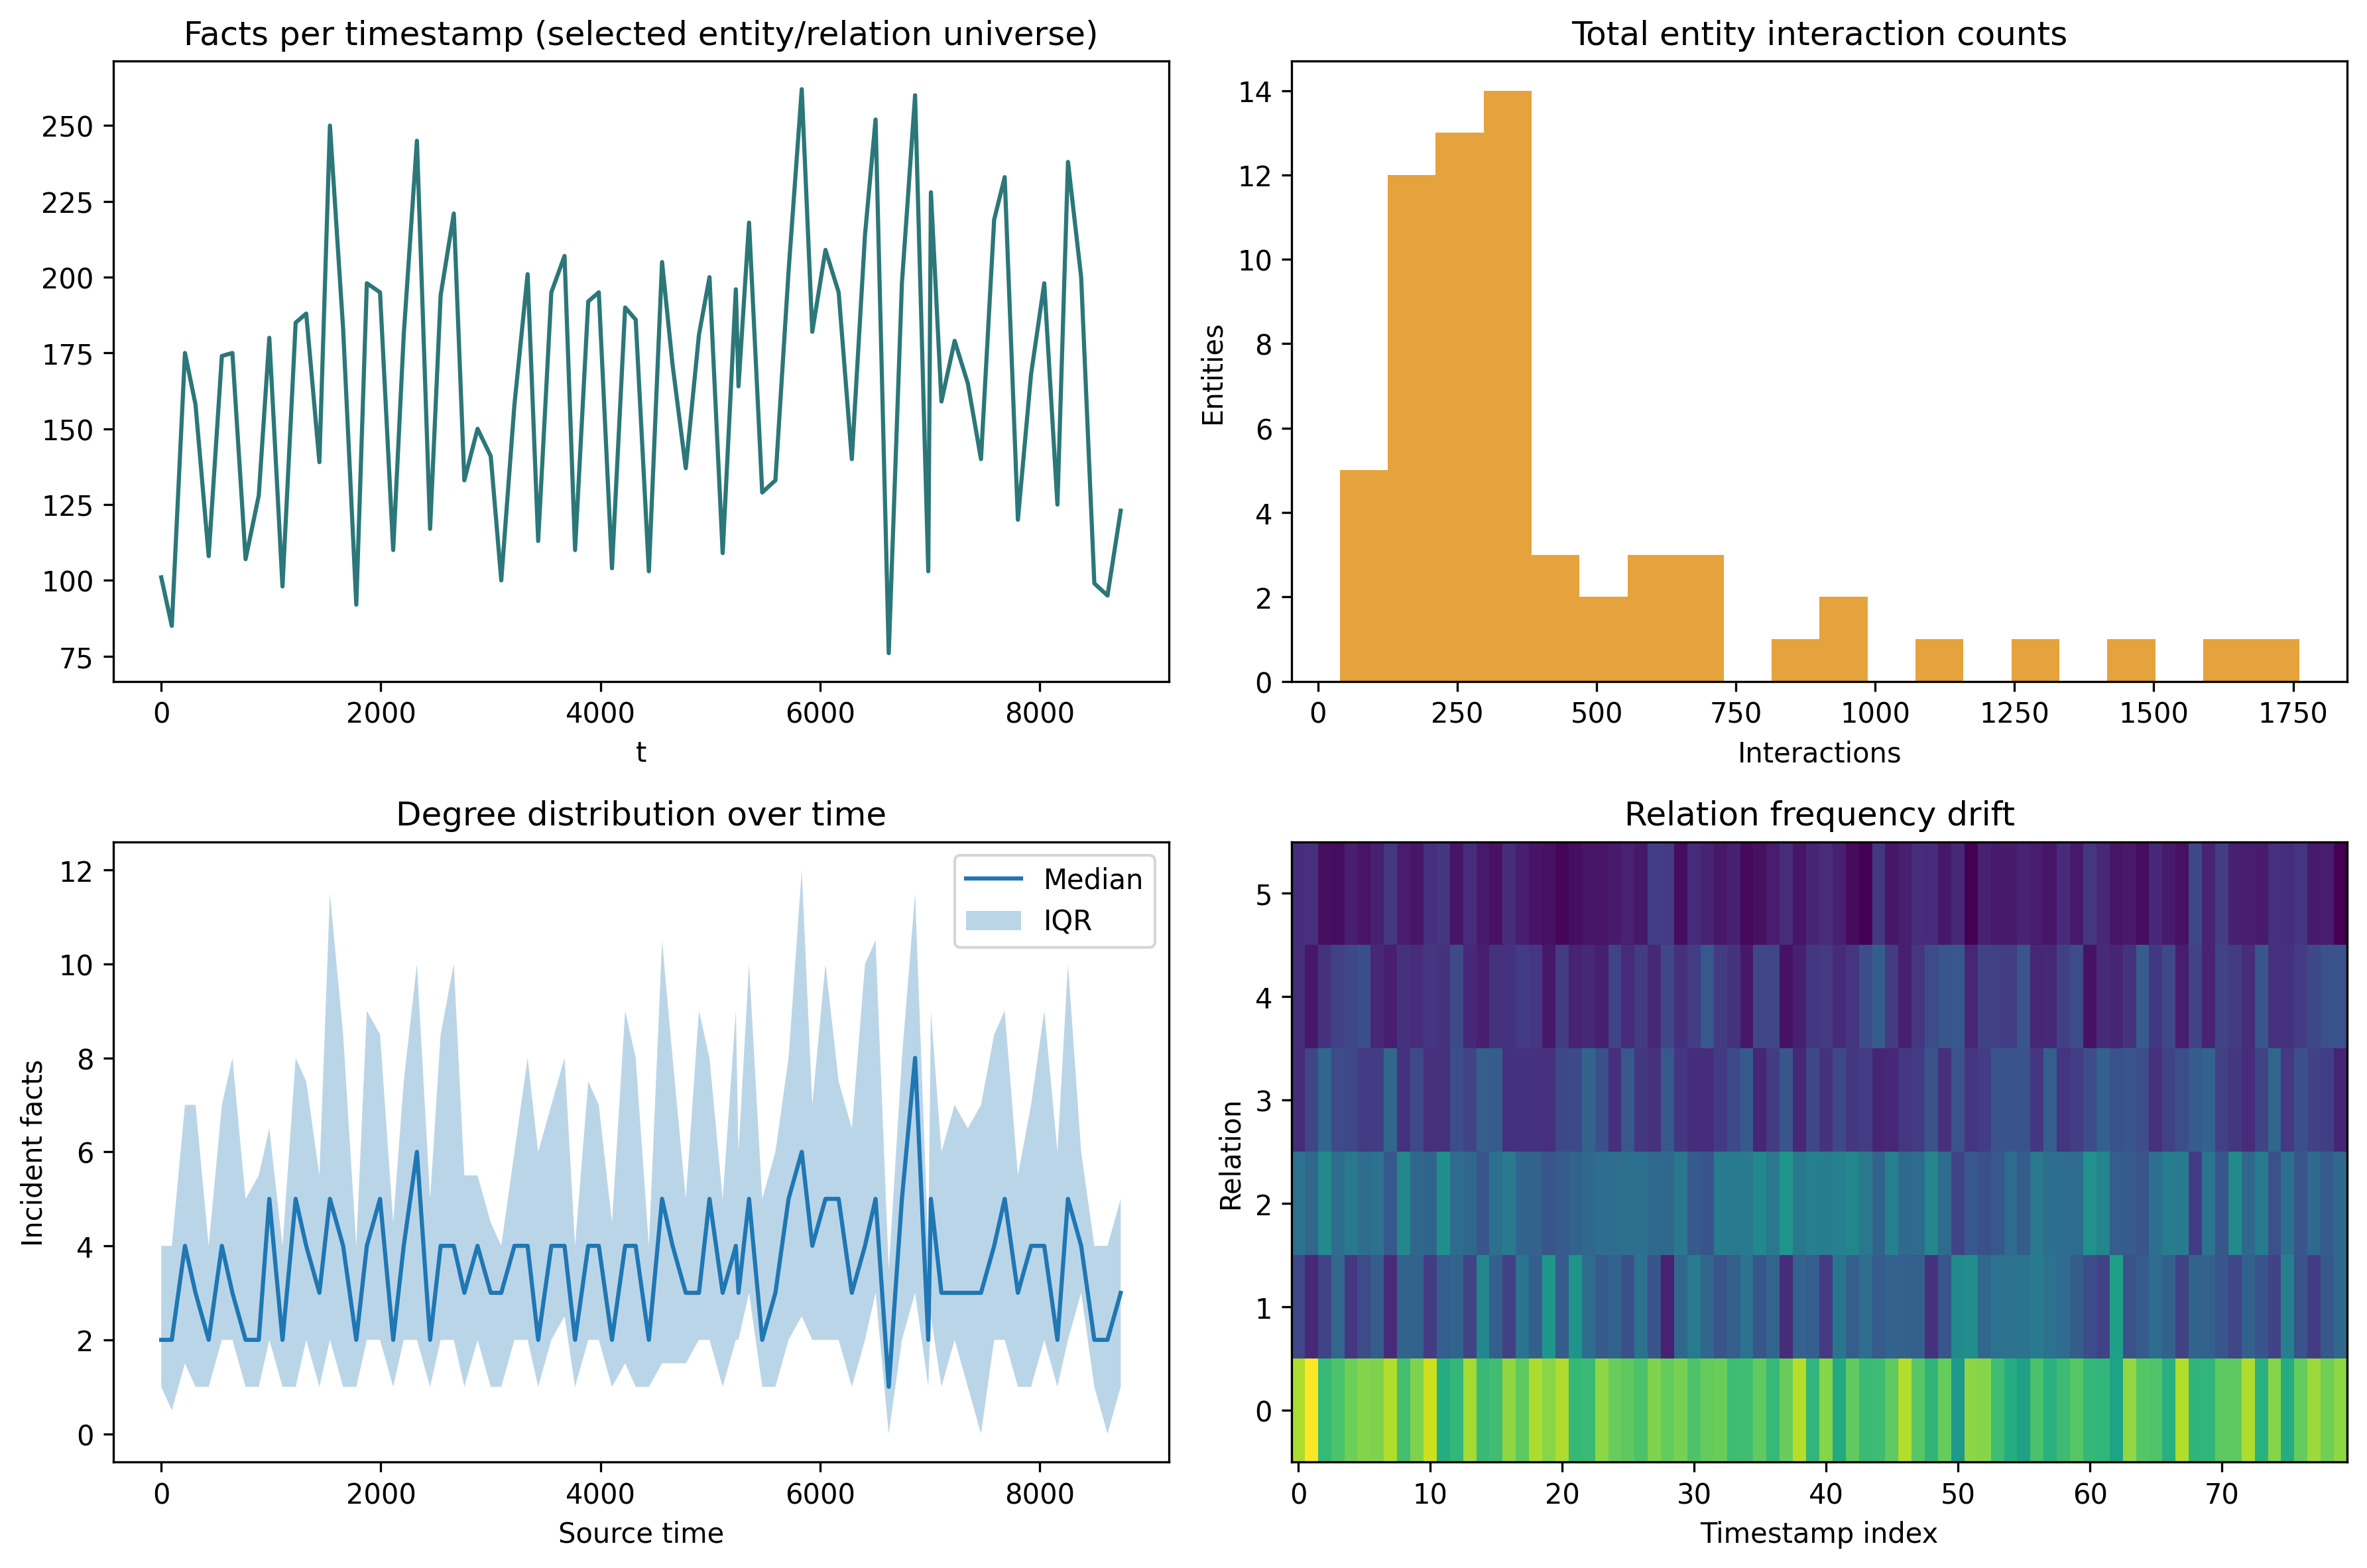

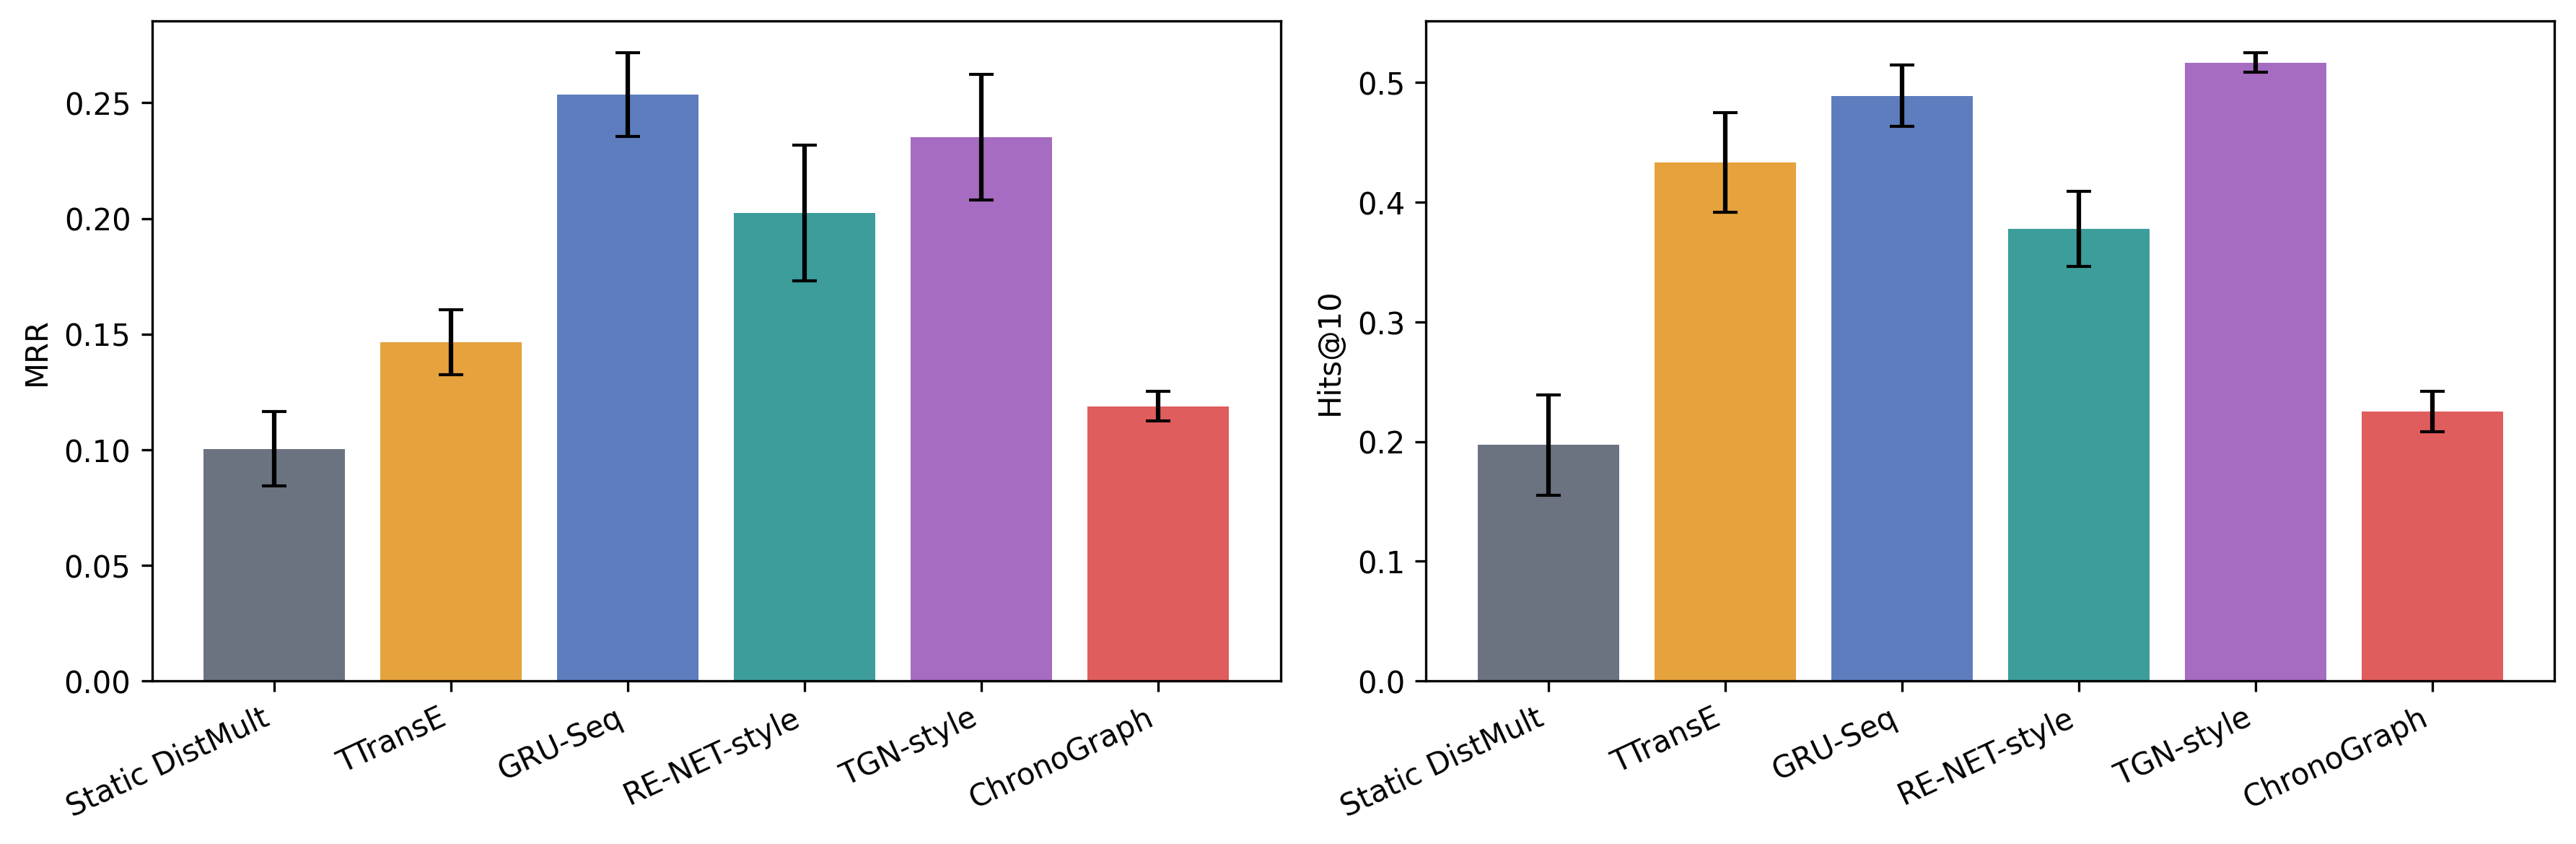

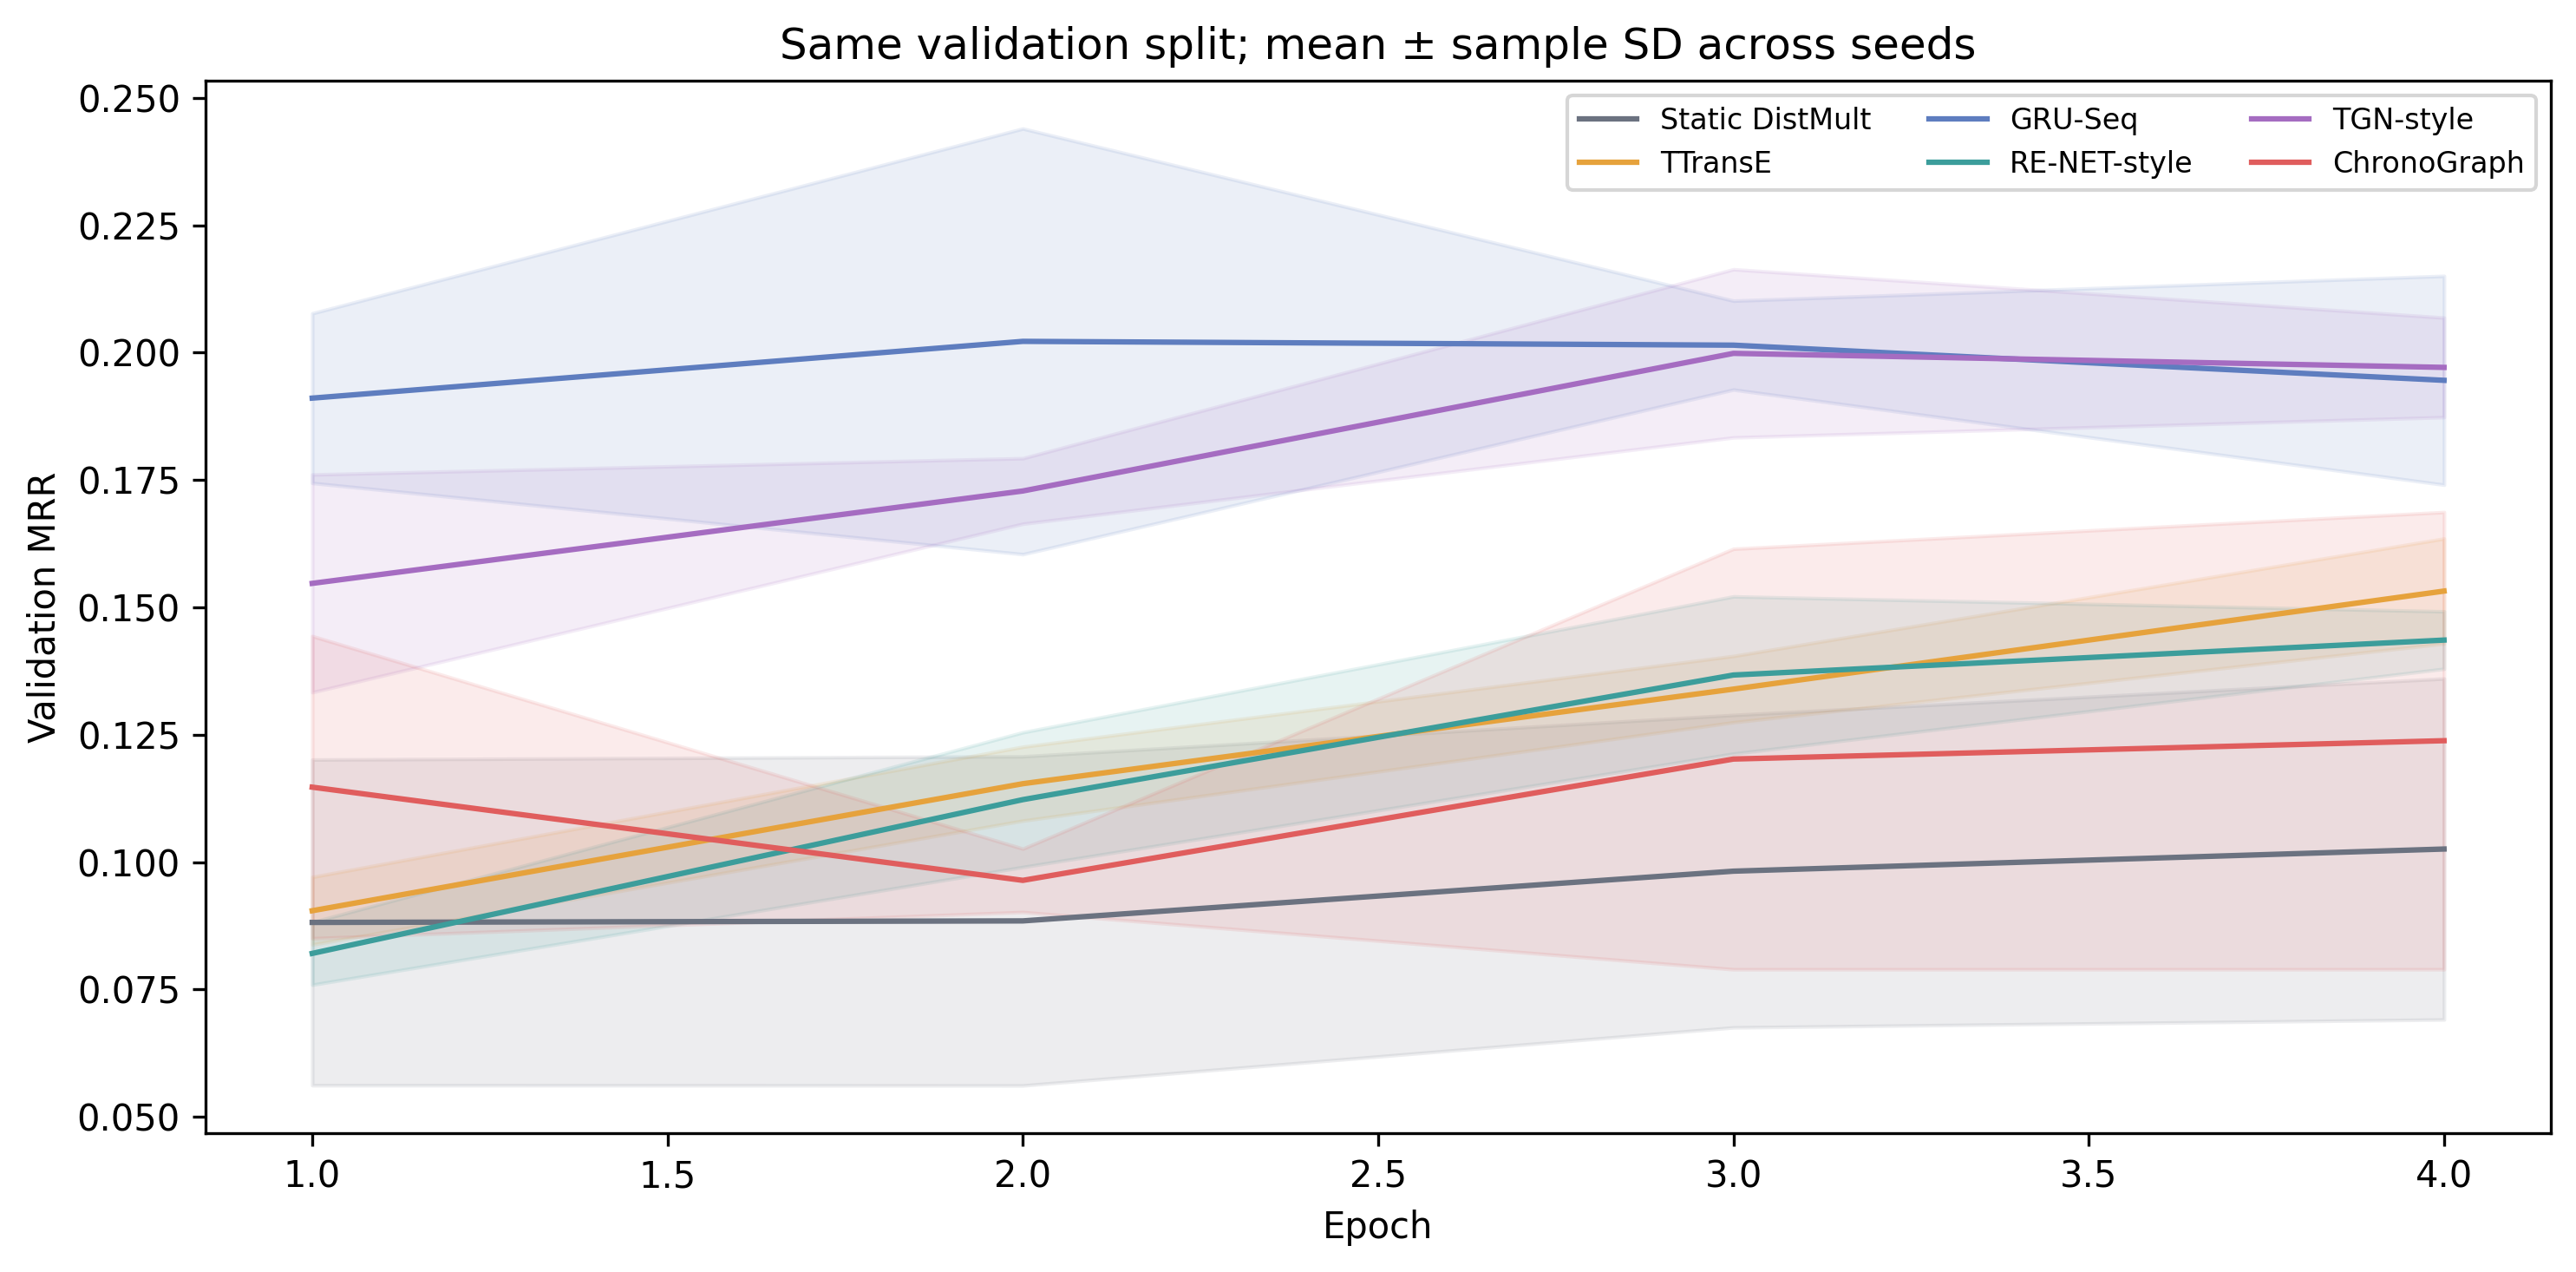

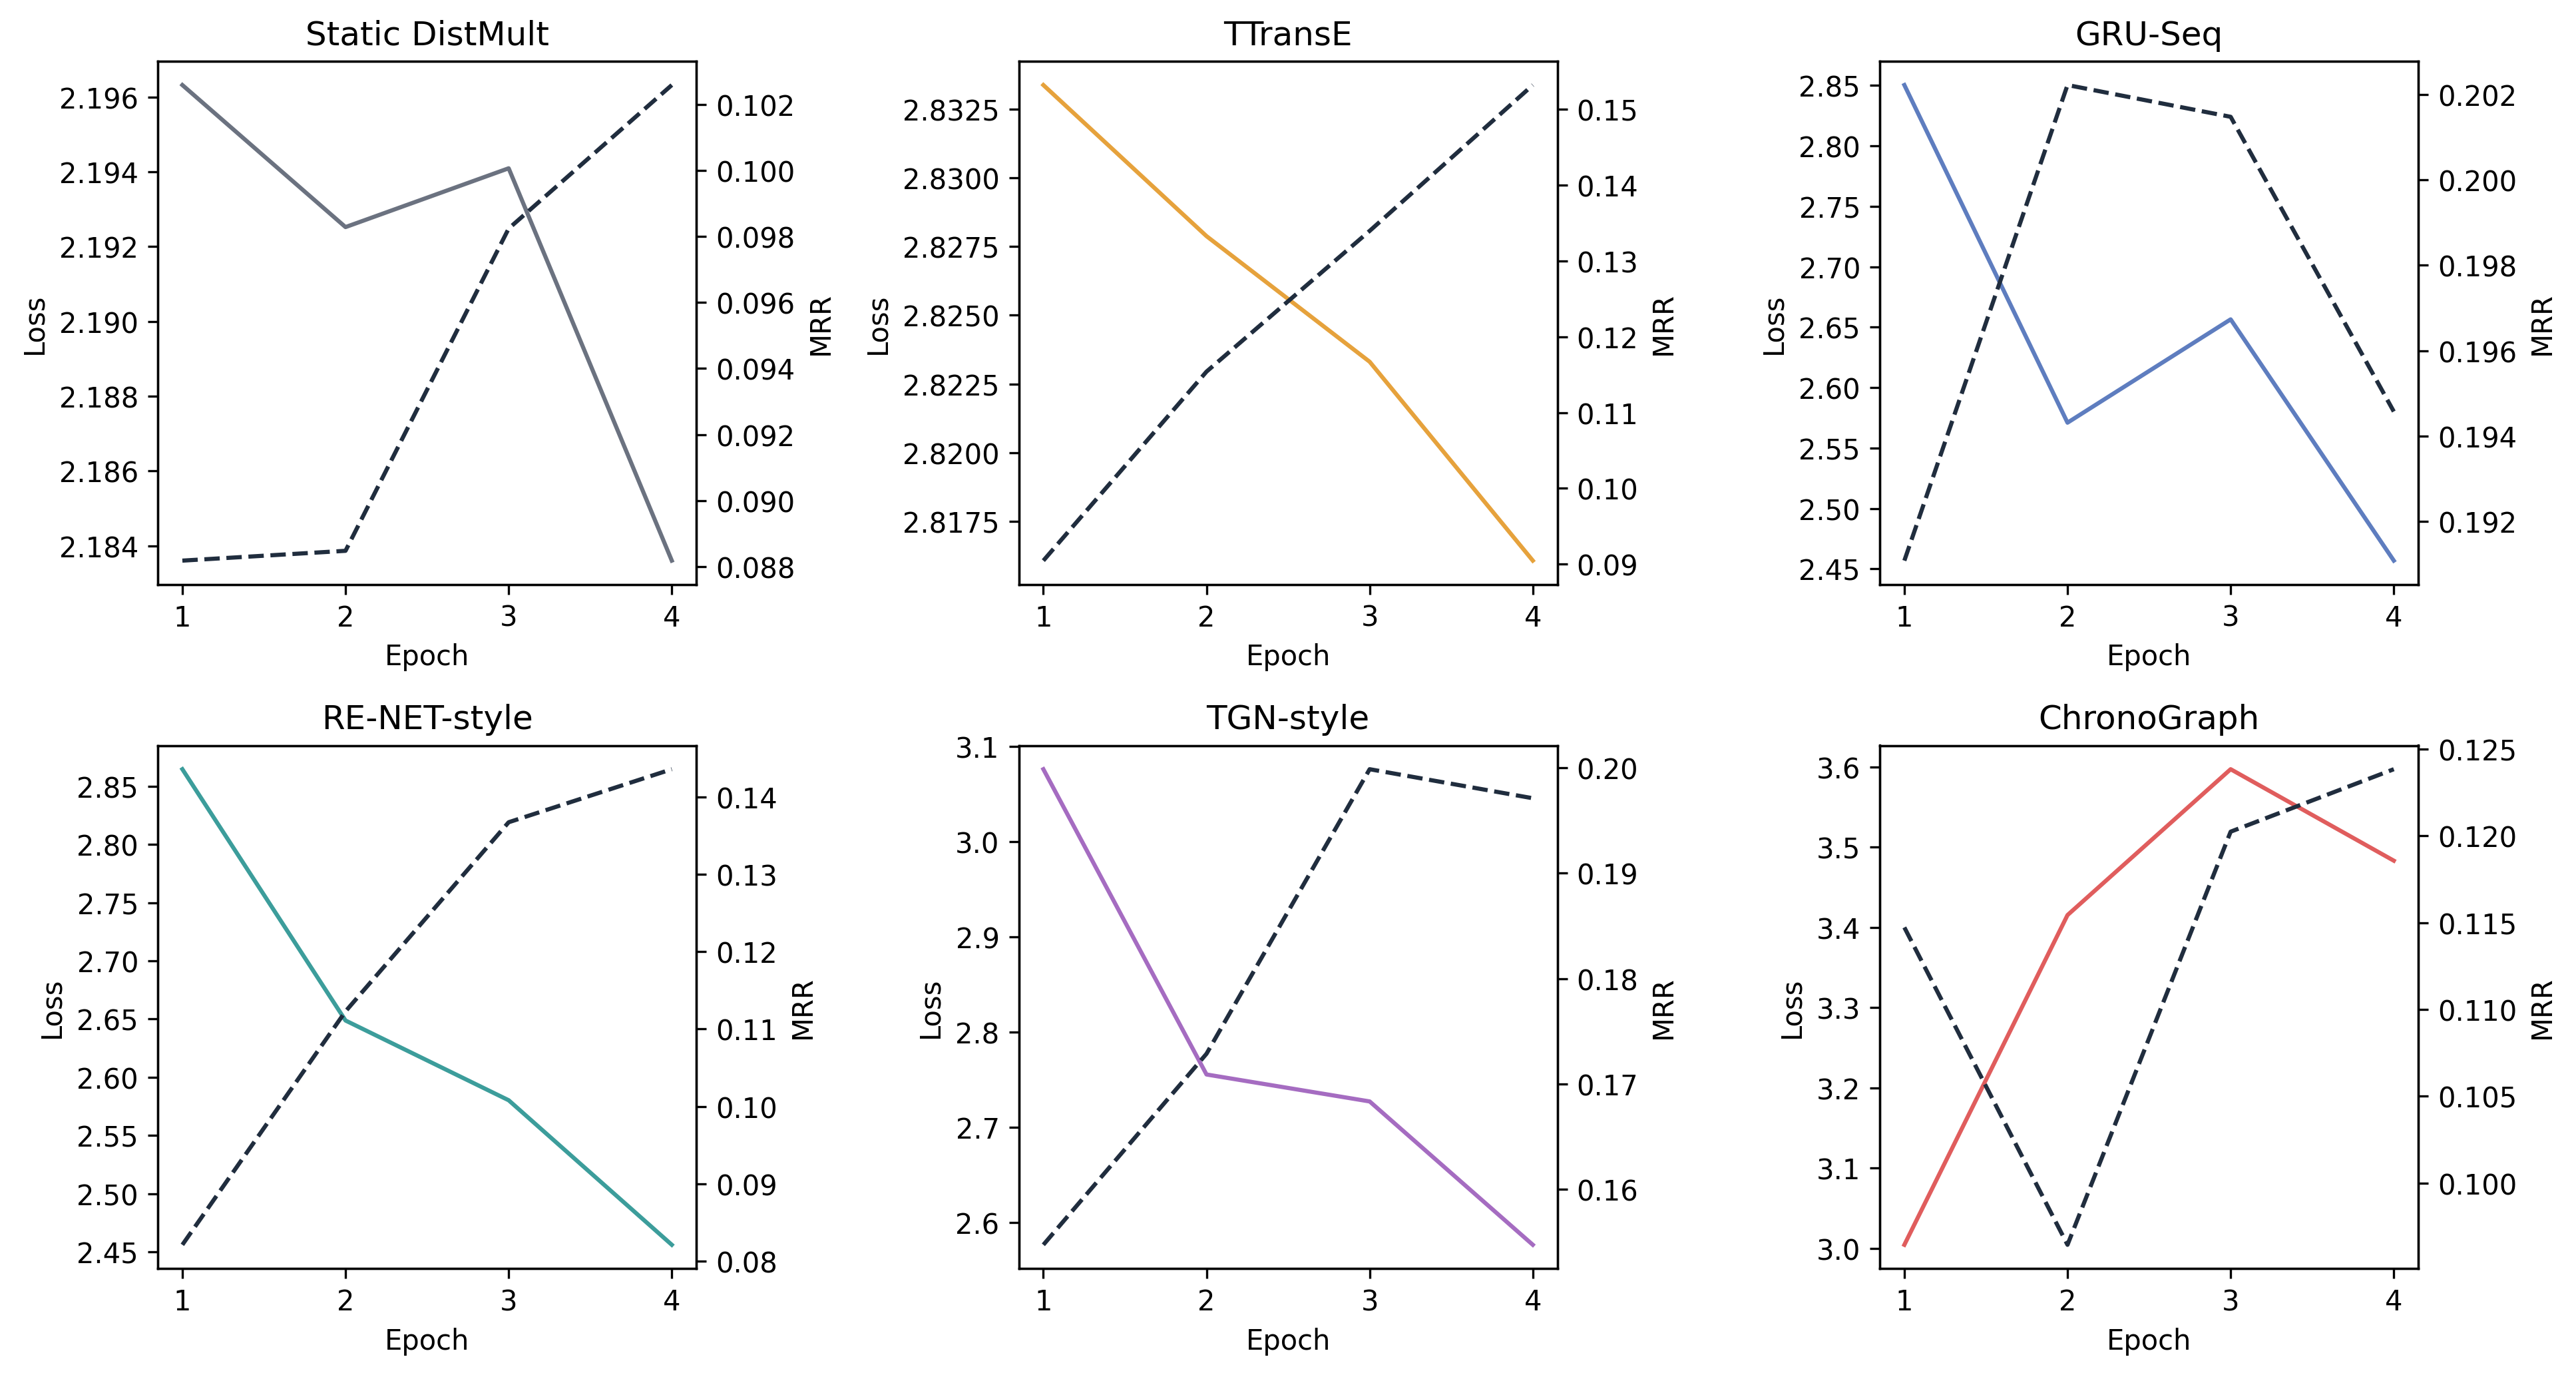

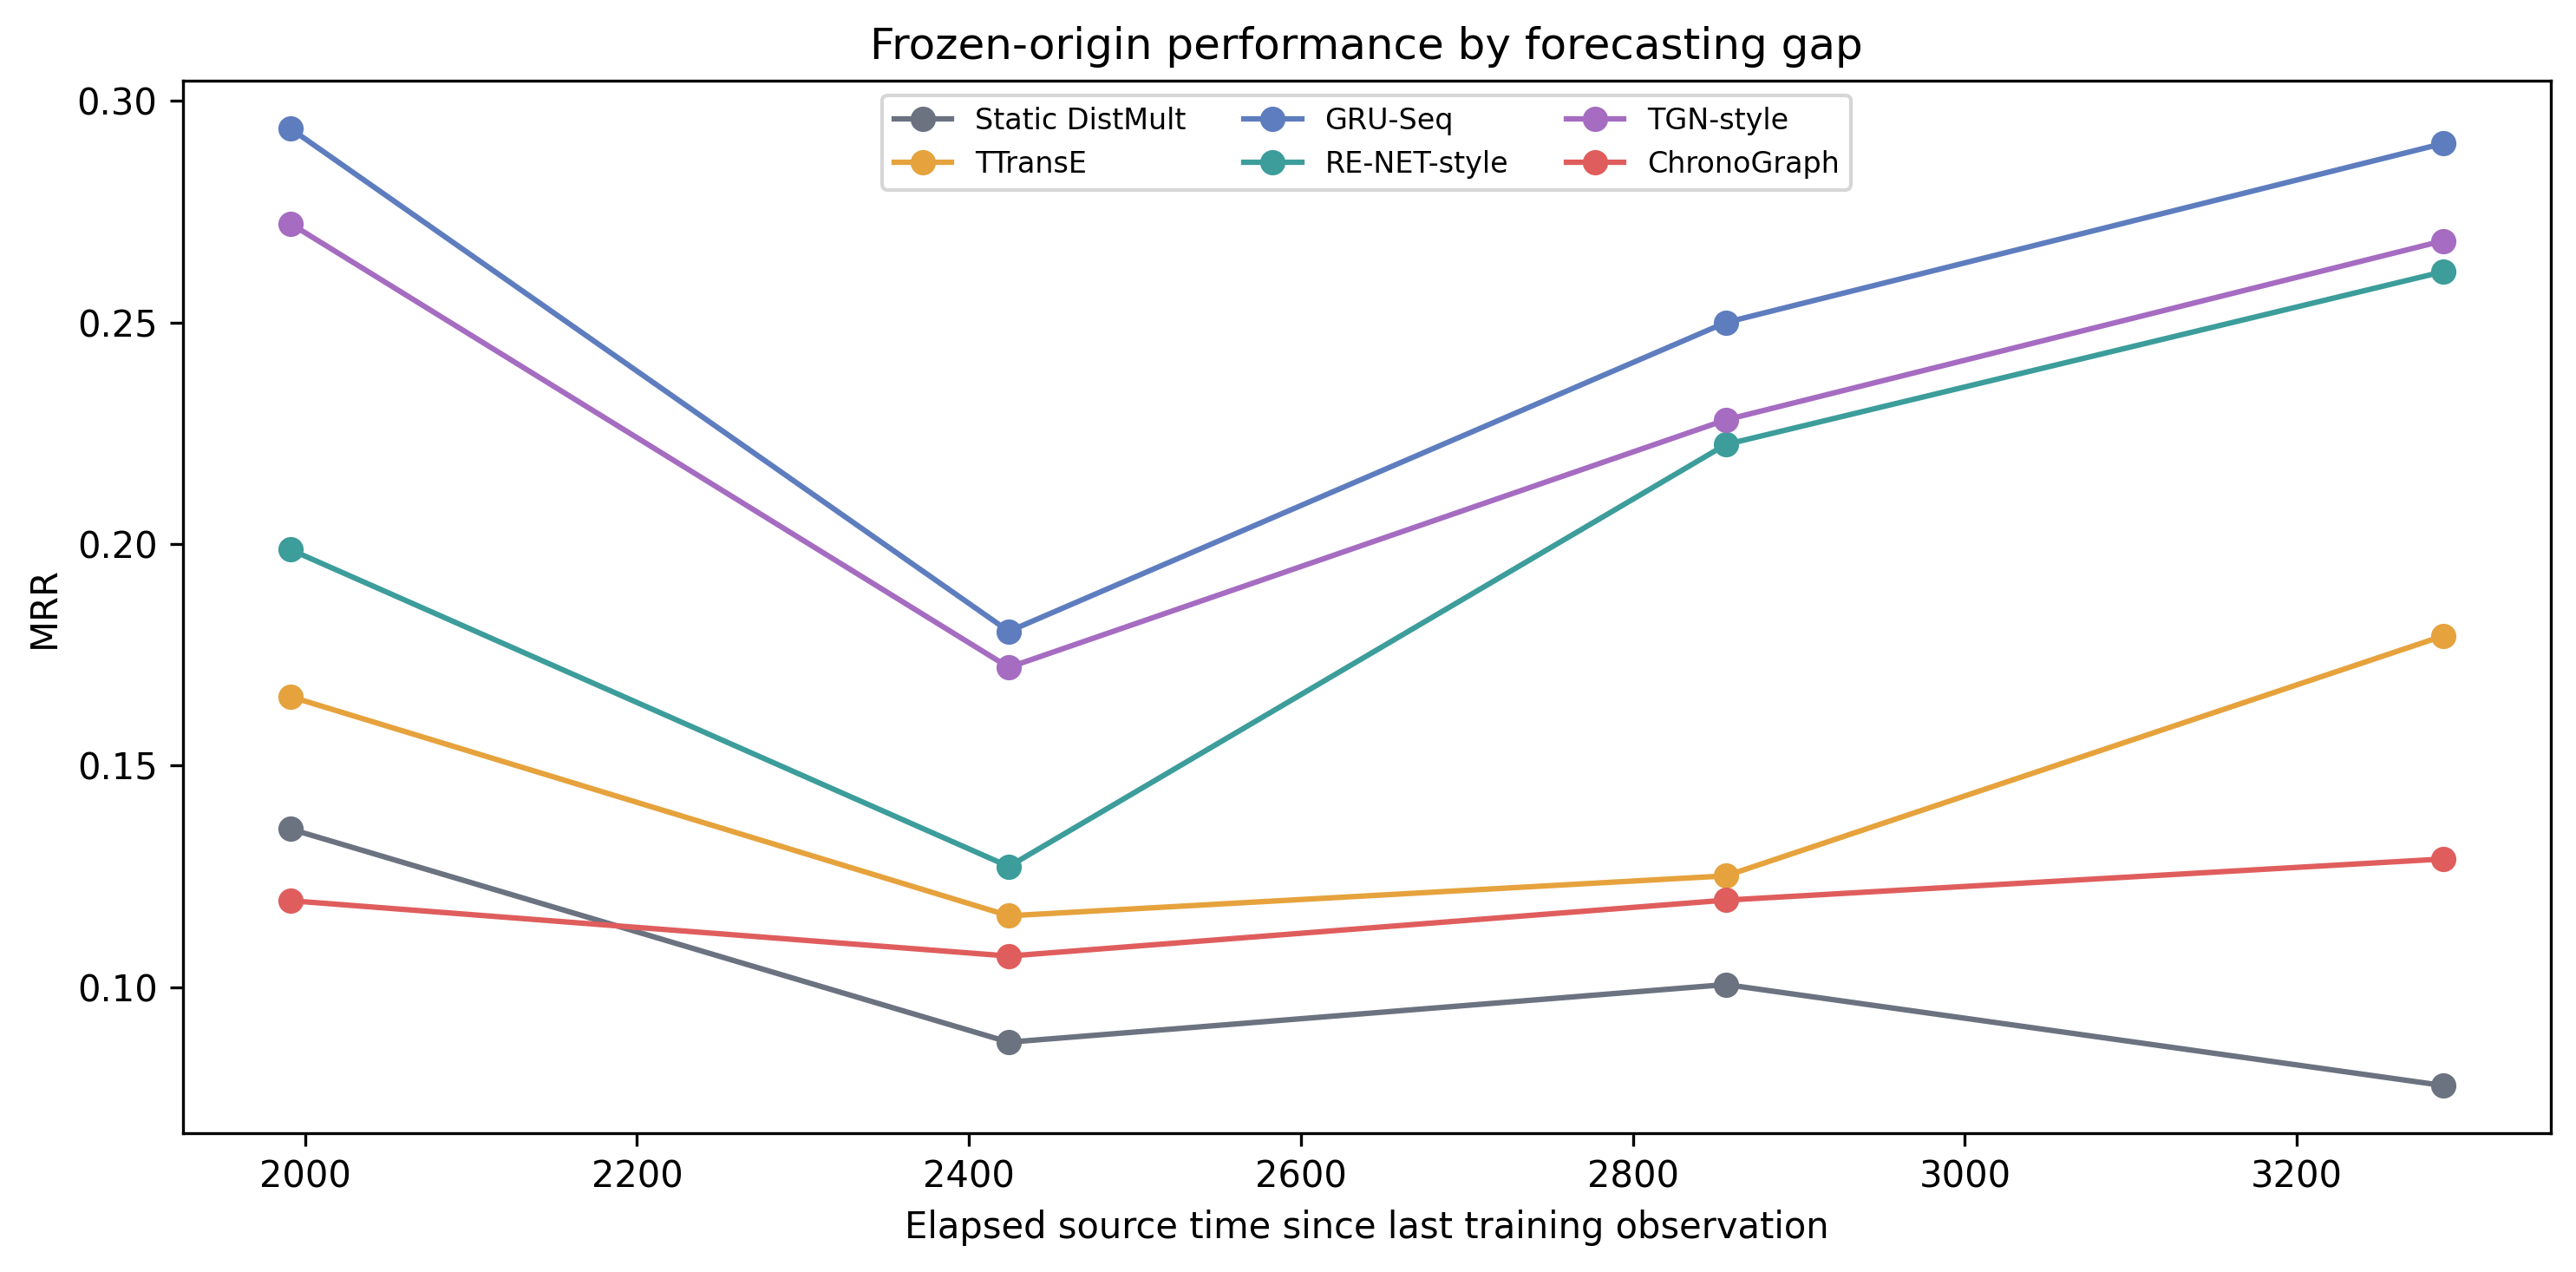

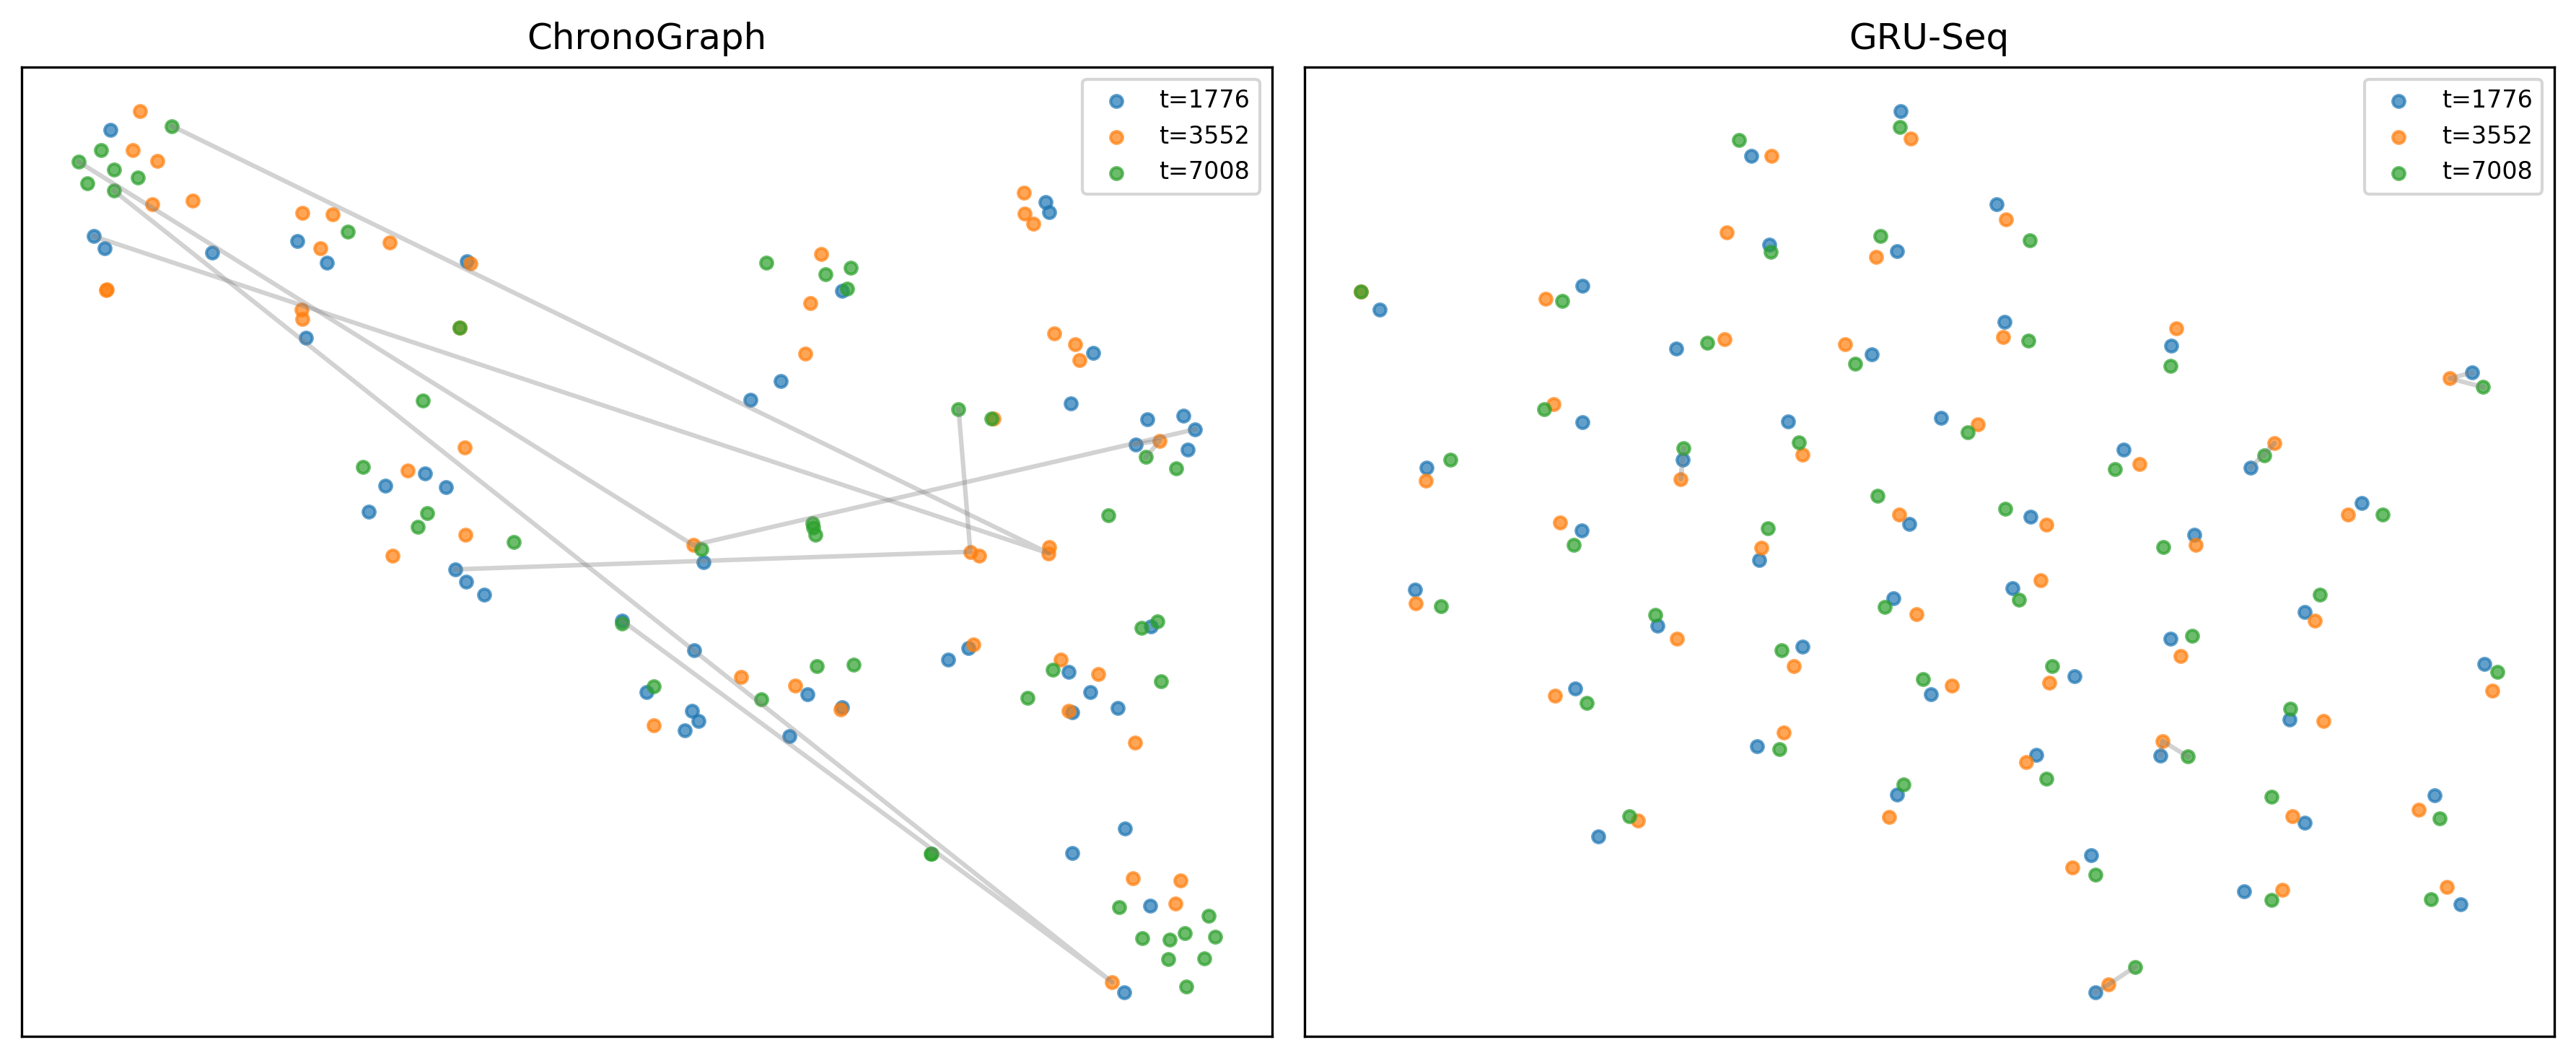

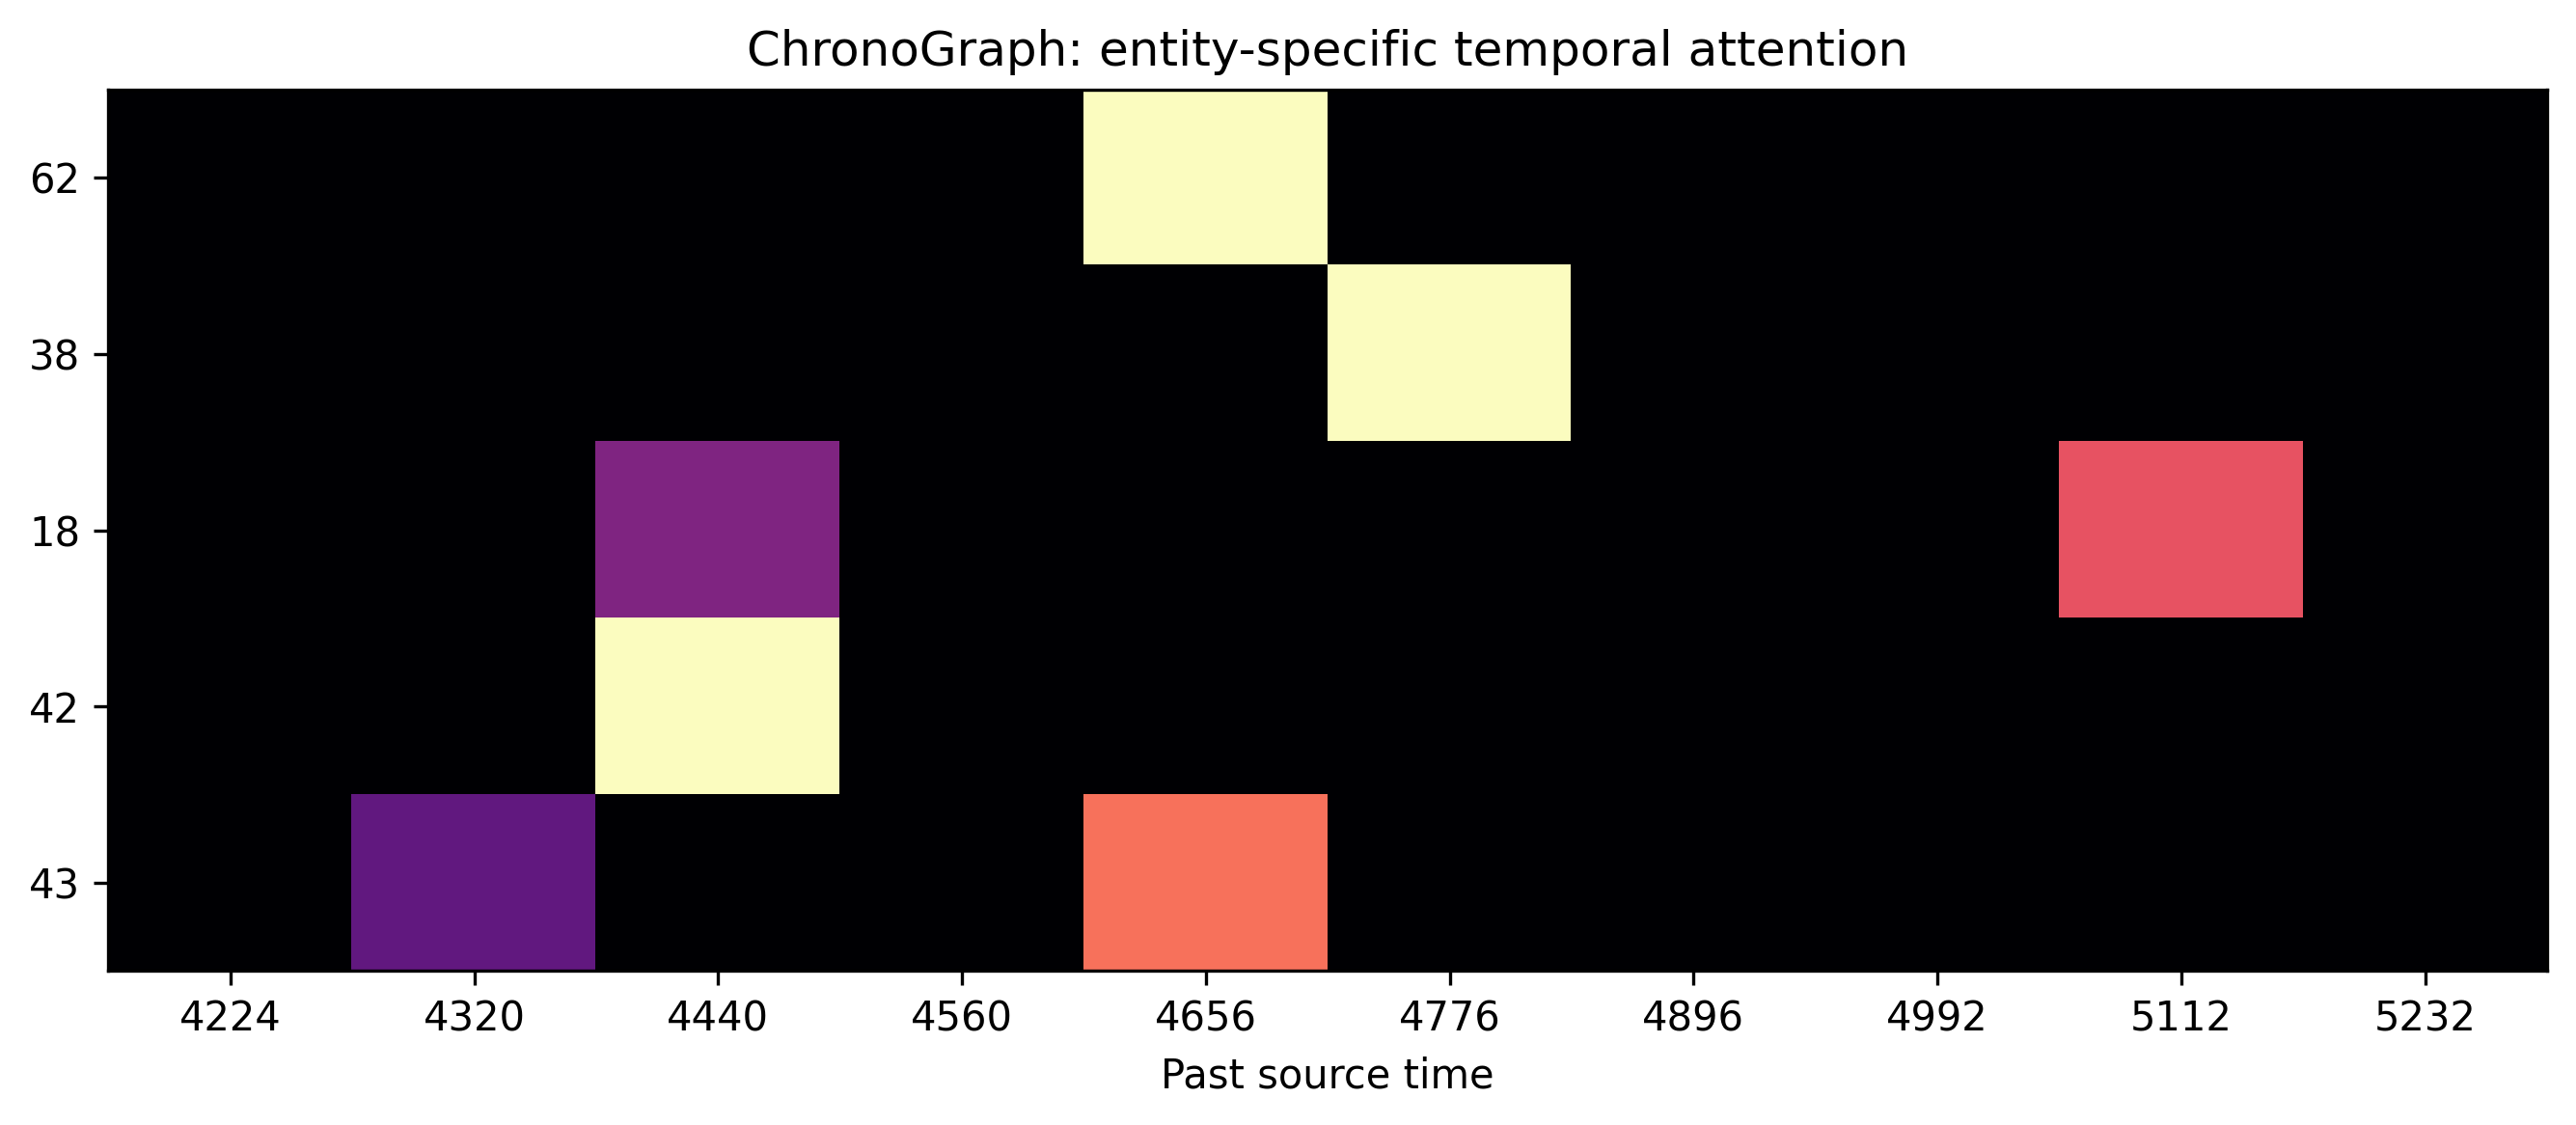

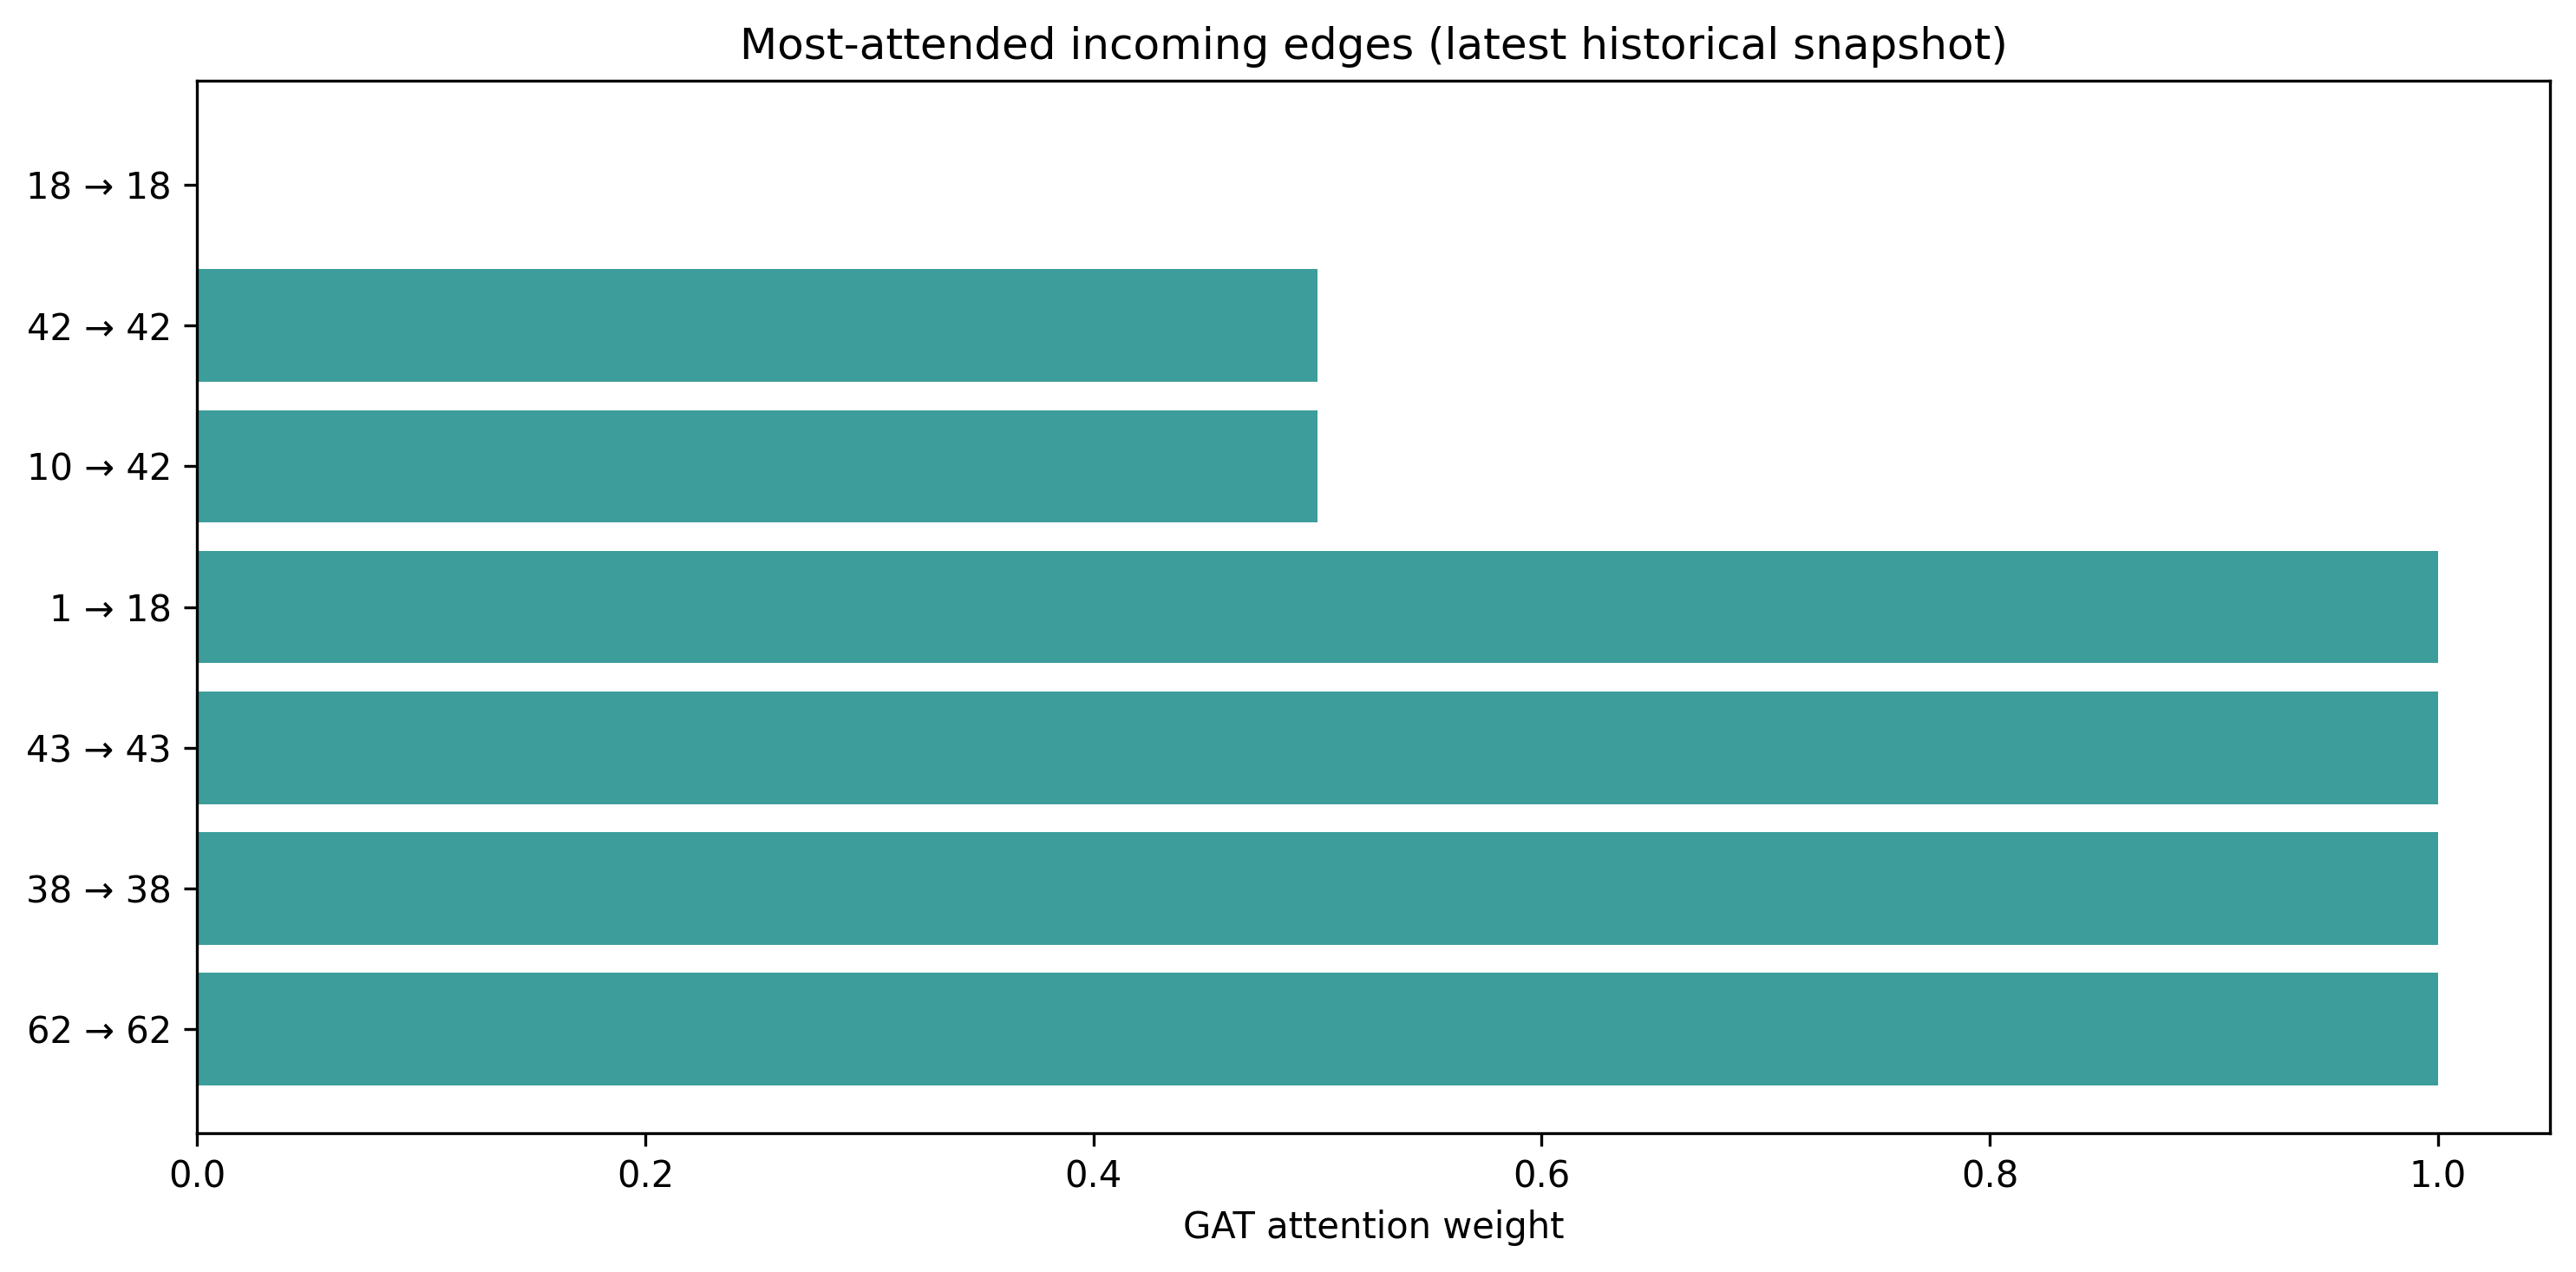

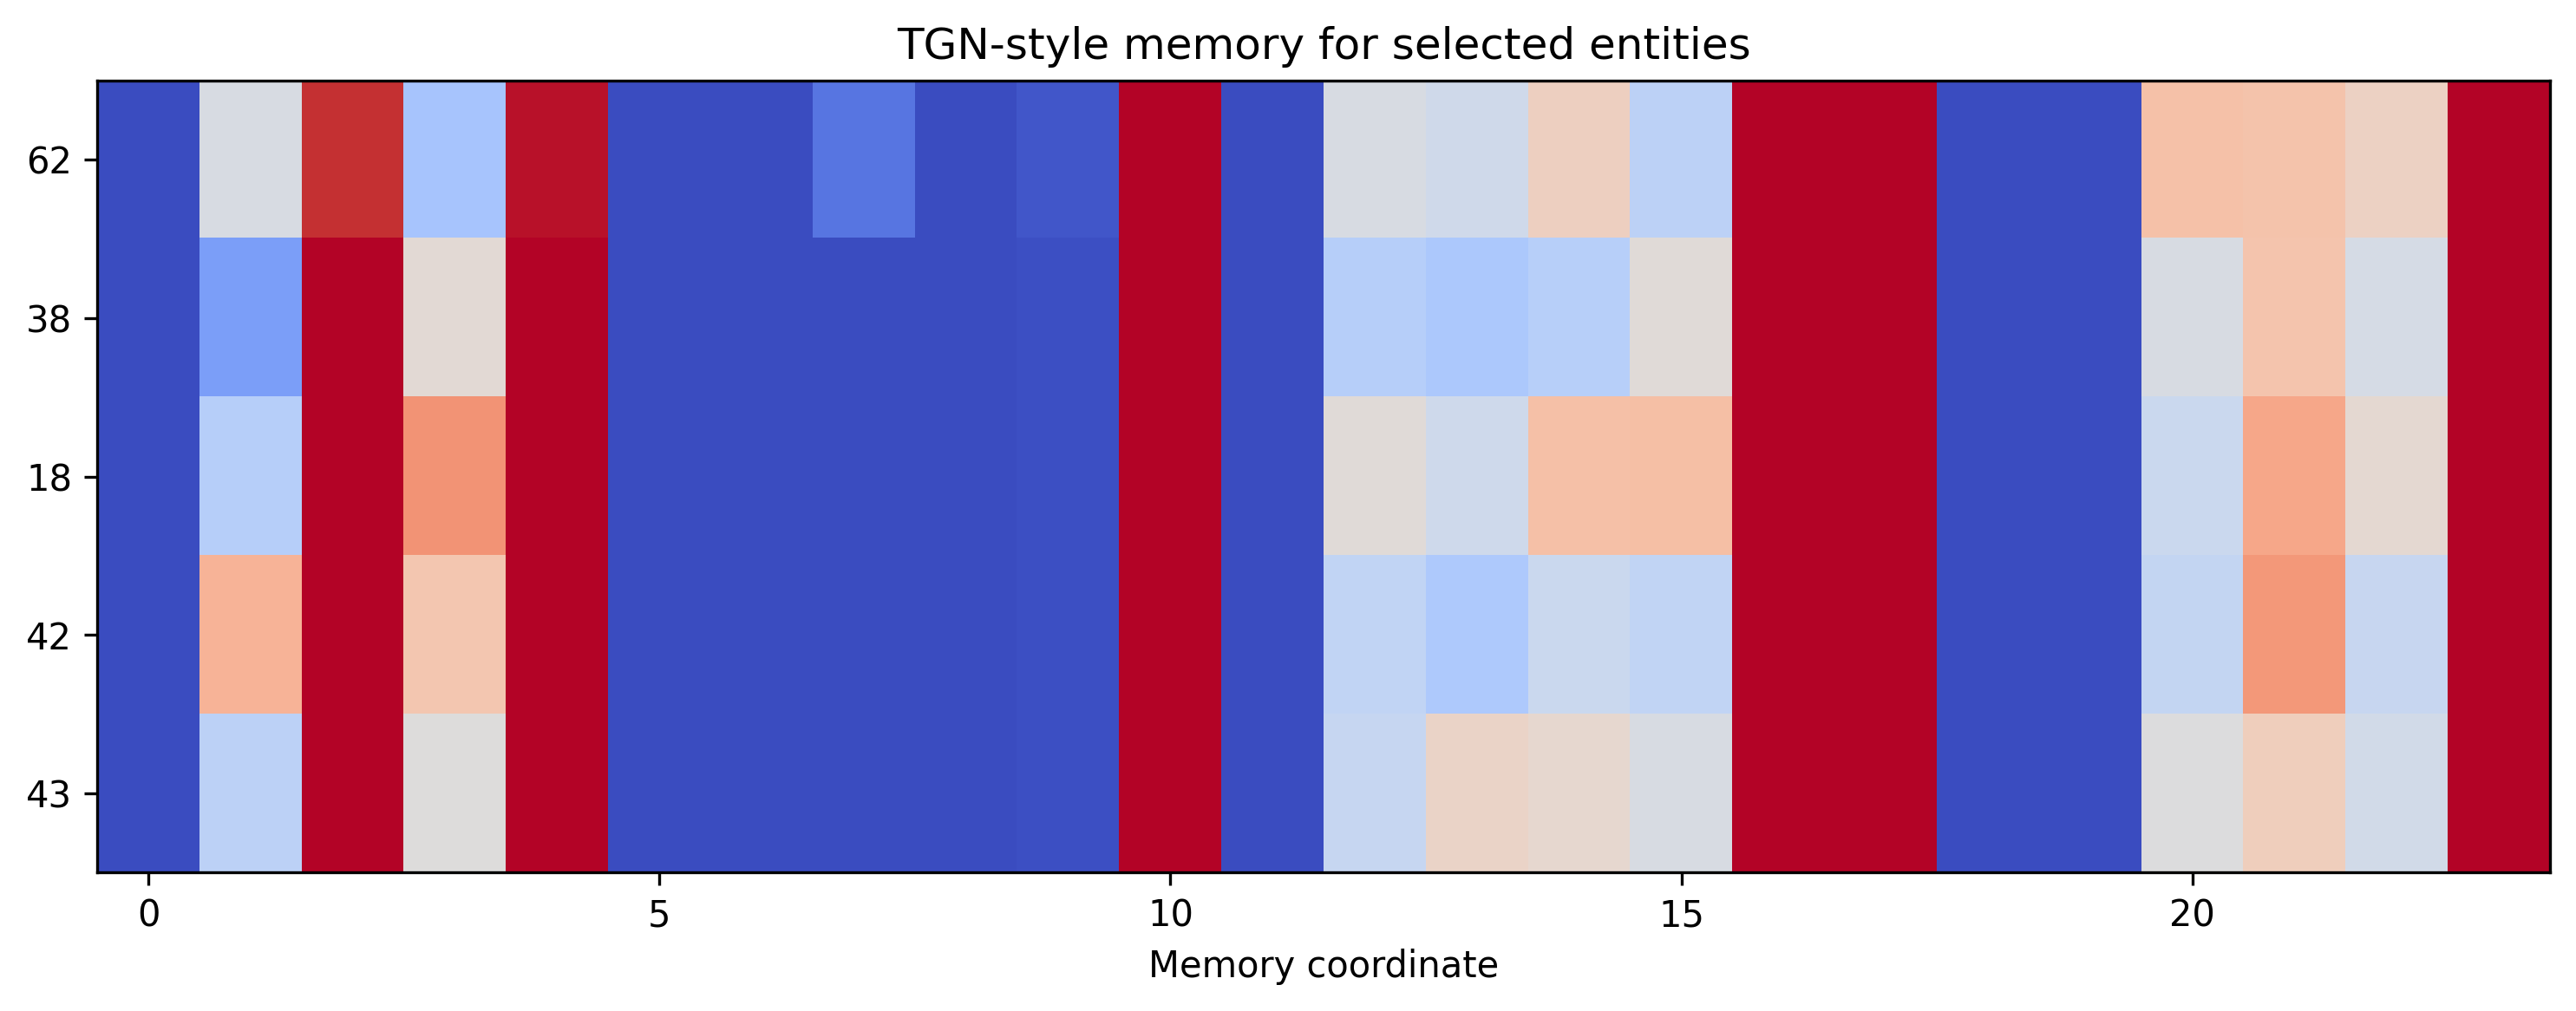

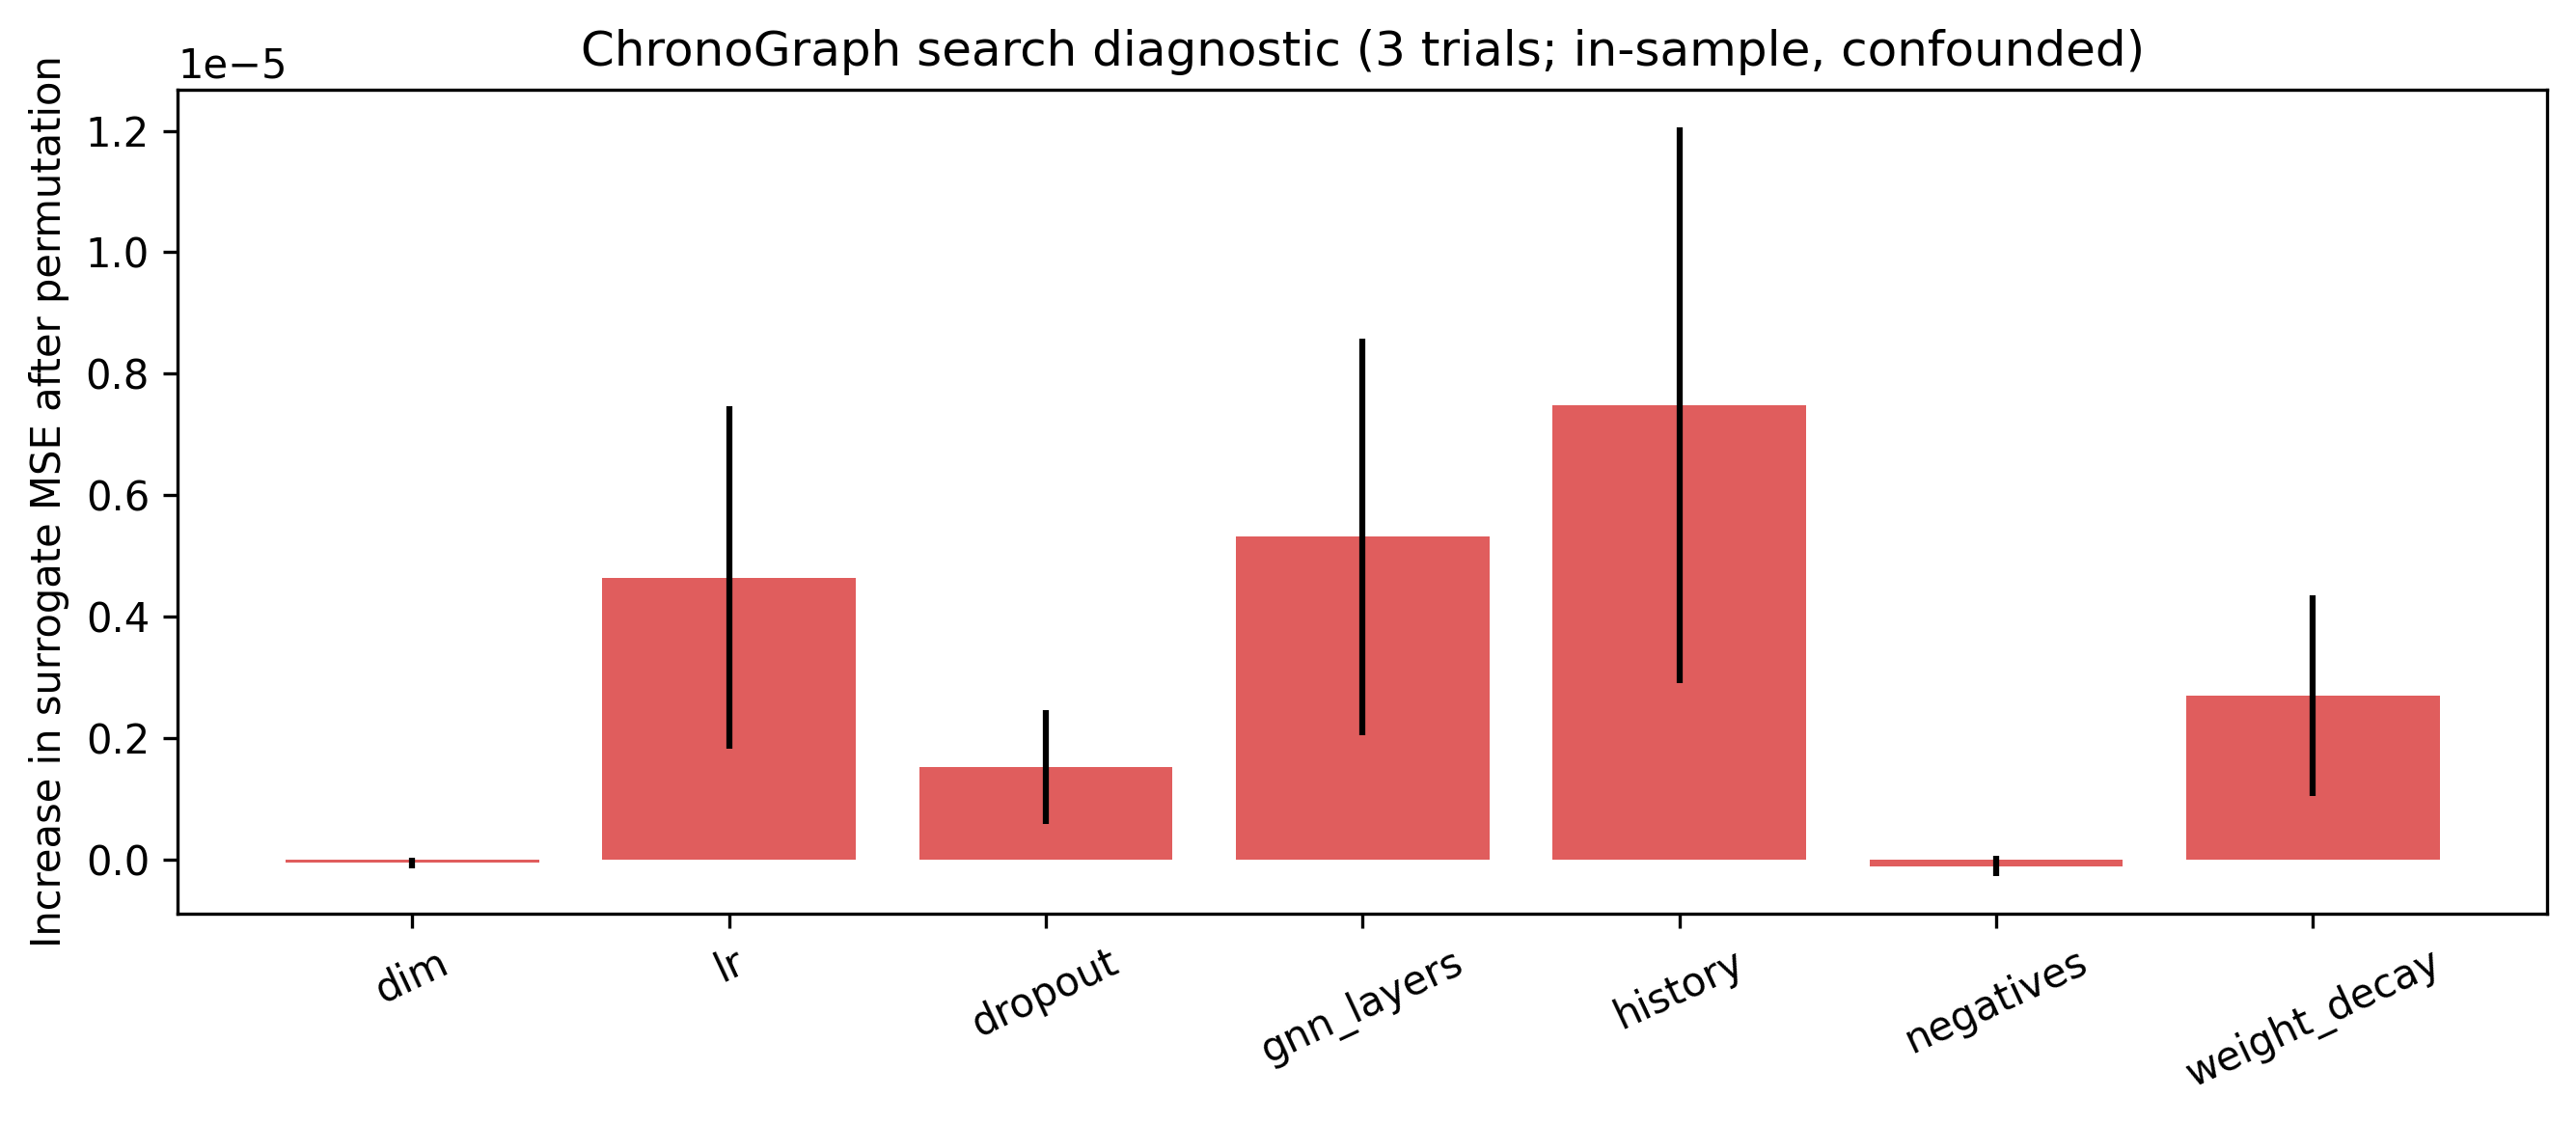

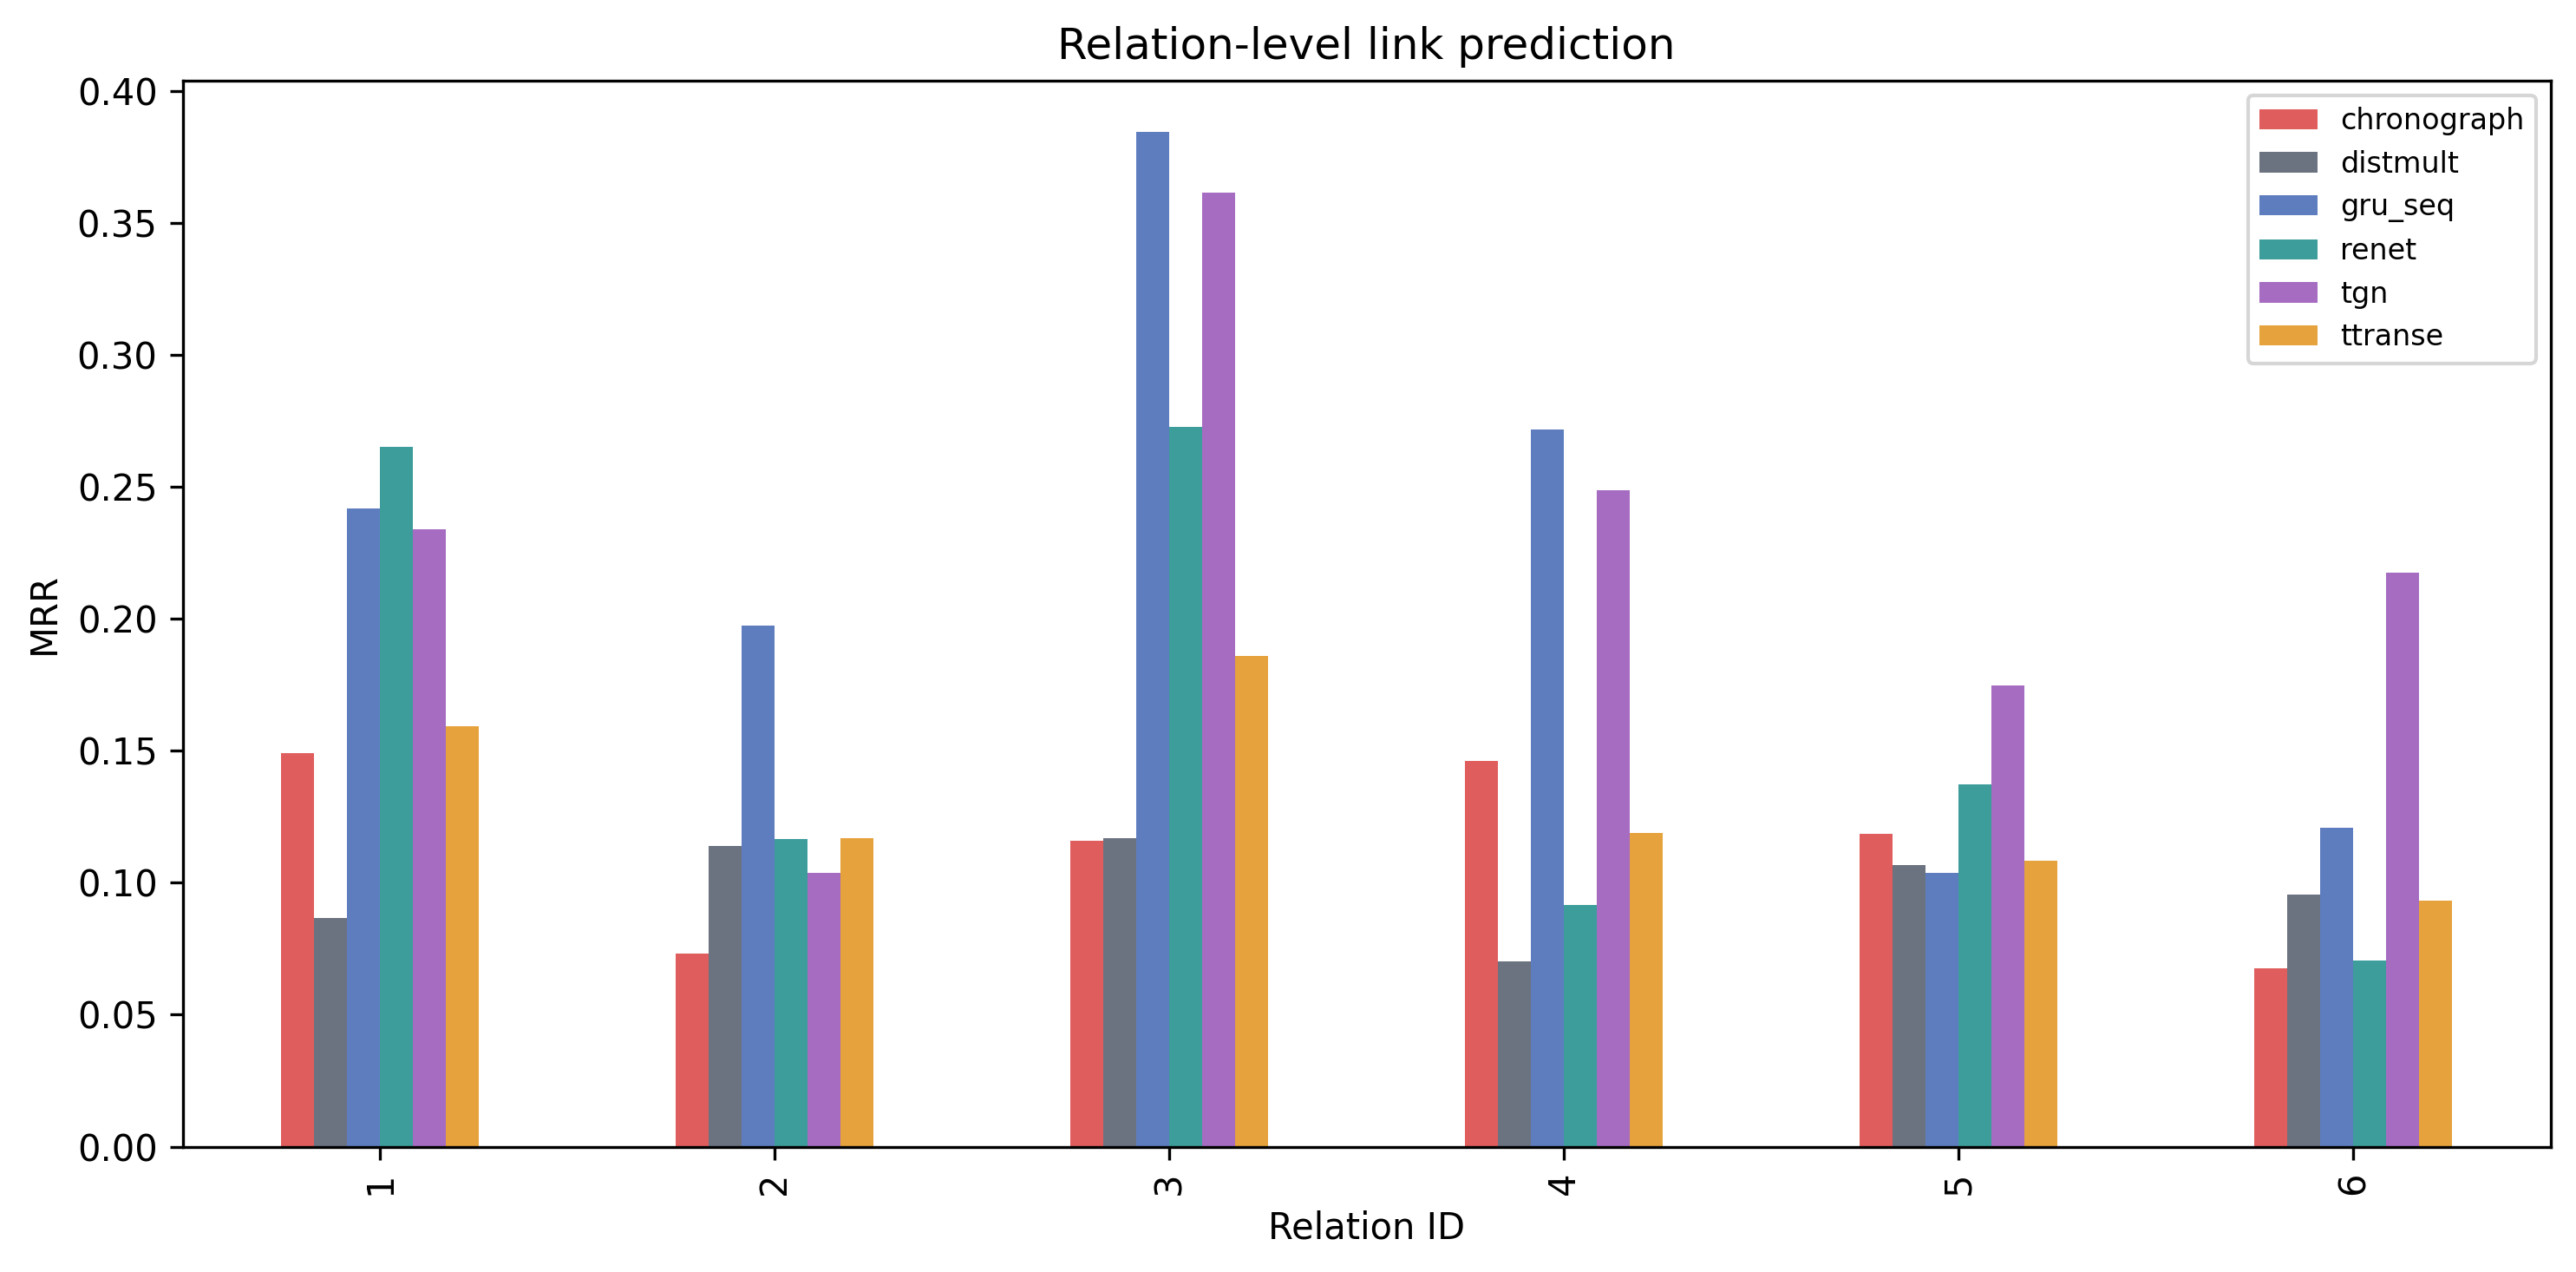

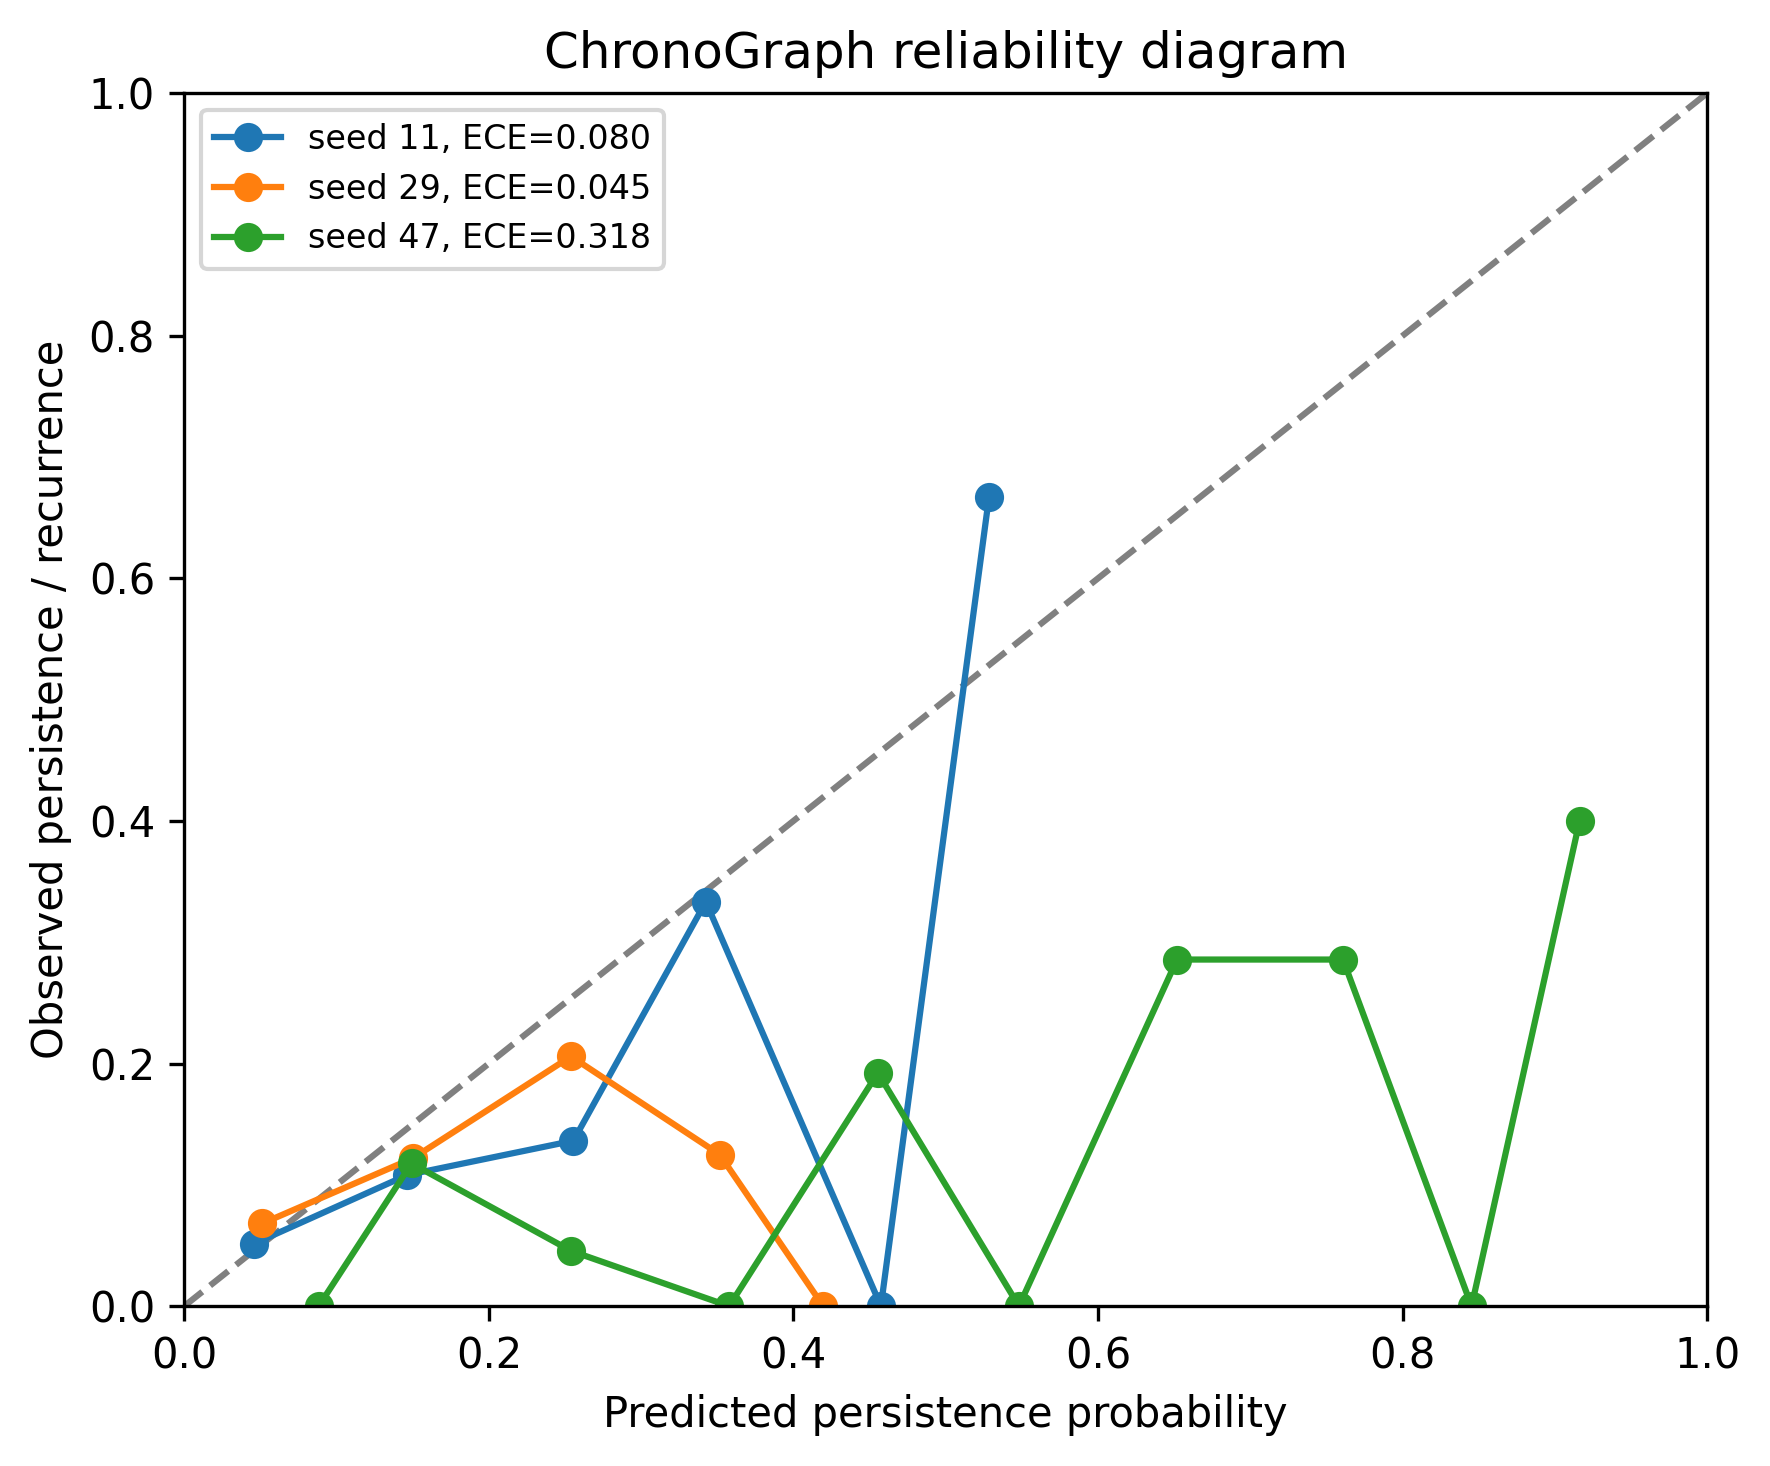

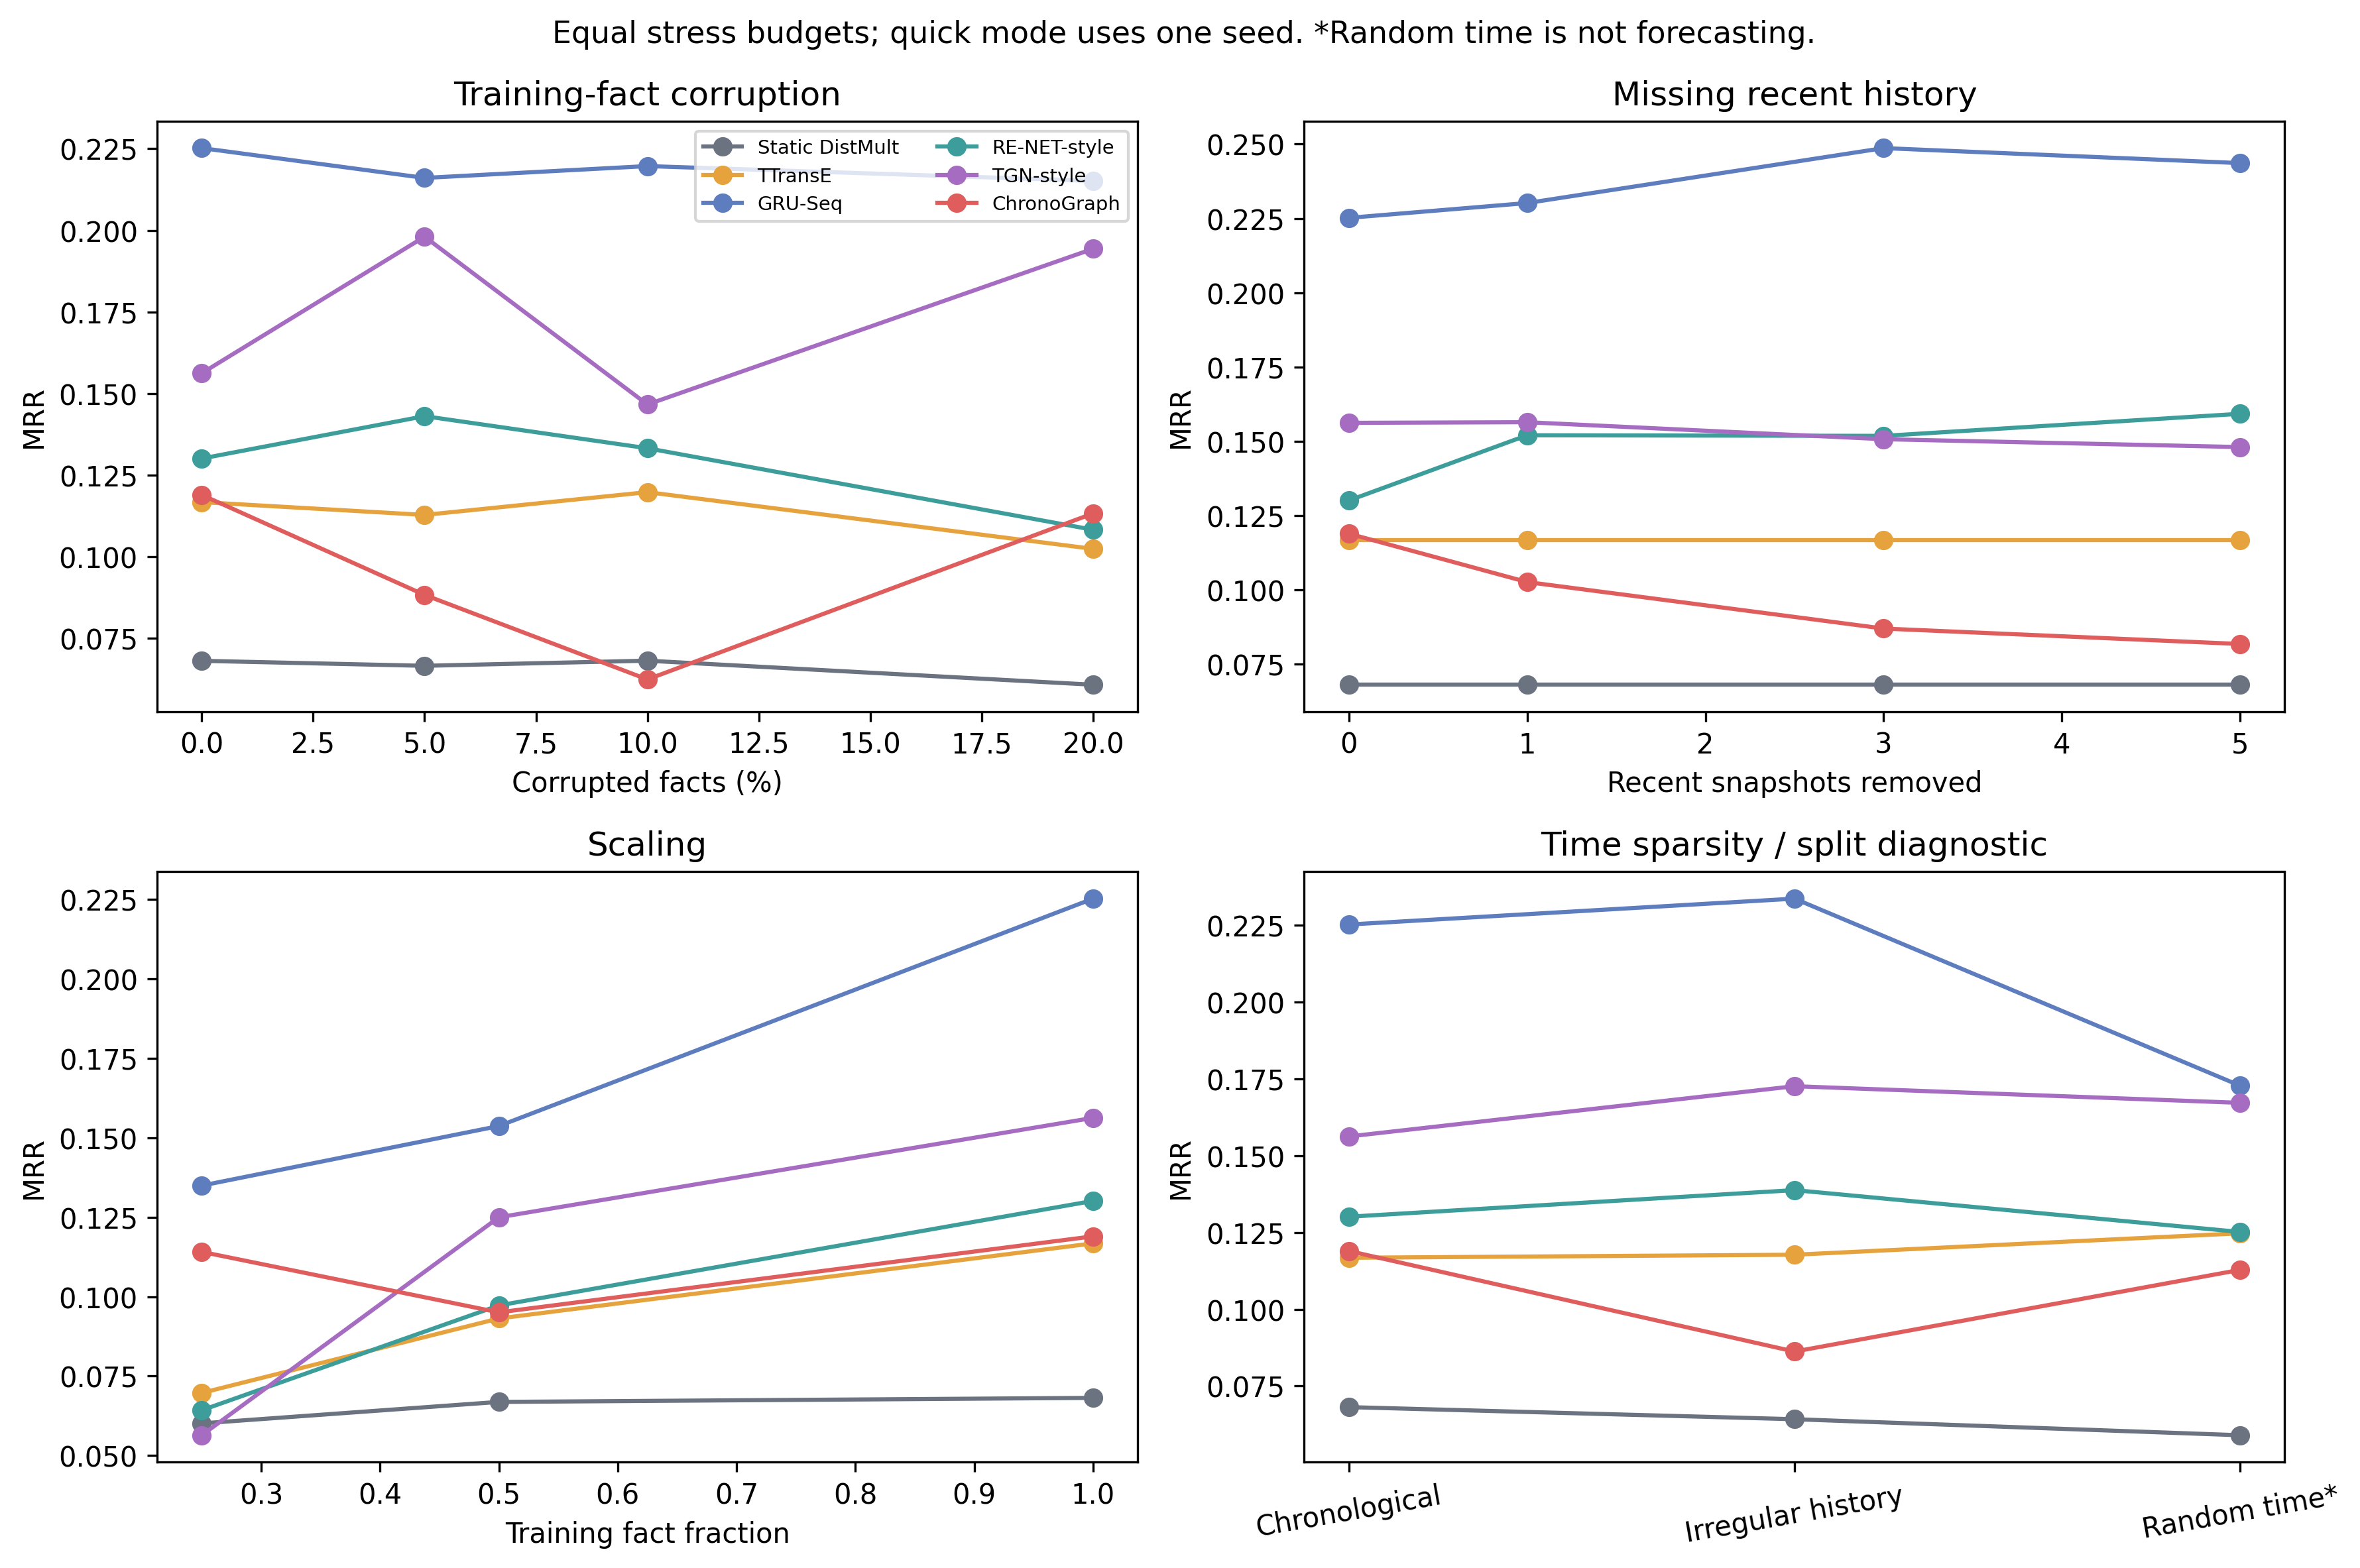

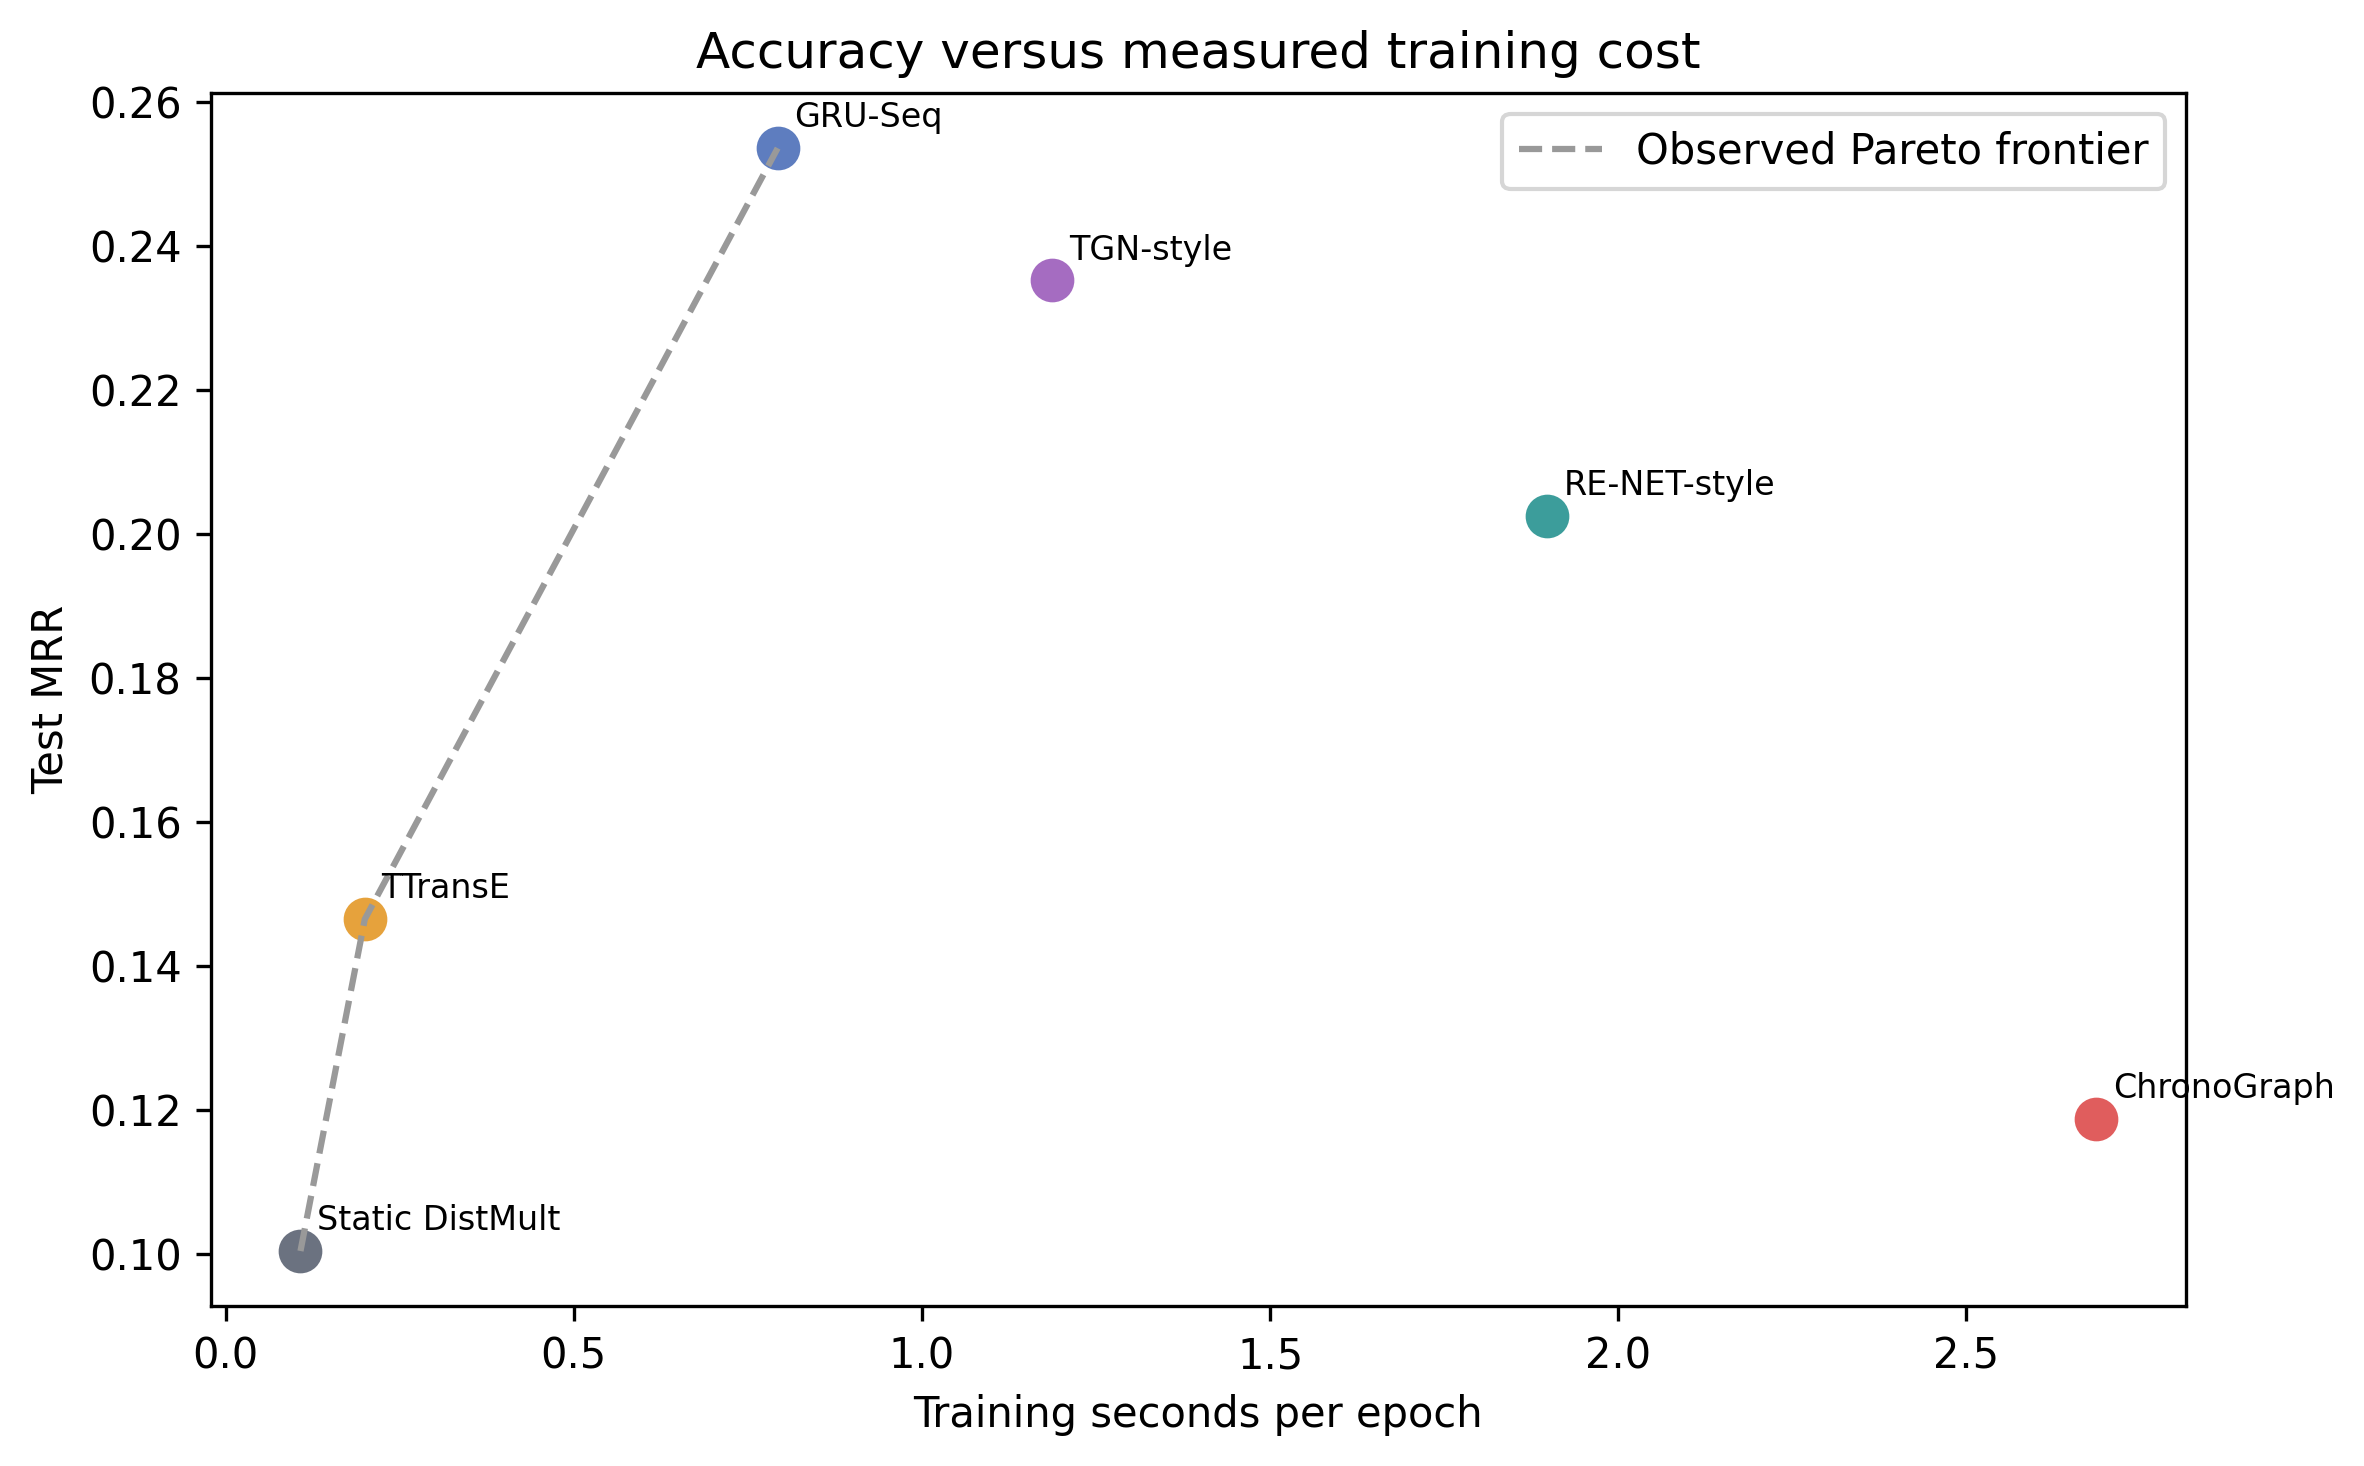

In [ ]:
for title, filename in [("Selected hyperparameters","best_configs.csv"),("Additional tasks and efficiency","extended_metrics.csv"),("Expiry / recurrence by horizon","expiry_by_horizon.csv"),("Changed-entity case studies","case_studies.csv")]:
    p=Path(cfg.root)/"reports"/filename
    if p.exists() and p.stat().st_size>3:
        display(Markdown("**"+title+"**"));display(pd.read_csv(p).head(12))
for filename in ["eda","main_comparison","validation_overlay","learning_curves","performance_by_gap","embedding_tsne","temporal_attention","neighbor_attention","memory_heatmap","hyperparameter_importance","relation_breakdown","calibration","stress_tests","pareto"]:
    p=Path(cfg.root)/"figures"/(filename+".png")
    if p.exists():display(Image(filename=str(p),width=950))


In [ ]:
display(Markdown(experiment["summary"]))
# Optional, interactive inference (requires ipywidgets):
# interactive_demo(cfg, experiment["data"])


# ChronoGraph — measured experiment summary

Dataset: **chronography**, 63 entities, 6 relations; quick smoke-test settings. Seeds: [11, 29, 47]. Successfully completed main runs: 18/18.

The best observed mean test MRR is **GRU-Seq** (0.2536). This is an empirical observation on this selected data and budget, not proof of general superiority. Hyperparameters and early stopping use validation only. The reference baseline for the statistical test was selected by validation MRR.

| Model           | Runs   | MRR             | Hits@1          | Hits@3          | Hits@10         | validity_AUC    | validity_F1     | parameters   | train_seconds_epoch   |
|:----------------|:-------|:----------------|:----------------|:----------------|:----------------|:----------------|:----------------|:-------------|:----------------------|
| Static DistMult | 3/3    | 0.1004 ± 0.0161 | 0.0278 ± 0.0210 | 0.0972 ± 0.0315 | 0.1972 ± 0.0419 | N/A             | N/A             | 4,544 ± 0    | 0.1074 ± 0.0236       |
| TTransE         | 3/3    | 0.1465 ± 0.0141 | 0.0000 ± 0.0000 | 0.1972 ± 0.0394 | 0.4333 ± 0.0417 | N/A             | N/A             | 30,464 ± 0   | 0.1998 ± 0.0657       |
| GRU-Seq         | 3/3    | 0.2536 ± 0.0181 | 0.1222 ± 0.0315 | 0.2917 ± 0.0083 | 0.4889 ± 0.0255 | N/A             | N/A             | 416,768 ± 0  | 0.7928 ± 0.2367       |
| RE-NET-style    | 3/3    | 0.2025 ± 0.0294 | 0.1194 ± 0.0268 | 0.1861 ± 0.0394 | 0.3778 ± 0.0315 | N/A             | N/A             | 740,920 ± 0  | 1.8982 ± 0.4067       |
| TGN-style       | 3/3    | 0.2352 ± 0.0271 | 0.1028 ± 0.0293 | 0.2556 ± 0.0337 | 0.5167 ± 0.0083 | N/A             | N/A             | 675,840 ± 0  | 1.1871 ± 0.1626       |
| ChronoGraph     | 3/3    | 0.1188 ± 0.0064 | 0.0389 ± 0.0096 | 0.1111 ± 0.0127 | 0.2250 ± 0.0167 | 0.6674 ± 0.0232 | 0.1606 ± 0.1423 | 812,545 ± 0  | 2.6861 ± 0.5062       |

Values are mean ± sample SD across independent training seeds. Entity MRR averages exact-time-filtered head and tail ranks over the full selected catalog. N/A means the baseline has no validity head. The ICEWS head predicts event recurrence; synthetic labels represent validity. k denotes steps in the retained timestamp grid, with actual elapsed time supplied to the head. Time prediction is score-based, discretized and not separately supervised.

## Observed ranking and interpretation
- Rank 1: **GRU-Seq**, MRR 0.2536. A GRU uses each entity's relation-count sequence but cannot identify which neighbors produced those counts.
- Rank 2: **TGN-style**, MRR 0.2352. Replayed memory encodes event messages and elapsed time, at greater cost than a static lookup model.
- Rank 3: **RE-NET-style**, MRR 0.2025. The R-GCN/GRU adaptation uses relational neighborhoods and temporal order; the bounded history and small budget limit what it can learn.
- Rank 4: **TTransE**, MRR 0.1465. Translation models direction, but lookup time embeddings clamp to the final training date during extrapolation.
- Rank 5: **ChronoGraph**, MRR 0.1188. Relation-aware attention, functional time encoding and a persistence head add capacity and supervision, but do not guarantee higher MRR.
- Rank 6: **Static DistMult**, MRR 0.1004. Static entity/relation co-occurrence can be competitive in a short run; its symmetric score cannot model directed asymmetry.

These architectural explanations are hypotheses; isolate effects using the ablations. No ranking is hard-coded or fabricated.

## Statistical comparison
ChronoGraph versus GRU-Seq: mean MRR difference -0.1348; seed-bootstrap 95% interval [-0.16080830935455562, -0.12042813592381013]; paired t-test p=0.009176533634096047. With only three seeds, power and interval resolution are limited. Queries from the same timestamp are dependent. No strong significance claim is warranted from a smoke test.

## Limitations and Ethical Considerations
- The public ICEWS14 release is the RE-Net/Know-Evolve variant, re-split chronologically; these numbers are not directly comparable to published standard-split tables.
- Quick mode uses a small training-frequency-selected entity/relation universe, sampled timestamps, capped facts and rotating timestamp training batches. This selection changes task difficulty.
- Future candidate catalog IDs are known as metadata. Unseen IDs share learned UNK parameters; inductive neighbor states can differ. This is not unconstrained discovery of unknown names.
- ICEWS captures reported events, with media coverage, geography, language and extraction biases. Non-occurrence in the data does not establish falsehood or expiration.
- RE-NET-style and TGN-style are educational adaptations, not exact official reproductions. ChronoGraph is a project proposal combining known techniques; no novelty or patent claim is established.
- Attention and embedding drift describe model behavior, not causality. Raw public IDs cannot be linked to real-world events without a verified name/date mapping; no such events are invented here.
- Random-time splitting trains on future periods relative to some queries; it is a separate completion/shift diagnostic, not leakage-free forecasting.
- FLOPs are analytic approximations excluding scatter and backward operations. CPU memory is not labeled as GPU memory. Latency includes causal encoding and ranking/filtering overhead.
- GPU scatter/reduction operations may remain nondeterministic despite seeded runs and deterministic warn-only mode; the included repeatability test checks the current device.
- Forecasts must not be treated as verified facts or used alone for decisions about people, conflict, security or resource allocation. Results do not establish generalization beyond the evaluated dataset.

## Future Work
1. Continuous-time neural ODE encoders with irregular-event survival likelihoods.
2. LLM-augmented reasoning with provenance checks and temporal citation constraints.
3. Multi-hop temporal path reasoning with causal history restrictions.
4. Persistent streaming memory with drift-triggered updates and delayed supervision.
5. Multimodal facts using text/image evidence and source reliability.
6. Validity-interval annotations and right-censored survival analysis on Wikidata.
7. Larger equal-budget searches, more seeds and timestamp-blocked uncertainty estimates.
8. Official-code RE-NET/TGN reproductions and aligned cross-dataset transfer tests.


# Primary sources

1. Yang, B. et al. *Embedding Entities and Relations for Learning and Inference in Knowledge Bases*. ICLR 2015. https://arxiv.org/abs/1412.6575
2. García-Durán, A., Dumančić, S., and Niepert, M. *Learning Sequence Encoders for Temporal Knowledge Graph Completion*. EMNLP 2018. https://arxiv.org/abs/1809.03202
3. Schlichtkrull, M. et al. *Modeling Relational Data with Graph Convolutional Networks*. ESWC 2018. https://arxiv.org/abs/1703.06103
4. Jin, W., Qu, M., Jin, X., and Ren, X. *Recurrent Event Network: Autoregressive Structure Inference over Temporal Knowledge Graphs*. EMNLP 2020. https://arxiv.org/abs/1904.05530 — official code and data: https://github.com/INK-USC/RE-Net
5. Rossi, E. et al. *Temporal Graph Networks for Deep Learning on Dynamic Graphs*. 2020. https://arxiv.org/abs/2006.10637 — official code: https://github.com/twitter-research/tgn
6. Kazemi, S. M. et al. *Time2Vec: Learning a Vector Representation of Time*. 2019. https://arxiv.org/abs/1907.05321
7. PyTorch Geometric. *GATConv documentation*. https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.nn.conv.GATConv.html
8. PyTorch. *Reproducibility*. https://docs.pytorch.org/docs/stable/notes/randomness.html
9. ICEWS original data record. Harvard Dataverse. DOI: 10.7910/DVN/28075. https://doi.org/10.7910/DVN/28075

Sources checked October 2026. The implemented baselines adapt these ideas to a shared educational evaluation loop; the package does not reproduce official paper results. The RE-Net repository documents its fourth-column timestamp format and an ignored fifth column. This package uses its ICEWS14 data variant and records checksums, preserving source numeric time units.
